In [28]:

# ============================================================
# CELL 0: ENVIRONMENT, LIBRARIES & GLOBAL CONFIGURATION
# NFL BIG DATA BOWL 2027
# ============================================================

# ----------------------------
# 1. Standard libraries
# ----------------------------

import os
import warnings
from pathlib import Path

# ----------------------------
# 2. Data manipulation
# ----------------------------

import numpy as np
import pandas as pd

# ----------------------------
# 3. Statistical analysis
# ----------------------------

from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf

# ----------------------------
# 4. Machine learning
# ----------------------------

from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

# ----------------------------
# 5. Visualization
# ----------------------------

import matplotlib.pyplot as plt

# ----------------------------
# 6. Reproducibility
# ----------------------------

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

# ----------------------------
# 7. Tracking configuration
# ----------------------------

TRACKING_HZ = 10
DT_SECONDS = 1 / TRACKING_HZ

# ----------------------------
# 8. Display configuration
# ----------------------------

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# ----------------------------
# 9. Warning configuration
# ----------------------------

warnings.filterwarnings("default")

# ----------------------------
# 10. Environment verification
# ----------------------------

print("=" * 60)
print("NFL BIG DATA BOWL 2027 | RESEARCH ENVIRONMENT")
print("=" * 60)

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Tracking frequency:", TRACKING_HZ, "Hz")
print("Time interval:", DT_SECONDS, "seconds")
print("Random seed:", RANDOM_SEED)

print("\nAvailable Kaggle input directories:")

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

print("\nEnvironment initialized successfully.")


NFL BIG DATA BOWL 2027 | RESEARCH ENVIRONMENT
NumPy version: 2.1.3
Pandas version: 2.3.3
Tracking frequency: 10 Hz
Time interval: 0.1 seconds
Random seed: 42

Available Kaggle input directories:
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/players.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2023.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2025.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2024.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_tracking.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/games.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_career_successes.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_results.csv
/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-dat

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [29]:
# ============================================================
# CELL 1: DATA LOADING & STRUCTURAL VALIDATION
# NFL BIG DATA BOWL 2027
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. LOCATE COMPETITION DATA
# ------------------------------------------------------------

INPUT_DIR = Path("/kaggle/input")

candidate_files = list(INPUT_DIR.rglob("players.csv"))

if not candidate_files:
    raise FileNotFoundError(
        "players.csv not found. Check Kaggle competition data attachment."
    )

# Prefer the official competition directory
preferred = [
    p for p in candidate_files
    if "nfl-big-data-bowl-2027" in str(p).lower()
]

players_path = preferred[0] if preferred else candidate_files[0]

DATA_DIR = players_path.parent

print("=" * 65)
print("DATA DIRECTORY:", DATA_DIR)
print("=" * 65)

# ------------------------------------------------------------
# 2. LOAD CORE DATASETS
# ------------------------------------------------------------

required_files = [
    "players.csv",
    "combine_results.csv",
    "combine_tracking.csv"
]

missing_files = [
    filename for filename in required_files
    if not (DATA_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing competition files: {missing_files}"
    )

players = pd.read_csv(DATA_DIR / "players.csv")
combine_res = pd.read_csv(DATA_DIR / "combine_results.csv")
combine_trk = pd.read_csv(DATA_DIR / "combine_tracking.csv")

datasets = {
    "players": players,
    "combine_results": combine_res,
    "combine_tracking": combine_trk
}

# ------------------------------------------------------------
# 3. REQUIRED COLUMN VALIDATION
# ------------------------------------------------------------

required_columns = {
    "players": [
        "nfl_id",
        "nfl_position"
    ],

    "combine_results": [
        "nfl_id",
        "draft_year"
    ],

    "combine_tracking": [
        "nfl_id",
        "entity_type",
        "drill_type",
        "drill_name",
        "event_id",
        "time",
        "x",
        "y",
        "s",
        "a",
        "dir"
    ]
}

for name, required in required_columns.items():

    missing = [
        col for col in required
        if col not in datasets[name].columns
    ]

    if missing:
        raise ValueError(
            f"{name} is missing required columns: {missing}"
        )

    print(f"{name}: required columns verified.")

# ------------------------------------------------------------
# 4. DATASET DIMENSIONS & MEMORY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATASET STRUCTURE")
print("=" * 65)

for name, df in datasets.items():

    memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

    print(f"\n{name.upper()}")
    print("Rows:", f"{len(df):,}")
    print("Columns:", len(df.columns))
    print("Memory:", f"{memory_mb:.2f} MB")

# ------------------------------------------------------------
# 5. MISSING VALUE AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MISSING VALUE AUDIT")
print("=" * 65)

missing_reports = []

for name, df in datasets.items():

    missing_count = df.isna().sum()

    for column, count in missing_count.items():

        missing_reports.append({
            "dataset": name,
            "column": column,
            "missing_count": int(count),
            "missing_pct": round(
                count / len(df) * 100, 3
            ) if len(df) else np.nan
        })

missing_report = pd.DataFrame(missing_reports)

print(
    missing_report[
        missing_report["missing_count"] > 0
    ].sort_values(
        ["dataset", "missing_pct"],
        ascending=[True, False]
    ).to_string(index=False)
)

# ------------------------------------------------------------
# 6. DUPLICATE RECORD AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DUPLICATE RECORD AUDIT")
print("=" * 65)

for name, df in datasets.items():

    exact_duplicates = int(df.duplicated().sum())

    print(
        f"{name}: {exact_duplicates:,} exact duplicate rows"
    )

print("\nPlayer identifier duplicates:")

print(
    "players.csv:",
    players["nfl_id"].duplicated().sum()
)

print(
    "combine_results.csv (nfl_id, draft_year):",
    combine_res.duplicated(
        subset=["nfl_id", "draft_year"]
    ).sum()
)

# ------------------------------------------------------------
# 7. PLAYER IDENTIFIER INTEGRITY
# ------------------------------------------------------------

player_ids = set(players["nfl_id"].dropna())

combine_ids = set(combine_res["nfl_id"].dropna())

tracking_ids = set(combine_trk["nfl_id"].dropna())

print("\n" + "=" * 65)
print("PLAYER IDENTIFIER INTEGRITY")
print("=" * 65)

print("Unique player IDs:", len(player_ids))

print(
    "Combine result IDs not in players:",
    len(combine_ids - player_ids)
)

print(
    "Tracking IDs not in players:",
    len(tracking_ids - player_ids)
)

print(
    "Player IDs without combine results:",
    len(player_ids - combine_ids)
)

# ------------------------------------------------------------
# 8. TRACKING DATA TYPE CORRECTION & VALIDATION
# ------------------------------------------------------------
# Position, speed, acceleration and direction are numeric.
# However, `time` contains ISO-format timestamps and must be
# parsed as datetime rather than converted to numeric.

numeric_tracking_columns = ["x", "y", "s", "a", "dir"]

for column in numeric_tracking_columns:
    combine_trk[column] = pd.to_numeric(
        combine_trk[column],
        errors="coerce"
    )
    invalid_count = (
        combine_trk[column].isna().sum()
        + np.isinf(
            combine_trk[column].dropna().to_numpy()
        ).sum()
    )
    print(f"{column}: {invalid_count:,} missing/non-finite values")

# Correctly parse timestamps
combine_trk["time"] = pd.to_datetime(
    combine_trk["time"],
    errors="coerce"
)

# Speed should ordinarily be non-negative
negative_speed = (
    combine_trk["s"].notna()
    & (combine_trk["s"] < 0)
).sum()
print("\nNegative speed observations:", negative_speed)

print("\n" + "=" * 65)
print("CORRECTED TRACKING DATA VALIDATION")
print("=" * 65)

print("\nTracking column data types:")
print(combine_trk[
    ["time", "x", "y", "s", "a", "dir"]
].dtypes)

print("\nTimestamp validation:")
print("Total rows:", len(combine_trk))
print("Missing timestamps:", combine_trk["time"].isna().sum())
print("Earliest timestamp:", combine_trk["time"].min())
print("Latest timestamp:", combine_trk["time"].max())
print("Unique timestamps:", combine_trk["time"].nunique())

# Check timestamp intervals within individual tracking events
time_check = (
    combine_trk
    .dropna(subset=["event_id", "time"])
    .sort_values(["event_id", "time"])
    .groupby("event_id")["time"]
    .diff()
    .dt.total_seconds()
)

print("\nPositive timestamp intervals:")
print(time_check[time_check > 0].describe())

print("\nTracking timestamp correction completed.")

# ------------------------------------------------------------
# 9. TRACKING ENTITY & POSITION DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ENTITY TYPE DISTRIBUTION")
print("=" * 65)

print(combine_trk["entity_type"].value_counts(dropna=False))

print("\nPLAYER POSITION DISTRIBUTION")

print(players["nfl_position"].value_counts(dropna=False))

print("\nDRILL TYPE DISTRIBUTION")

print(combine_trk["drill_type"].value_counts(dropna=False))

# ------------------------------------------------------------
# 10. INITIAL DATA QUALITY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 1 COMPLETED")
print("=" * 65)

print("Players:", players.shape)
print("Combine results:", combine_res.shape)
print("Combine tracking:", combine_trk.shape)

print(
    "\nNo records have been deleted or modified "
    "except type coercion in tracking columns."
)

print("Data loading and structural audit completed.")

DATA DIRECTORY: /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


players: required columns verified.
combine_results: required columns verified.
combine_tracking: required columns verified.

DATASET STRUCTURE

PLAYERS
Rows: 510
Columns: 10
Memory: 0.17 MB

COMBINE_RESULTS
Rows: 510
Columns: 18
Memory: 0.09 MB


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



COMBINE_TRACKING
Rows: 463,189
Columns: 14
Memory: 181.99 MB

MISSING VALUE AUDIT
        dataset                       column  missing_count  missing_pct
combine_results                   three_cone            330      64.7060
combine_results                   bench_reps            318      62.3530
combine_results                short_shuttle            309      60.5880
combine_results                   broad_jump             87      17.0590
combine_results                        forty             86      16.8630
combine_results                 ten_yd_split             85      16.6670
combine_results                     vertical             72      14.1180
combine_results ngs_college_production_score              1       0.1960
combine_results              ngs_final_score              1       0.1960
        players                  draft_round            127      24.9020
        players      draft_pick_within_round            127      24.9020
        players           draft_overall_p

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

time    datetime64[ns]
x              float64
y              float64
s              float64
a              float64
dir            float64
dtype: object

Timestamp validation:
Total rows: 463189
Missing timestamps: 0
Earliest timestamp: 2023-03-02 20:09:33.900000
Latest timestamp: 2025-03-02 21:22:17.600000
Unique timestamps: 429596


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Positive timestamp intervals:
count   424784.0000
mean         0.1000
std          0.0000
min          0.1000
25%          0.1000
50%          0.1000
75%          0.1000
max          0.1000
Name: time, dtype: float64

Tracking timestamp correction completed.

ENTITY TYPE DISTRIBUTION
entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64

PLAYER POSITION DISTRIBUTION
nfl_position
WR     106
CB      60
G       51
T       50
DT      47
TE      42
DE      36
OLB     30
SS      28
FS      25
C       20
NT       5
DB       5
ILB      2
RB       1
MLB      1
FB       1
Name: count, dtype: int64

DRILL TYPE DISTRIBUTION
drill_type
SKILL_DRILLS_WR     120383
SKILL_DRILLS_DB      94623
SKILL_DRILLS_DL      77428
SKILL_DRILLS_OL      61129
FORTY_YARD_DASH      41500
SKILL_DRILLS_TE      37222
THREE_CONE_DRILL     15951
SHORT_SHUTTLE        11690
SKILL_DRILLS_LB       3263
Name: count, dtype: int64

CELL 1 COMPLETED
Players: (510, 10)
Combine results: (510, 18)
Combine tracking:

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [30]:

# ============================================================
# CELL 2: DEFINE THE WR RESEARCH COHORT AND MEASURE NFL USAGE
# ============================================================
#
# RESEARCH OBJECTIVE
# ------------------
# Our research focuses on wide receivers (WRs).
#
# We want to connect their movement characteristics during
# NFL Combine drills with their ability to create separation
# during regular-season NFL games.
#
# This cell performs four tasks:
#
# 1. Identify all wide receivers in the combine dataset.
# 2. Examine which combine drills are available for WRs.
# 3. Measure each WR's regular-season NFL usage.
# 4. Combine player information, physical testing results,
#    and NFL usage into one research cohort.
#
# IMPORTANT METHODOLOGICAL CHOICE
# --------------------------------
# We retain all 106 WRs at this stage. We do not remove players
# simply because they have missing stopwatch measurements or
# limited NFL playing time.
#
# Later analysis can apply explicit eligibility thresholds.
# This avoids prematurely introducing selection bias.
# ============================================================


# ------------------------------------------------------------
# 1. IDENTIFY THE WIDE RECEIVER POPULATION
# ------------------------------------------------------------

wr_ids = set(
    players.loc[
        players["nfl_position"].eq("WR"),
        "nfl_id"
    ].dropna()
)

wr_players = players[
    players["nfl_id"].isin(wr_ids)
].copy()

print("=" * 70)
print("1. WIDE RECEIVER RESEARCH POPULATION")
print("=" * 70)

print("Total players in combine dataset:", len(players))
print("Wide receivers identified:", len(wr_ids))
print("Wide receiver records:", len(wr_players))

assert len(wr_players) == len(wr_ids), (
    "Unexpected duplicate or missing WR player records."
)


# ------------------------------------------------------------
# 2. EXAMINE AVAILABLE WR COMBINE TRACKING DRILLS
# ------------------------------------------------------------
#
# The tracking dataset contains both PLAYER and BALL records.
# We retain PLAYER observations because our features describe
# the receiver's own movement.
#
# An attempt is identified by player, drill and event ID.
# We calculate attempt lengths before summarizing drills.
# ------------------------------------------------------------

wr_trk = combine_trk[
    combine_trk["nfl_id"].isin(wr_ids)
].copy()

wr_player_trk = wr_trk[
    wr_trk["entity_type"].eq("PLAYER")
].copy()

print("\n" + "=" * 70)
print("2. WIDE RECEIVER COMBINE TRACKING")
print("=" * 70)

print("\nEntity types:")
print(wr_trk["entity_type"].value_counts(dropna=False))

# Count frames within each individual player drill attempt.
attempt_lengths = (
    wr_player_trk
    .groupby(
        ["nfl_id", "drill_type", "drill_name", "event_id"],
        dropna=False
    )
    .size()
    .rename("n_frames")
    .reset_index()
)

# Summarize the number of players, attempts and frames by drill.
drill_breakdown = (
    attempt_lengths
    .groupby(["drill_type", "drill_name"])
    .agg(
        n_wrs=("nfl_id", "nunique"),
        n_attempts=("event_id", "size"),
        avg_frames=("n_frames", "mean"),
        median_frames=("n_frames", "median"),
        min_frames=("n_frames", "min"),
        max_frames=("n_frames", "max"),
    )
    .sort_values(
        ["drill_type", "n_attempts"],
        ascending=[True, False]
    )
)

print("\nAvailable WR combine drills:")
print(drill_breakdown.round(2).to_string())

print("\nTotal WR player-tracking observations:", len(wr_player_trk))
print("Total identified player-drill attempts:", len(attempt_lengths))


# ------------------------------------------------------------
# 3. IDENTIFY REGULAR-SEASON GAMES
# ------------------------------------------------------------
#
# We restrict NFL usage to regular-season games.
# This keeps preseason and postseason activity out of the
# primary usage measures.
# ------------------------------------------------------------

games = pd.read_csv(DATA_DIR / "games.csv")

required_game_columns = {"game_id", "season_type"}

missing_game_columns = required_game_columns - set(games.columns)

if missing_game_columns:
    raise ValueError(
        f"Missing required games.csv columns: {missing_game_columns}"
    )

print("\n" + "=" * 70)
print("3. GAME SEASON-TYPE DISTRIBUTION")
print("=" * 70)

print(games["season_type"].value_counts(dropna=False))

reg_game_ids = set(
    games.loc[
        games["season_type"].astype("string").str.upper().eq("REG"),
        "game_id"
    ].dropna()
)

if not reg_game_ids:
    raise ValueError("No regular-season games were identified.")

print("\nRegular-season games identified:", len(reg_game_ids))


# ------------------------------------------------------------
# 4. LOAD REGULAR-SEASON WR PLAYER-PLAY DATA
# ------------------------------------------------------------
#
# player_play.csv can be large, so we process it in chunks.
#
# We only load the columns needed for our current analysis.
#
# Usage measures:
# - reg_snaps: distinct player-game-play records.
# - targets: total recorded targets.
# - sep_measured: number of non-missing separation observations.
#
# We check duplicate player-game-play combinations before
# calculating usage, so duplicate rows cannot inflate counts.
# ------------------------------------------------------------

player_play_path = DATA_DIR / "player_play.csv"


required_play_columns = [
    "nfl_id",
    "game_id",
    "play_id",
    "play_nullified_by_penalty",
    "target",
    "separation_at_pass_forward",

    # Additional context needed for separation analysis
    "lined_up_position",
    "route_ran",
    "team_coverage_man_zone",
    "cushion",
    "in_motion_at_ball_snap",
]


wr_play_chunks = []

for chunk in pd.read_csv(
    player_play_path,
    usecols=required_play_columns,
    chunksize=100_000
):

    # Retain only WRs participating in regular-season games.
    mask = (
        chunk["nfl_id"].isin(wr_ids)
        & chunk["game_id"].isin(reg_game_ids)
        & chunk["play_nullified_by_penalty"]
            .astype("string")
            .str.upper()
            .eq("N")
    )

    selected = chunk.loc[mask].copy()

    if selected.empty:
        continue

    # Convert target and separation fields to numeric.
    selected["target"] = pd.to_numeric(
        selected["target"],
        errors="coerce"
    )

    selected["separation_at_pass_forward"] = pd.to_numeric(
        selected["separation_at_pass_forward"],
        errors="coerce"
    )

    wr_play_chunks.append(selected)


if not wr_play_chunks:
    raise ValueError(
        "No qualifying regular-season WR player-play records found."
    )

wr_plays = pd.concat(
    wr_play_chunks,
    ignore_index=True
)

print("\n" + "=" * 70)
print("4. REGULAR-SEASON WR PLAYER-PLAY DATA")
print("=" * 70)

print("Filtered player-play rows:", len(wr_plays))

# Check whether the target variable has unexpected values.
target_values = set(
    wr_plays["target"].dropna().unique()
)

if not target_values.issubset({0, 1}):
    raise ValueError(
        f"Unexpected target values found: {target_values}"
    )

print("Missing target values:", wr_plays["target"].isna().sum())
print(
    "Missing separation observations:",
    wr_plays["separation_at_pass_forward"].isna().sum()
)

# One player should have at most one record per game-play.
duplicate_mask = wr_plays.duplicated(
    subset=["nfl_id", "game_id", "play_id"],
    keep=False
)

duplicate_rows = int(duplicate_mask.sum())

print("Rows involved in duplicate player-game-play keys:", duplicate_rows)

if duplicate_rows > 0:
    print(
        "Removing duplicate player-game-play keys before "
        "calculating usage."
    )

    wr_plays = wr_plays.drop_duplicates(
        subset=["nfl_id", "game_id", "play_id"],
        keep="first"
    ).copy()


# ------------------------------------------------------------
# 5. CALCULATE PLAYER-LEVEL NFL USAGE
# ------------------------------------------------------------

wr_usage = (
    wr_plays
    .groupby("nfl_id")
    .agg(
        reg_snaps=("play_id", "size"),
        targets=("target", "sum"),
        sep_measured=(
            "separation_at_pass_forward",
            "count"
        ),
    )
    .reset_index()
)

# Add a target rate for descriptive context.
wr_usage["target_rate"] = (
    wr_usage["targets"]
    / wr_usage["reg_snaps"].replace(0, np.nan)
)

print("\n" + "=" * 70)
print("5. REGULAR-SEASON WR USAGE SUMMARY")
print("=" * 70)

print("\nUsage distribution:")
print(
    wr_usage[
        ["reg_snaps", "targets", "sep_measured", "target_rate"]
    ].describe().round(2)
)


# ------------------------------------------------------------
# 6. BUILD THE COMPLETE WR RESEARCH COHORT
# ------------------------------------------------------------
#
# We join:
# - Player information
# - Combine physical testing results
# - Regular-season NFL usage
#
# The merge validation checks that the player/combine
# relationship is one-to-one for the selected WR population.
# ------------------------------------------------------------

wr_cohort = (
    wr_players
    .merge(
        combine_res,
        on=["nfl_id", "draft_year"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        wr_usage,
        on="nfl_id",
        how="left",
        validate="one_to_one"
    )
)

# Players without qualifying regular-season records receive
# zero usage counts, rather than being removed.
usage_columns = [
    "reg_snaps",
    "targets",
    "sep_measured",
]

wr_cohort[usage_columns] = (
    wr_cohort[usage_columns]
    .fillna(0)
)

wr_cohort["target_rate"] = wr_cohort["target_rate"].fillna(0)

print("\n" + "=" * 70)
print("6. FINAL WR RESEARCH COHORT")
print("=" * 70)

print("Research cohort shape:", wr_cohort.shape)
print("Unique WRs:", wr_cohort["nfl_id"].nunique())

assert len(wr_cohort) == len(wr_ids), (
    "The final cohort does not contain all identified WRs."
)


# ------------------------------------------------------------
# 7. ASSESS NFL USAGE AND COMBINE DATA AVAILABILITY
# ------------------------------------------------------------
#
# These thresholds are descriptive screening criteria.
# They do not remove players from wr_cohort.
#
# We will use them later to define the eligible analytical
# sample, after examining the available data.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("7. PLAYER ELIGIBILITY AND DATA AVAILABILITY")
print("=" * 70)

print(
    "WRs with at least 100 regular-season player-play records:",
    (wr_cohort["reg_snaps"] >= 100).sum(),
    "/", len(wr_cohort)
)

print(
    "WRs with at least 15 measured separation observations:",
    (wr_cohort["sep_measured"] >= 15).sum(),
    "/", len(wr_cohort)
)

combine_test_columns = [
    "forty",
    "ten_yd_split",
    "vertical",
    "broad_jump",
    "three_cone",
    "short_shuttle",
]

print("\nMissing combine measurements among WRs:")
print(
    wr_cohort[combine_test_columns]
    .isna()
    .sum()
    .to_string()
)

print("\nWRs with no qualifying regular-season records:",
      (wr_cohort["reg_snaps"] == 0).sum())

print("\nWRs with no measured separation observations:",
      (wr_cohort["sep_measured"] == 0).sum())


# ------------------------------------------------------------
# 8. SAVE THE RESEARCH COHORT FOR SUBSEQUENT CELLS
# ------------------------------------------------------------
#
# We retain wr_cohort as the master player-level dataset.
# wr_player_trk contains the WR combine movement observations.
# wr_plays contains the filtered regular-season play records.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 2 COMPLETED")
print("=" * 70)

print("WR research cohort:", wr_cohort.shape)
print("WR tracking observations:", wr_player_trk.shape)
print("WR regular-season player-play records:", wr_plays.shape)

print("\nCore research datasets are ready.")


1. WIDE RECEIVER RESEARCH POPULATION
Total players in combine dataset: 510
Wide receivers identified: 106
Wide receiver records: 106

2. WIDE RECEIVER COMBINE TRACKING

Entity types:
entity_type
PLAYER    108403
BALL       23975
Name: count, dtype: int64

Available WR combine drills:
                                          n_wrs  n_attempts  avg_frames  median_frames  min_frames  max_frames
drill_type       drill_name                                                                                   
FORTY_YARD_DASH  FORTY_YARD_DASH             93         174     50.4100        50.0000          45          61
SHORT_SHUTTLE    SHORT_SHUTTLE               29          36     50.7500        49.5000          46          72
SKILL_DRILLS_WR  GAUNTLET_DRILL             106         198     91.3200        91.0000          72         111
                 DAGGER_ROUTE_LEFT          106         114     65.4500        64.0000          49         143
                 POST_CORNER_ROUTE_RIGHT     95  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



4. REGULAR-SEASON WR PLAYER-PLAY DATA
Filtered player-play rows: 34889
Missing target values: 0
Missing separation observations: 4323
Rows involved in duplicate player-game-play keys: 0

5. REGULAR-SEASON WR USAGE SUMMARY

Usage distribution:
       reg_snaps  targets  sep_measured  target_rate
count    82.0000  82.0000       82.0000      82.0000
mean    425.4800  78.4500      372.7600       0.1600
std     408.2700  89.8200      359.2400       0.0600
min       2.0000   0.0000        2.0000       0.0000
25%     136.5000  15.0000      120.5000       0.1300
50%     272.0000  40.5000      249.0000       0.1600
75%     685.0000 119.7500      590.2500       0.1900
max    1525.0000 432.0000     1365.0000       0.3400

6. FINAL WR RESEARCH COHORT
Research cohort shape: (106, 30)
Unique WRs: 106

7. PLAYER ELIGIBILITY AND DATA AVAILABILITY
WRs with at least 100 regular-season player-play records: 62 / 106
WRs with at least 15 measured separation observations: 77 / 106

Missing combine measurem

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


REPRESENTATIVE ROUTE ATTEMPT
----------------------------
NFL player ID: 56248
Drill: DAGGER_ROUTE_LEFT
Event ID: 6414e5fde3d8e72dcdc8d32b-2023
Tracking frames: 143
Attempt duration: 14.2 seconds
Largest frame-to-frame direction change: 10.97 degrees


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


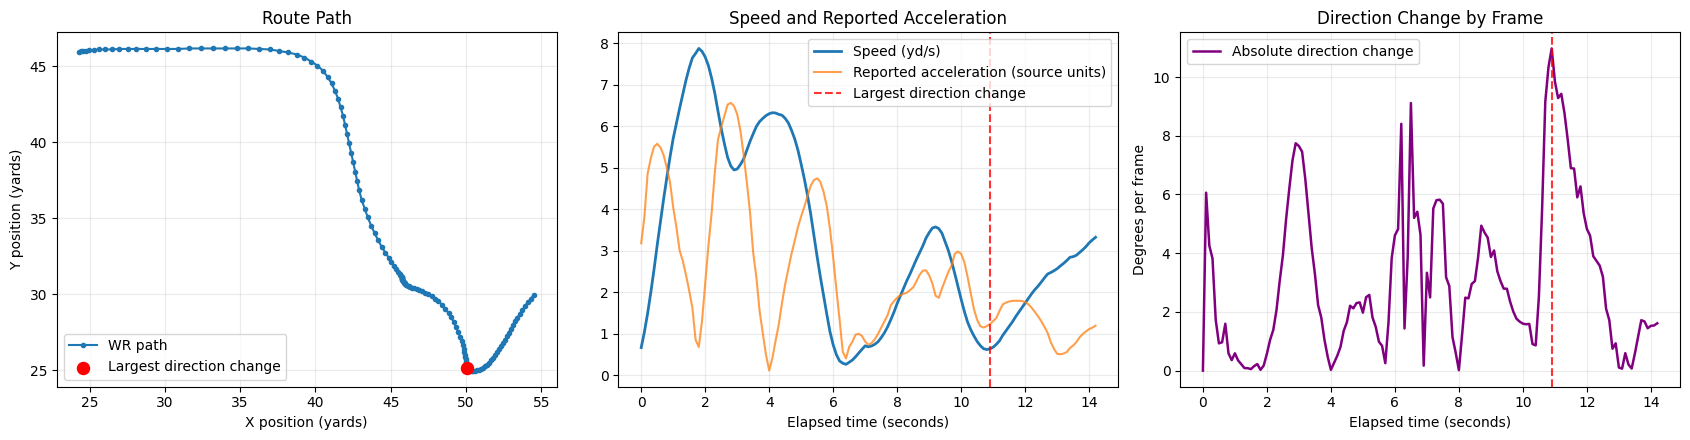


PRELIMINARY CUT FEATURE EXTRACTION
----------------------------------
Route attempts processed: 441
WRs with extracted features: 106

Attempts by drill:
drill_name
DAGGER_ROUTE_LEFT       114
SLANT_ROUTE_LEFT        109
COMEBACK_ROUTE_RIGHT    109
CURL_ROUTE_RIGHT        109

WR-level feature summary:
       n_cut_attempts  mean_break_snap_deg  mean_trough_speed_retention  \
count        106.0000             106.0000                     106.0000   
mean           4.1600              23.9590                       0.6490   
std            0.7450              13.9260                       0.0910   
min            2.0000               4.2990                       0.3560   
25%            4.0000              12.7740                       0.5980   
50%            4.0000              20.8760                       0.6370   
75%            4.0000              31.4830                       0.7070   
max            7.0000              80.4770                       0.9650   

       mean_exit_spe

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [31]:

# ============================================================
# CELL 3: EXPLORING WR CUTTING MECHANICS
# ============================================================
#
# Objective:
#   1. Visualize a representative WR route attempt.
#   2. Locate the largest frame-to-frame direction change.
#   3. Extract preliminary speed and direction-change features
#      across the selected route drills.
#
# Important interpretation notes:
#   - Tracking is sampled at approximately 10 Hz.
#   - Direction changes must account for the 0/360-degree wrap.
#   - The reported "a" field is plotted as supplied, but is NOT
#     automatically interpreted as signed braking acceleration.
#   - This is an exploratory feature extraction step. Cell 4
#     will apply stricter filters for the main analysis.
# ============================================================


# ------------------------------------------------------------
# 1. Select route drills relevant to direction changes
# ------------------------------------------------------------

BREAKING_DRILLS = [
    "DAGGER_ROUTE_LEFT",
    "SLANT_ROUTE_LEFT",
    "CURL_ROUTE_RIGHT",
    "COMEBACK_ROUTE_RIGHT",
]


# ------------------------------------------------------------
# 2. Helper function for angular differences
# ------------------------------------------------------------

def angular_diff_deg(a, b):
    """
    Calculate the smallest signed angular difference.

    The result is constrained to [-180, 180] degrees.
    This correctly handles transitions such as 359 -> 1 degrees.
    """
    return ((a - b + 180.0) % 360.0) - 180.0


# ------------------------------------------------------------
# 3. Select one complete player-drill attempt for inspection
# ------------------------------------------------------------

sample_candidates = (
    wr_player_trk[
        wr_player_trk["drill_name"] == "DAGGER_ROUTE_LEFT"
    ]
    .groupby(["nfl_id", "drill_name", "event_id"])
    .size()
    .reset_index(name="n_frames")
)

# Prefer an attempt with enough frames to visualize the movement.
sample_candidates = sample_candidates[
    sample_candidates["n_frames"] >= 12
].sort_values(
    ["n_frames", "nfl_id", "event_id"],
    ascending=[False, True, True]
)

if sample_candidates.empty:
    raise ValueError(
        "No DAGGER_ROUTE_LEFT player attempt has at least 12 frames."
    )

sample_key = sample_candidates.iloc[0]

sample_nfl_id = sample_key["nfl_id"]
sample_drill = sample_key["drill_name"]
sample_event = sample_key["event_id"]

ev_df = (
    wr_player_trk[
        (wr_player_trk["nfl_id"] == sample_nfl_id)
        & (wr_player_trk["drill_name"] == sample_drill)
        & (wr_player_trk["event_id"] == sample_event)
    ]
    .sort_values("time")
    .reset_index(drop=True)
    .copy()
)

# Calculate elapsed time from the actual timestamps.
ev_df["t_rel"] = (
    ev_df["time"] - ev_df["time"].iloc[0]
).dt.total_seconds()

# Frame-to-frame absolute direction change.
direction = ev_df["dir"].to_numpy(dtype=float)

ev_df["d_dir"] = np.concatenate(
    [
        [0.0],
        np.abs(
            angular_diff_deg(
                direction[1:],
                direction[:-1]
            )
        ),
    ]
)

# Exploratory marker: frame with the largest direction change.
cut_idx = int(ev_df["d_dir"].to_numpy().argmax())

print("REPRESENTATIVE ROUTE ATTEMPT")
print("----------------------------")
print("NFL player ID:", sample_nfl_id)
print("Drill:", sample_drill)
print("Event ID:", sample_event)
print("Tracking frames:", len(ev_df))
print(
    "Attempt duration:",
    round(ev_df["t_rel"].iloc[-1], 2),
    "seconds"
)
print(
    "Largest frame-to-frame direction change:",
    round(ev_df.loc[cut_idx, "d_dir"], 2),
    "degrees"
)


# ------------------------------------------------------------
# 4. Visualize the route and movement signals
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Panel A: Spatial path
axes[0].plot(
    ev_df["x"],
    ev_df["y"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="WR path"
)

axes[0].scatter(
    ev_df.loc[cut_idx, "x"],
    ev_df.loc[cut_idx, "y"],
    color="red",
    s=75,
    zorder=5,
    label="Largest direction change"
)

axes[0].set_title("Route Path")
axes[0].set_xlabel("X position (yards)")
axes[0].set_ylabel("Y position (yards)")
axes[0].legend()
axes[0].grid(alpha=0.25)


# Panel B: Speed and reported acceleration
axes[1].plot(
    ev_df["t_rel"],
    ev_df["s"],
    label="Speed (yd/s)",
    linewidth=2
)

axes[1].plot(
    ev_df["t_rel"],
    ev_df["a"],
    label="Reported acceleration (source units)",
    alpha=0.75
)

axes[1].axvline(
    ev_df.loc[cut_idx, "t_rel"],
    color="red",
    linestyle="--",
    alpha=0.8,
    label="Largest direction change"
)

axes[1].set_title("Speed and Reported Acceleration")
axes[1].set_xlabel("Elapsed time (seconds)")
axes[1].legend()
axes[1].grid(alpha=0.25)


# Panel C: Frame-to-frame direction change
axes[2].plot(
    ev_df["t_rel"],
    ev_df["d_dir"],
    color="purple",
    linewidth=1.8,
    label="Absolute direction change"
)

axes[2].axvline(
    ev_df.loc[cut_idx, "t_rel"],
    color="red",
    linestyle="--",
    alpha=0.8
)

axes[2].set_title("Direction Change by Frame")
axes[2].set_xlabel("Elapsed time (seconds)")
axes[2].set_ylabel("Degrees per frame")
axes[2].legend()
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Extract preliminary features for every route attempt
# ------------------------------------------------------------

attempt_rows = []

route_tracking = wr_player_trk[
    wr_player_trk["drill_name"].isin(BREAKING_DRILLS)
].copy()

for (nfl_id, drill_name, event_id), grp in route_tracking.groupby(
    ["nfl_id", "drill_name", "event_id"]
):

    g = (
        grp.sort_values("time")
        .reset_index(drop=True)
        .copy()
    )

    # Exclude attempts that are too short for a meaningful
    # pre-break and post-break comparison.
    if len(g) < 8:
        continue

    # Actual elapsed time in seconds.
    t = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds().to_numpy(dtype=float)

    s = g["s"].to_numpy(dtype=float)
    direction = g["dir"].to_numpy(dtype=float)

    # Reject malformed attempts with missing or invalid values.
    if (
        not np.isfinite(t).all()
        or not np.isfinite(s).all()
        or not np.isfinite(direction).all()
        or np.any(np.diff(t) <= 0)
    ):
        continue

    # Frame-to-frame direction change, accounting for wraparound.
    d_dir = np.concatenate(
        [
            [0.0],
            np.abs(
                angular_diff_deg(
                    direction[1:],
                    direction[:-1]
                )
            ),
        ]
    )

    # Estimate signed speed change using actual elapsed time.
    # Negative values indicate speed is decreasing.
    ds_dt = np.gradient(s, t)

    # Ignore the first few frames when searching for the
    # largest direction change, reducing sensitivity to
    # initial positioning and tracking noise.
    search_start = min(3, len(g) - 2)

    break_idx = search_start + int(
        np.argmax(d_dir[search_start:])
    )

    # Compare approximately 0.6 seconds before and after
    # the selected direction-change frame.
    pre_start = max(0, break_idx - 6)
    post_end = min(len(g), break_idx + 7)

    pre_speed = s[pre_start : break_idx + 1]
    post_speed = s[break_idx : post_end]
    pre_speed_change = ds_dt[pre_start : break_idx + 1]
    post_speed_change = ds_dt[break_idx : post_end]

    if len(pre_speed) == 0 or len(post_speed) == 0:
        continue

    entry_speed = float(np.max(pre_speed))
    minimum_post_speed = float(np.min(post_speed))
    maximum_post_speed = float(np.max(post_speed))

    # Signed speed-change estimates:
    # negative pre-break values indicate deceleration;
    # positive post-break values indicate acceleration.
    strongest_speed_drop = float(np.min(pre_speed_change))
    strongest_speed_gain = float(np.max(post_speed_change))

    attempt_rows.append(
        {
            "nfl_id": nfl_id,
            "drill_name": drill_name,
            "event_id": event_id,
            "attempt_frames": len(g),
            "attempt_duration_s": float(t[-1] - t[0]),
            "break_d_dir_deg": float(d_dir[break_idx]),
            "entry_speed": entry_speed,
            "min_post_speed": minimum_post_speed,
            "max_post_speed": maximum_post_speed,
            "trough_speed_retention": (
                minimum_post_speed / entry_speed
                if entry_speed > 0.5
                else np.nan
            ),
            "exit_speed_retention": (
                maximum_post_speed / entry_speed
                if entry_speed > 0.5
                else np.nan
            ),
            "strongest_pre_speed_change": strongest_speed_drop,
            "strongest_post_speed_change": strongest_speed_gain,
        }
    )


# ------------------------------------------------------------
# 6. Aggregate attempt-level features to the WR level
# ------------------------------------------------------------

wr_cut_attempts = pd.DataFrame(attempt_rows)

if wr_cut_attempts.empty:
    raise ValueError(
        "No valid route attempts were available for feature extraction."
    )

wr_cut_features = (
    wr_cut_attempts
    .groupby("nfl_id")
    .agg(
        n_cut_attempts=("event_id", "count"),
        mean_break_snap_deg=("break_d_dir_deg", "mean"),
        mean_trough_speed_retention=("trough_speed_retention", "mean"),
        mean_exit_speed_retention=("exit_speed_retention", "mean"),
        mean_pre_speed_change=("strongest_pre_speed_change", "mean"),
        mean_post_speed_change=("strongest_post_speed_change", "mean"),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 7. Report extraction coverage and feature distributions
# ------------------------------------------------------------

print("\nPRELIMINARY CUT FEATURE EXTRACTION")
print("----------------------------------")
print("Route attempts processed:", len(wr_cut_attempts))
print("WRs with extracted features:", wr_cut_features["nfl_id"].nunique())

print("\nAttempts by drill:")
print(
    wr_cut_attempts["drill_name"]
    .value_counts()
    .to_string()
)

print("\nWR-level feature summary:")
print(
    wr_cut_features
    .drop(columns="nfl_id")
    .describe()
    .round(3)
)

print("\nCELL 3 COMPLETED")


1. WINDOW-BASED CUT EXTRACTION
Route drills: ['DAGGER_ROUTE_LEFT', 'CURL_ROUTE_RIGHT', 'COMEBACK_ROUTE_RIGHT']
Attempts considered: 332
Attempts retained: 326
WRs represented: 106

Exclusion counts:
too_few_frames: 0
invalid_values_or_time: 0
no_valid_candidate: 0
invalid_window: 6

Retained attempts by drill:
drill_name
DAGGER_ROUTE_LEFT       114
COMEBACK_ROUTE_RIGHT    108
CURL_ROUTE_RIGHT        104

HEADING CHANGE DIAGNOSTICS
--------------------------
Attempts with at least 10 degrees: 321 (98.5%)
Attempts with at least 15 degrees: 317 (97.2%)
Attempts with at least 20 degrees: 316 (96.9%)
Attempts with at least 30 degrees: 287 (88.0%)
Attempts with at least 45 degrees: 120 (36.8%)

Attempt-level feature summary:
       attempt_duration_s  break_angle_rate  entry_speed  trough_retention  \
count            326.0000          326.0000     326.0000          326.0000   
mean               6.0340           40.5990       6.1260            0.8010   
std                1.1080           1

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


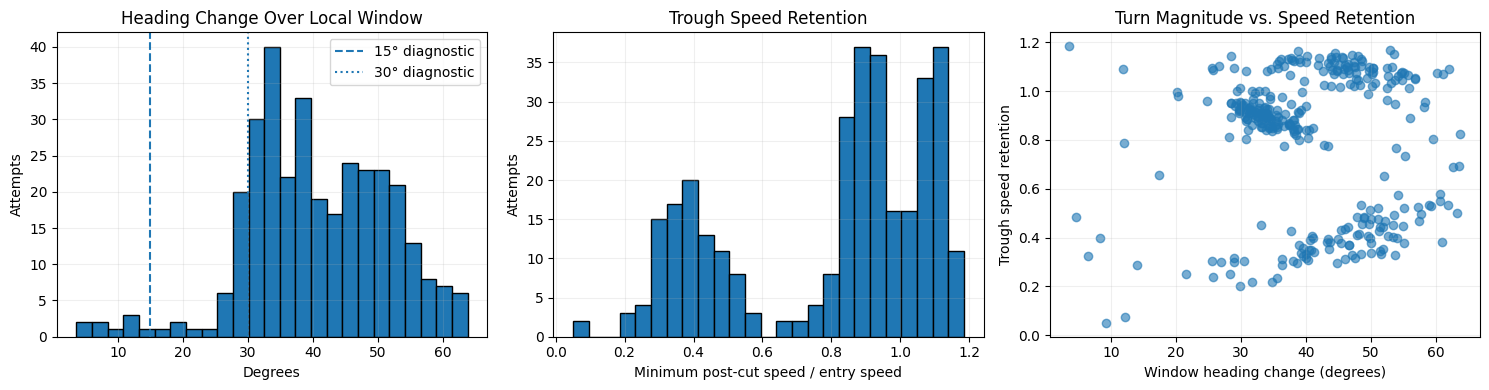


CELL 4 KINEMATICS VERSION 2 COMPLETED


In [32]:

# ============================================================
# CELL 4: REFINED CUT-CENTERED KINEMATIC FEATURES
# VERSION 2: WINDOW-BASED HEADING CHANGE
# ============================================================

SHARP_BREAK_DRILLS = [
    "DAGGER_ROUTE_LEFT",
    "CURL_ROUTE_RIGHT",
    "COMEBACK_ROUTE_RIGHT",
]

MIN_ATTEMPT_FRAMES = 12
MIN_CANDIDATE_SPEED = 4.0

# A candidate is evaluated using heading before and after it.
# At 10 Hz, 3 frames on either side span approximately 0.6 sec.
HEADING_WINDOW_FRAMES = 3

PRE_CUT_FRAMES = 5
POST_CUT_FRAMES = 6


# ------------------------------------------------------------
# 1. Prepare tracking observations
# ------------------------------------------------------------

sharp_tracking = wr_player_trk[
    wr_player_trk["drill_name"].isin(SHARP_BREAK_DRILLS)
].copy()

sharp_tracking = sharp_tracking.sort_values(
    ["nfl_id", "drill_name", "event_id", "time"]
)


# ------------------------------------------------------------
# 2. Extract window-based cut features
# ------------------------------------------------------------

cut_attempt_rows = []

cut_exclusion_counts = {
    "too_few_frames": 0,
    "invalid_values_or_time": 0,
    "no_valid_candidate": 0,
    "invalid_window": 0,
}

for (nfl_id, drill_name, event_id), grp in sharp_tracking.groupby(
    ["nfl_id", "drill_name", "event_id"]
):

    g = (
        grp.sort_values("time")
        .reset_index(drop=True)
        .copy()
    )

    if len(g) < MIN_ATTEMPT_FRAMES:
        cut_exclusion_counts["too_few_frames"] += 1
        continue

    t = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds().to_numpy(dtype=float)

    speed = g["s"].to_numpy(dtype=float)
    direction = g["dir"].to_numpy(dtype=float)
    reported_a = g["a"].to_numpy(dtype=float)

    if (
        not np.isfinite(t).all()
        or not np.isfinite(speed).all()
        or not np.isfinite(direction).all()
        or not np.isfinite(reported_a).all()
        or np.any(np.diff(t) <= 0)
    ):
        cut_exclusion_counts["invalid_values_or_time"] += 1
        continue

    # Estimate speed change in yd/s^2.
    speed_change = np.gradient(speed, t)

    # --------------------------------------------------------
    # Calculate net heading change over a local time window.
    # --------------------------------------------------------

    window_turn = np.full(len(g), np.nan)

    for i in range(
        HEADING_WINDOW_FRAMES,
        len(g) - HEADING_WINDOW_FRAMES
    ):
        before_heading = direction[i - HEADING_WINDOW_FRAMES]
        after_heading = direction[i + HEADING_WINDOW_FRAMES]

        window_turn[i] = abs(
            angular_diff_deg(after_heading, before_heading)
        )

    # Candidate frames must have sufficient speed and a complete
    # heading window.
    candidate_idx = np.arange(
        HEADING_WINDOW_FRAMES,
        len(g) - HEADING_WINDOW_FRAMES
    )

    candidate_idx = candidate_idx[
        (speed[candidate_idx] >= MIN_CANDIDATE_SPEED)
        & np.isfinite(window_turn[candidate_idx])
    ]

    if len(candidate_idx) == 0:
        cut_exclusion_counts["no_valid_candidate"] += 1
        continue

    # Select the largest net heading change over the window.
    break_idx = int(
        candidate_idx[
            np.argmax(window_turn[candidate_idx])
        ]
    )

    # --------------------------------------------------------
    # Pre-cut and post-cut speed windows
    # --------------------------------------------------------

    pre_start = break_idx - PRE_CUT_FRAMES
    pre_end = break_idx

    post_start = break_idx
    post_end = break_idx + POST_CUT_FRAMES

    if pre_start < 0 or post_end > len(g):
        cut_exclusion_counts["invalid_window"] += 1
        continue

    pre_speed = speed[pre_start:pre_end]
    post_speed = speed[post_start:post_end]

    pre_speed_change = speed_change[pre_start:pre_end]
    post_speed_change = speed_change[post_start:post_end]

    if (
        len(pre_speed) != PRE_CUT_FRAMES
        or len(post_speed) != POST_CUT_FRAMES
    ):
        cut_exclusion_counts["invalid_window"] += 1
        continue

    entry_speed = float(np.max(pre_speed))
    trough_speed = float(np.min(post_speed))
    exit_speed = float(np.max(post_speed))

    if entry_speed <= 0.5:
        cut_exclusion_counts["invalid_window"] += 1
        continue

    # Negative = speed decreasing.
    true_braking_decel = float(np.min(pre_speed_change))

    # Positive = speed increasing.
    true_exit_reaccel = float(np.max(post_speed_change))

    cut_a_window = reported_a[pre_start:post_end]

    cut_attempt_rows.append(
        {
            "nfl_id": nfl_id,
            "drill_name": drill_name,
            "event_id": event_id,
            "attempt_frames": len(g),
            "attempt_duration_s": float(t[-1] - t[0]),
            "cut_time_s": float(t[break_idx]),
            "break_angle_rate": float(window_turn[break_idx]),
            "entry_speed": entry_speed,
            "trough_speed": trough_speed,
            "exit_speed": exit_speed,
            "trough_retention": trough_speed / entry_speed,
            "exit_retention": exit_speed / entry_speed,
            "true_braking_decel": true_braking_decel,
            "true_exit_reaccel": true_exit_reaccel,
            "peak_cut_total_a": float(np.max(cut_a_window)),
        }
    )


# ------------------------------------------------------------
# 3. Build attempt-level and player-level data
# ------------------------------------------------------------

wr_cut_attempts = pd.DataFrame(cut_attempt_rows)

if wr_cut_attempts.empty:
    raise ValueError(
        "No attempts passed the window-based cut extraction."
    )

wr_kinematics = (
    wr_cut_attempts
    .groupby("nfl_id")
    .agg(
        n_cut_attempts=("event_id", "count"),
        break_angle_rate=("break_angle_rate", "mean"),
        trough_retention=("trough_retention", "mean"),
        exit_retention=("exit_retention", "mean"),
        true_braking_decel=("true_braking_decel", "mean"),
        true_exit_reaccel=("true_exit_reaccel", "mean"),
        peak_cut_total_a=("peak_cut_total_a", "mean"),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. Report extraction quality
# ------------------------------------------------------------

print("=" * 65)
print("1. WINDOW-BASED CUT EXTRACTION")
print("=" * 65)

print("Route drills:", SHARP_BREAK_DRILLS)

print(
    "Attempts considered:",
    sharp_tracking.groupby(
        ["nfl_id", "drill_name", "event_id"]
    ).ngroups
)

print("Attempts retained:", len(wr_cut_attempts))
print("WRs represented:", wr_kinematics["nfl_id"].nunique())

print("\nExclusion counts:")
for reason, count in cut_exclusion_counts.items():
    print(f"{reason}: {count}")

print("\nRetained attempts by drill:")
print(wr_cut_attempts["drill_name"].value_counts().to_string())


# ------------------------------------------------------------
# 5. Diagnose the selected heading changes
# ------------------------------------------------------------

print("\nHEADING CHANGE DIAGNOSTICS")
print("--------------------------")

for threshold in [10, 15, 20, 30, 45]:
    n = (
        wr_cut_attempts["break_angle_rate"] >= threshold
    ).sum()

    pct = 100 * n / len(wr_cut_attempts)

    print(
        f"Attempts with at least {threshold:2d} degrees: "
        f"{n:3d} ({pct:.1f}%)"
    )

print("\nAttempt-level feature summary:")
print(
    wr_cut_attempts[
        [
            "attempt_duration_s",
            "break_angle_rate",
            "entry_speed",
            "trough_retention",
            "exit_retention",
            "true_braking_decel",
            "true_exit_reaccel",
            "peak_cut_total_a",
        ]
    ].describe().round(3)
)

print("\nPlayer-level feature summary:")
print(
    wr_kinematics
    .drop(columns="nfl_id")
    .describe()
    .round(3)
)


# ------------------------------------------------------------
# 6. Visualize the new distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(
    wr_cut_attempts["break_angle_rate"],
    bins=25,
    edgecolor="black"
)
axes[0].axvline(15, linestyle="--", label="15° diagnostic")
axes[0].axvline(30, linestyle=":", label="30° diagnostic")
axes[0].set_title("Heading Change Over Local Window")
axes[0].set_xlabel("Degrees")
axes[0].set_ylabel("Attempts")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].hist(
    wr_cut_attempts["trough_retention"],
    bins=25,
    edgecolor="black"
)
axes[1].set_title("Trough Speed Retention")
axes[1].set_xlabel("Minimum post-cut speed / entry speed")
axes[1].set_ylabel("Attempts")
axes[1].grid(alpha=0.2)

axes[2].scatter(
    wr_cut_attempts["break_angle_rate"],
    wr_cut_attempts["trough_retention"],
    alpha=0.6
)
axes[2].set_title("Turn Magnitude vs. Speed Retention")
axes[2].set_xlabel("Window heading change (degrees)")
axes[2].set_ylabel("Trough speed retention")
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("\nCELL 4 KINEMATICS VERSION 2 COMPLETED")


CUT FEATURE SUMMARY BY DRILL
                      attempts  mean_heading_change  median_heading_change  mean_trough_retention  median_trough_retention  mean_braking  median_braking
drill_name                                                                                                                                              
COMEBACK_ROUTE_RIGHT       108              43.8690                47.2360                 0.6460                   0.4940       -3.8170         -5.6670
CURL_ROUTE_RIGHT           104              44.4890                45.9220                 0.8550                   1.0500       -1.6140         -0.5620
DAGGER_ROUTE_LEFT          114              33.9530                33.6180                 0.8970                   0.8970       -1.9990         -2.0250


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


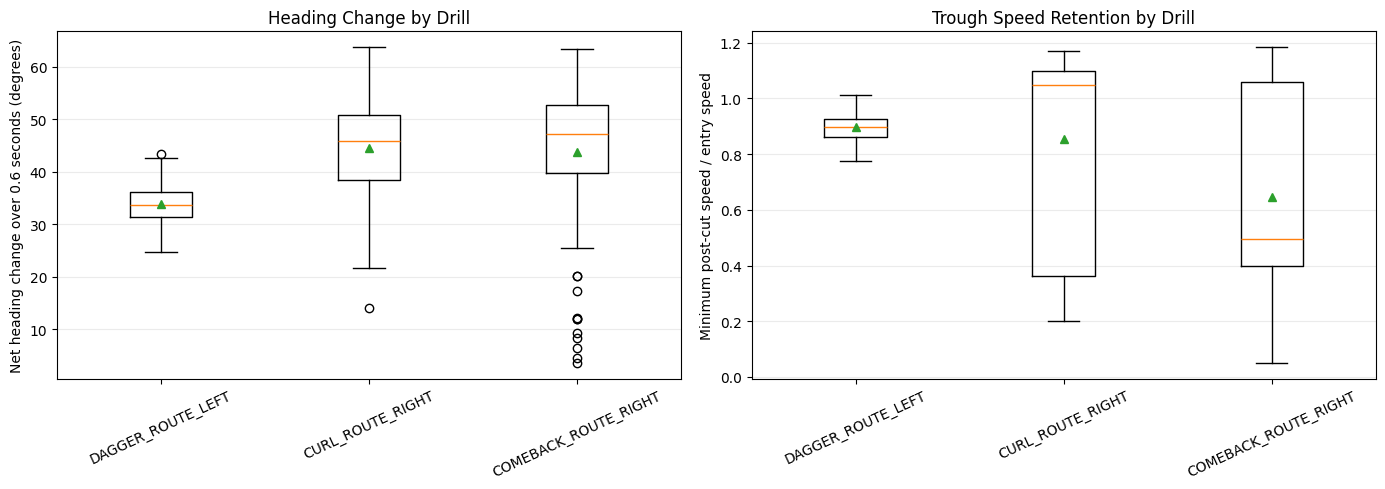

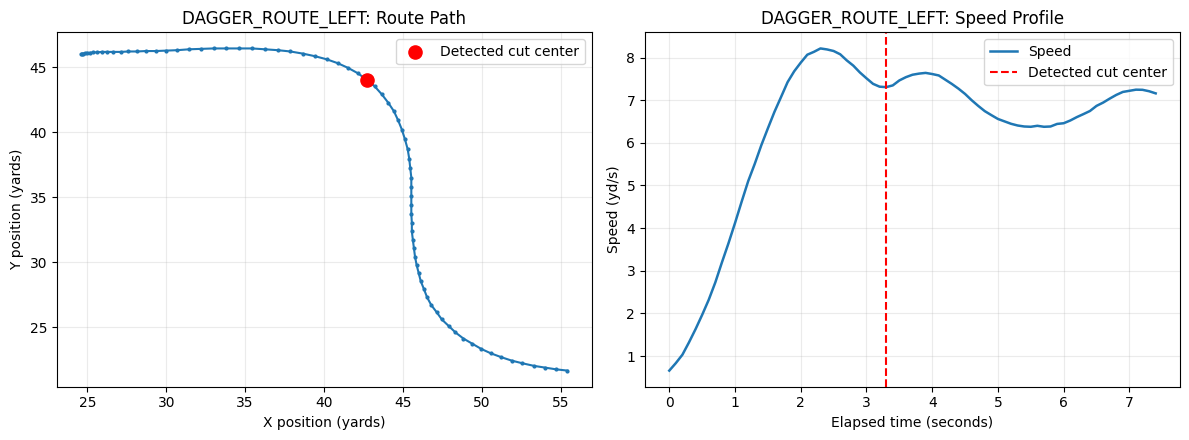

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


DAGGER_ROUTE_LEFT: NFL ID=57221, event=20240302100700_1709414078866_000, heading change=33.65°, trough retention=0.936


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


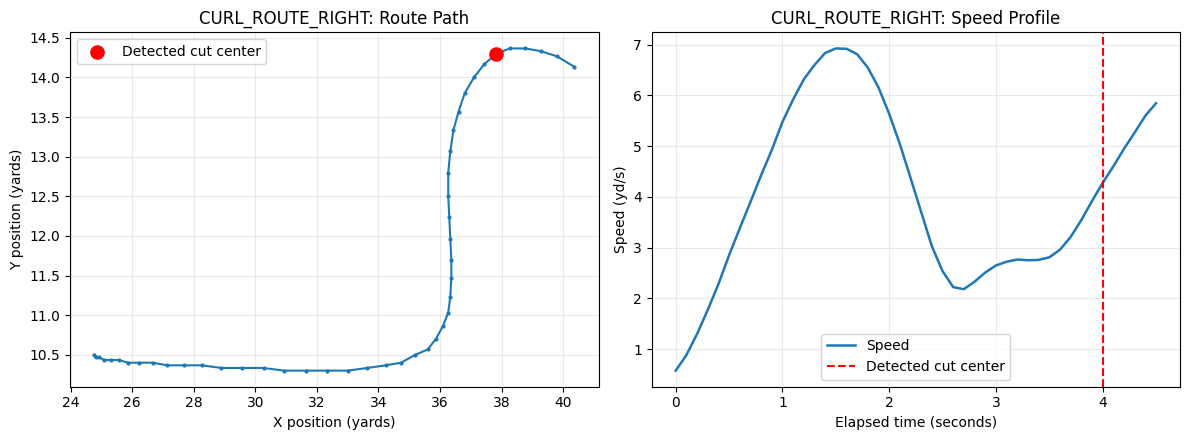

CURL_ROUTE_RIGHT: NFL ID=55934, event=6414e5fde3d8e72dcdc8d42f-2023, heading change=45.86°, trough retention=1.091


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


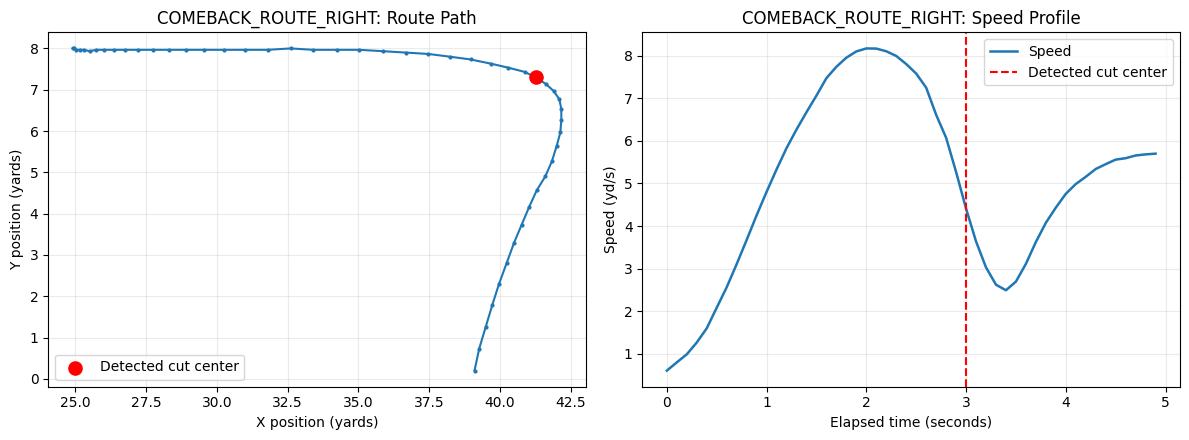

COMEBACK_ROUTE_RIGHT: NFL ID=57223, event=20240302100700_1709415889162_000, heading change=47.10°, trough retention=0.329

CELL 4B COMPLETED


In [33]:

# ============================================================
# CELL 4B: VALIDATING THE WINDOW-BASED CUT DETECTOR
# ============================================================

# Correct the feature name: this is an angle over a window,
# not an angular rate.
wr_cut_attempts = wr_cut_attempts.rename(
    columns={
        "break_angle_rate": "window_heading_change_deg"
    }
)

wr_kinematics = wr_kinematics.rename(
    columns={
        "break_angle_rate": "window_heading_change_deg"
    }
)

# ------------------------------------------------------------
# 1. Compare cut features across route drills
# ------------------------------------------------------------

drill_summary = (
    wr_cut_attempts
    .groupby("drill_name")
    .agg(
        attempts=("event_id", "count"),
        mean_heading_change=("window_heading_change_deg", "mean"),
        median_heading_change=("window_heading_change_deg", "median"),
        mean_trough_retention=("trough_retention", "mean"),
        median_trough_retention=("trough_retention", "median"),
        mean_braking=("true_braking_decel", "mean"),
        median_braking=("true_braking_decel", "median"),
    )
    .round(3)
)

print("CUT FEATURE SUMMARY BY DRILL")
print("=" * 65)
print(drill_summary.to_string())


# ------------------------------------------------------------
# 2. Examine the distribution of heading change by drill
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

drill_order = SHARP_BREAK_DRILLS

heading_data = [
    wr_cut_attempts.loc[
        wr_cut_attempts["drill_name"] == drill,
        "window_heading_change_deg"
    ].dropna().to_numpy()
    for drill in drill_order
]

axes[0].boxplot(
    heading_data,
    tick_labels=drill_order,
    showmeans=True
)
axes[0].set_title("Heading Change by Drill")
axes[0].set_ylabel("Net heading change over 0.6 seconds (degrees)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.25)

retention_data = [
    wr_cut_attempts.loc[
        wr_cut_attempts["drill_name"] == drill,
        "trough_retention"
    ].dropna().to_numpy()
    for drill in drill_order
]

axes[1].boxplot(
    retention_data,
    tick_labels=drill_order,
    showmeans=True
)
axes[1].set_title("Trough Speed Retention by Drill")
axes[1].set_ylabel("Minimum post-cut speed / entry speed")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot a median-like representative attempt from each drill
# ------------------------------------------------------------

for drill in SHARP_BREAK_DRILLS:

    drill_attempts = wr_cut_attempts[
        wr_cut_attempts["drill_name"] == drill
    ].copy()

    if drill_attempts.empty:
        continue

    drill_median = drill_attempts[
        "window_heading_change_deg"
    ].median()

    # Choose the attempt closest to the drill's median
    # heading change, rather than selecting the longest attempt.
    representative = drill_attempts.loc[
        (
            drill_attempts["window_heading_change_deg"]
            - drill_median
        ).abs().idxmin()
    ]

    nfl_id = representative["nfl_id"]
    event_id = representative["event_id"]

    g = (
        wr_player_trk[
            (wr_player_trk["nfl_id"] == nfl_id)
            & (wr_player_trk["drill_name"] == drill)
            & (wr_player_trk["event_id"] == event_id)
        ]
        .sort_values("time")
        .reset_index(drop=True)
        .copy()
    )

    t = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds()

    cut_time = representative["cut_time_s"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Spatial route
    axes[0].plot(
        g["x"],
        g["y"],
        marker=".",
        markersize=4,
        linewidth=1.5
    )

    cut_idx = (
        (t - cut_time).abs()
    ).idxmin()

    axes[0].scatter(
        g.loc[cut_idx, "x"],
        g.loc[cut_idx, "y"],
        color="red",
        s=90,
        label="Detected cut center",
        zorder=5
    )

    axes[0].set_title(f"{drill}: Route Path")
    axes[0].set_xlabel("X position (yards)")
    axes[0].set_ylabel("Y position (yards)")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    # Speed profile
    axes[1].plot(
        t,
        g["s"],
        linewidth=1.8,
        label="Speed"
    )

    axes[1].axvline(
        cut_time,
        color="red",
        linestyle="--",
        label="Detected cut center"
    )

    axes[1].set_title(f"{drill}: Speed Profile")
    axes[1].set_xlabel("Elapsed time (seconds)")
    axes[1].set_ylabel("Speed (yd/s)")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    print(
        f"{drill}: NFL ID={nfl_id}, "
        f"event={event_id}, "
        f"heading change={representative['window_heading_change_deg']:.2f}°, "
        f"trough retention={representative['trough_retention']:.3f}"
    )


print("\nCELL 4B COMPLETED")


1. SEPARATION AND CONTEXT DATA AVAILABILITY

separation_at_pass_forward
--------------------------------------------------
Missing: 4323
Missing %: 12.39
Unique values: 22169
count   30566.0000
mean        3.1050
std         2.1120
min         0.1500
25%         1.4010
50%         2.6210
75%         4.3080
max        17.7160
Name: separation_at_pass_forward, dtype: float64

lined_up_position
--------------------------------------------------
Missing: 0
Missing %: 0.0
Unique values: 6
lined_up_position
WR         21543
SLOT_WR    12255
TE           882
RB           175
FB            33
T              1
Name: count, dtype: int64

route_ran
--------------------------------------------------
Missing: 0
Missing %: 0.0
Unique values: 12
route_ran
GO        6752
HITCH     5640
CROSS     4406
IN        3984
POST      3621
OUT       3349
CORNER    2912
SLANT     2255
SCREEN     969
FLAT       931
WHEEL       51
ANGLE       19
Name: count, dtype: int64

team_coverage_man_zone
-------------------

/tmp/ipykernel_49/2339383574.py:64: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


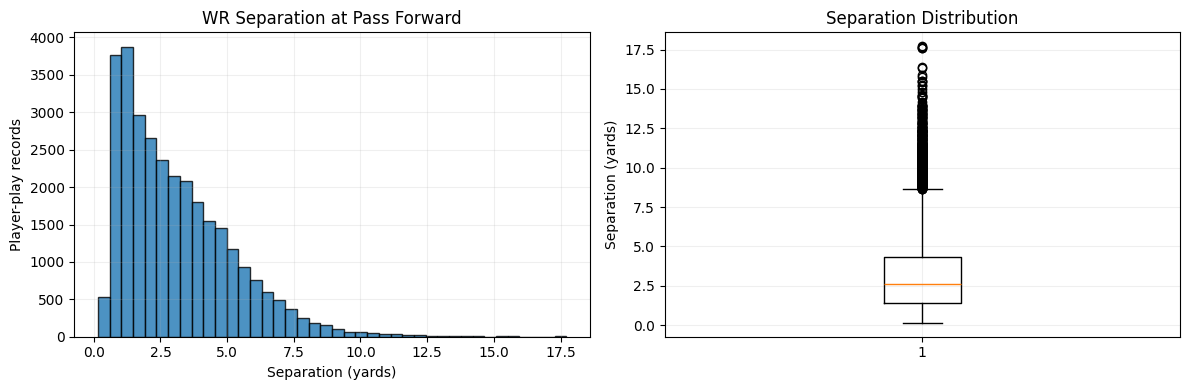


DISTRIBUTION: lined_up_position
lined_up_position
WR         21543
SLOT_WR    12255
TE           882
RB           175
FB            33
T              1

DISTRIBUTION: route_ran
route_ran
GO        6752
HITCH     5640
CROSS     4406
IN        3984
POST      3621
OUT       3349
CORNER    2912
SLANT     2255
SCREEN     969
FLAT       931
WHEEL       51
ANGLE       19

DISTRIBUTION: team_coverage_man_zone
team_coverage_man_zone
ZONE_COVERAGE    25244
MAN_COVERAGE      9632
NaN                 13

DISTRIBUTION: in_motion_at_ball_snap
in_motion_at_ball_snap
False    32340
True      2539
NaN         10

CUSHION DISTRIBUTION
count   33116.0000
mean        6.1260
std         2.9820
min         1.0900
1%          1.6500
5%          1.9700
25%         3.1800
50%         6.2800
75%         8.5300
95%        10.7400
99%        12.5800
max        20.2800
Name: cushion, dtype: float64

CELL 4C COMPLETED


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [34]:

# ============================================================
# CELL 4C: AUDITING SEPARATION AND PLAY CONTEXT
# ============================================================

context_columns = [
    "separation_at_pass_forward",
    "lined_up_position",
    "route_ran",
    "team_coverage_man_zone",
    "cushion",
    "in_motion_at_ball_snap",
    "target",
]

print("=" * 70)
print("1. SEPARATION AND CONTEXT DATA AVAILABILITY")
print("=" * 70)

for col in context_columns:
    if col not in wr_plays.columns:
        print(f"\n{col}: COLUMN NOT FOUND")
        continue

    print(f"\n{col}")
    print("-" * 50)
    print("Missing:", wr_plays[col].isna().sum())
    print("Missing %:", round(100 * wr_plays[col].isna().mean(), 2))
    print("Unique values:", wr_plays[col].nunique())

    if wr_plays[col].nunique() <= 30:
        print(wr_plays[col].value_counts(dropna=False).head(30))
    elif pd.api.types.is_numeric_dtype(wr_plays[col]):
        print(wr_plays[col].describe().round(3))


# ------------------------------------------------------------
# 2. Inspect the separation outcome distribution
# ------------------------------------------------------------

sep = pd.to_numeric(
    wr_plays["separation_at_pass_forward"],
    errors="coerce"
)

print("\n" + "=" * 70)
print("2. SEPARATION DISTRIBUTION")
print("=" * 70)

print(sep.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    sep.dropna(),
    bins=40,
    edgecolor="black",
    alpha=0.8
)
axes[0].set_title("WR Separation at Pass Forward")
axes[0].set_xlabel("Separation (yards)")
axes[0].set_ylabel("Player-play records")
axes[0].grid(alpha=0.2)

axes[1].boxplot(
    sep.dropna(),
    vert=True
)
axes[1].set_title("Separation Distribution")
axes[1].set_ylabel("Separation (yards)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Check whether route and coverage categories are usable
# ------------------------------------------------------------

for col in [
    "lined_up_position",
    "route_ran",
    "team_coverage_man_zone",
    "in_motion_at_ball_snap",
]:

    if col not in wr_plays.columns:
        continue

    print("\n" + "=" * 70)
    print(f"DISTRIBUTION: {col}")
    print("=" * 70)

    print(
        wr_plays[col]
        .value_counts(dropna=False)
        .head(25)
        .to_string()
    )


# ------------------------------------------------------------
# 4. Check cushion as a numeric contextual variable
# ------------------------------------------------------------

if "cushion" in wr_plays.columns:

    cushion_numeric = pd.to_numeric(
        wr_plays["cushion"],
        errors="coerce"
    )

    print("\n" + "=" * 70)
    print("CUSHION DISTRIBUTION")
    print("=" * 70)

    print(
        cushion_numeric.describe(
            percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
        ).round(3)
    )


print("\nCELL 4C COMPLETED")


SEPARATION ANALYSIS SAMPLE
Eligible WR/SLOT_WR records: 29,581
Unique players: 82
Targeted records: 6,186 (20.9%)
Non-targeted records: 23,395
Cushion median used for imputation: 6.29 yards


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



CONTEXT MODEL DIAGNOSTICS
Model observations: 29,581
R-squared: 0.2458
Adjusted R-squared: 0.2454
Residual standard deviation: 1.819 yards

PLAYER-LEVEL SEPARATION SUMMARY
Players with measured separation: 82
Players with at least 15 plays: 77

Player-level separation distributions:
       n_separation_plays  raw_sep_mean  adjusted_sep_mean  n_targeted_plays  \
count             77.0000       77.0000            77.0000           77.0000   
mean             383.7530        3.1040             3.1100           80.2600   
std              346.7620        0.4040             0.2260           86.1400   
min               17.0000        2.1790             2.7280            0.0000   
25%              137.0000        2.8460             2.9640           19.0000   
50%              252.0000        3.0030             3.1110           42.0000   
75%              596.0000        3.3220             3.2600          121.0000   
max             1324.0000        5.0190             3.9990          393.000

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


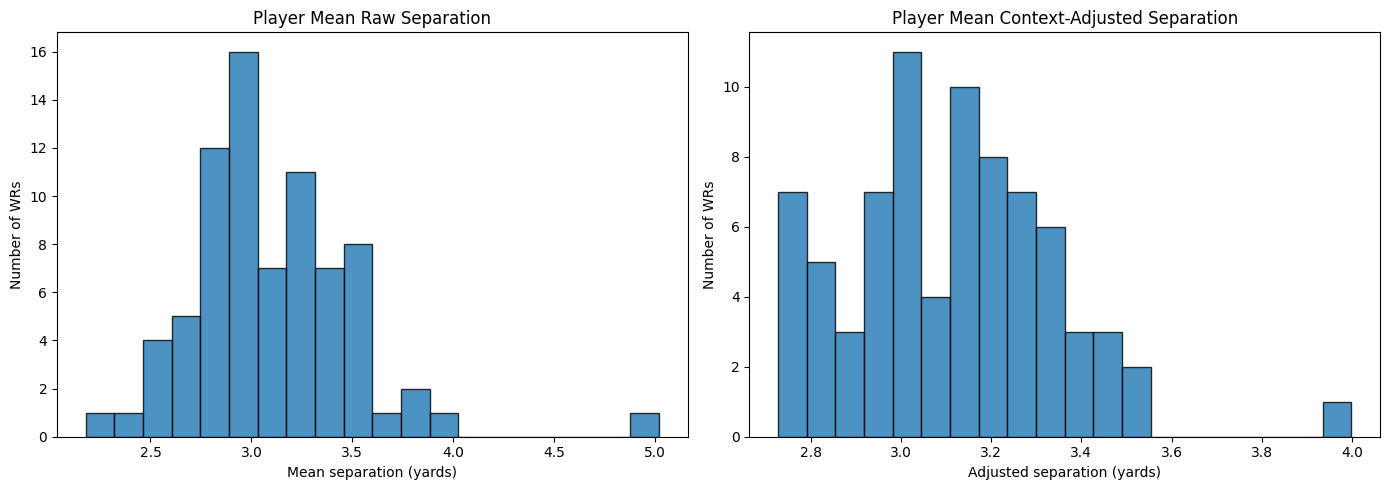


Largest changes in ranking after context adjustment:
 nfl_id  n_separation_plays  raw_sep_mean  adjusted_sep_mean  target_raw_sep_mean  target_adjusted_sep_mean  raw_rank  adjusted_rank  rank_change
  57231             30.0000        2.8450             3.3390               1.8970                    2.7430   59.0000        10.0000      49.0000
  58968             17.0000        3.3250             2.8410               3.6760                    3.0690   19.0000        67.0000     -48.0000
  58308            328.0000        3.4070             2.9520               4.0830                    3.0060   15.0000        59.0000     -44.0000
  58363             60.0000        2.8040             3.2180               3.3770                    3.4430   65.0000        27.0000      38.0000
  58274            142.0000        2.9220             3.2700               2.4630                    3.0570   51.0000        18.0000      33.0000
  57565            167.0000        3.1650             2.8460          

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [35]:

# ============================================================
# CELL 5 — BUILD CONTEXT-ADJUSTED WR SEPARATION OUTCOMES
# ============================================================
#
# Objective:
#   1. Restrict the primary analysis to WR and SLOT_WR alignments.
#   2. Retain both targeted and non-targeted plays in the main sample.
#   3. Adjust separation for observable play context.
#   4. Build player-level raw and adjusted separation metrics.
#   5. Build a target-only sensitivity analysis.
#
# Important interpretation:
#   These are descriptive, context-adjusted associations.
#   They do not establish that combine performance or route
#   technique causes a player to generate more separation.
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# ------------------------------------------------------------
# 1. Prepare the separation-analysis sample
# ------------------------------------------------------------

required_columns = [
    "nfl_id",
    "separation_at_pass_forward",
    "lined_up_position",
    "route_ran",
    "team_coverage_man_zone",
    "cushion",
    "in_motion_at_ball_snap",
    "target",
]

missing_columns = [
    col for col in required_columns
    if col not in wr_plays.columns
]

if missing_columns:
    raise KeyError(
        f"Required columns missing from wr_plays: {missing_columns}"
    )

sep_plays = wr_plays[required_columns].copy()

# Keep conventional wide-receiver alignments for the primary analysis.
sep_plays = sep_plays[
    sep_plays["lined_up_position"].isin(["WR", "SLOT_WR"])
].copy()

# Convert the outcome and cushion to numeric values.
sep_plays["separation_at_pass_forward"] = pd.to_numeric(
    sep_plays["separation_at_pass_forward"],
    errors="coerce"
)

sep_plays["cushion"] = pd.to_numeric(
    sep_plays["cushion"],
    errors="coerce"
)

# The outcome must be observed.
sep_plays = sep_plays.dropna(
    subset=["nfl_id", "separation_at_pass_forward"]
).copy()

# Normalize categorical variables and preserve missingness explicitly.
categorical_columns = [
    "lined_up_position",
    "route_ran",
    "team_coverage_man_zone",
    "in_motion_at_ball_snap",
]

for col in categorical_columns:
    sep_plays[col] = (
        sep_plays[col]
        .astype("string")
        .fillna("UNKNOWN")
        .astype(str)
    )

# Cushion: median imputation plus a missingness indicator.
# This retains observations with a measured separation but
# an unavailable cushion value.
sep_plays["cushion_missing"] = sep_plays["cushion"].isna().astype(int)

cushion_median = sep_plays["cushion"].median()

sep_plays["cushion_model"] = sep_plays["cushion"].fillna(
    cushion_median
)

# Standardize the target flag.
sep_plays["target_flag"] = (
    sep_plays["target"]
    .astype("string")
    .str.lower()
    .map({"true": 1, "false": 0})
)

if sep_plays["target_flag"].isna().any():
    raise ValueError("Unexpected or missing values found in target.")

sep_plays["target_flag"] = sep_plays["target_flag"].astype(int)

print("=" * 65)
print("SEPARATION ANALYSIS SAMPLE")
print("=" * 65)

print(f"Eligible WR/SLOT_WR records: {len(sep_plays):,}")
print(f"Unique players: {sep_plays['nfl_id'].nunique():,}")
print(
    "Targeted records:",
    f"{sep_plays['target_flag'].sum():,}",
    f"({sep_plays['target_flag'].mean():.1%})"
)
print(
    "Non-targeted records:",
    f"{(1 - sep_plays['target_flag']).sum():,}"
)
print(f"Cushion median used for imputation: {cushion_median:.2f} yards")

# ------------------------------------------------------------
# 2. Fit the context-adjustment model
# ------------------------------------------------------------
#
# The model estimates expected separation using:
#   - Route type
#   - Coverage type
#   - WR alignment (outside or slot)
#   - Pre-snap motion
#   - Defensive cushion
#   - Whether cushion was missing
#
# We intentionally do not include player identity here.
# Player-level differences are retained in the adjusted outcome.
#
# Adjusted separation =
#   observed separation - predicted separation + mean predicted
#
# This preserves the overall scale in yards while removing
# the modeled contribution of observed context.

context_formula = (
    "separation_at_pass_forward ~ "
    "C(route_ran) + "
    "C(team_coverage_man_zone) + "
    "C(lined_up_position) + "
    "C(in_motion_at_ball_snap) + "
    "cushion_model + "
    "cushion_missing"
)

context_model = smf.ols(
    formula=context_formula,
    data=sep_plays
).fit()

sep_plays["predicted_context_separation"] = context_model.predict(
    sep_plays
)

mean_predicted_separation = (
    sep_plays["predicted_context_separation"].mean()
)

sep_plays["adjusted_separation"] = (
    sep_plays["separation_at_pass_forward"]
    - sep_plays["predicted_context_separation"]
    + mean_predicted_separation
)

print("\n" + "=" * 65)
print("CONTEXT MODEL DIAGNOSTICS")
print("=" * 65)

print(f"Model observations: {int(context_model.nobs):,}")
print(f"R-squared: {context_model.rsquared:.4f}")
print(f"Adjusted R-squared: {context_model.rsquared_adj:.4f}")
print(
    "Residual standard deviation:",
    f"{np.sqrt(context_model.mse_resid):.3f} yards"
)

# ------------------------------------------------------------
# 3. Aggregate to player level
# ------------------------------------------------------------

def summarize_separation(group):
    """Create raw and context-adjusted separation summaries."""

    target_group = group[group["target_flag"] == 1]

    return pd.Series({
        "n_separation_plays": len(group),
        "n_targeted_plays": len(target_group),

        "raw_sep_mean": group[
            "separation_at_pass_forward"
        ].mean(),

        "adjusted_sep_mean": group[
            "adjusted_separation"
        ].mean(),

        "target_raw_sep_mean": (
            target_group["separation_at_pass_forward"].mean()
            if len(target_group) else np.nan
        ),

        "target_adjusted_sep_mean": (
            target_group["adjusted_separation"].mean()
            if len(target_group) else np.nan
        ),

        "cushion_missing_rate": group[
            "cushion_missing"
        ].mean(),
    })


wr_separation = (
    sep_plays
    .groupby("nfl_id")
    .apply(summarize_separation, include_groups=False)
    .reset_index()
)

# ------------------------------------------------------------
# 4. Create the primary analysis cohort
# ------------------------------------------------------------
#
# A minimum of 15 measured separation plays is used as an
# initial reliability screen. We will inspect the sensitivity
# of results to this threshold later.

MIN_SEPARATION_PLAYS = 15

wr_separation["eligible_separation_sample"] = (
    wr_separation["n_separation_plays"]
    >= MIN_SEPARATION_PLAYS
)

wr_separation_eval = wr_separation[
    wr_separation["eligible_separation_sample"]
].copy()

print("\n" + "=" * 65)
print("PLAYER-LEVEL SEPARATION SUMMARY")
print("=" * 65)

print(f"Players with measured separation: {len(wr_separation):,}")
print(
    f"Players with at least {MIN_SEPARATION_PLAYS} plays:",
    f"{len(wr_separation_eval):,}"
)

print("\nPlayer-level separation distributions:")
print(
    wr_separation_eval[
        [
            "n_separation_plays",
            "raw_sep_mean",
            "adjusted_sep_mean",
            "n_targeted_plays",
            "target_raw_sep_mean",
            "target_adjusted_sep_mean",
        ]
    ].describe().round(3)
)

# ------------------------------------------------------------
# 5. Inspect raw versus adjusted separation
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    wr_separation_eval["raw_sep_mean"].dropna(),
    bins=20,
    edgecolor="black",
    alpha=0.8
)
axes[0].set_title("Player Mean Raw Separation")
axes[0].set_xlabel("Mean separation (yards)")
axes[0].set_ylabel("Number of WRs")

axes[1].hist(
    wr_separation_eval["adjusted_sep_mean"].dropna(),
    bins=20,
    edgecolor="black",
    alpha=0.8
)
axes[1].set_title("Player Mean Context-Adjusted Separation")
axes[1].set_xlabel("Adjusted separation (yards)")
axes[1].set_ylabel("Number of WRs")

plt.tight_layout()
plt.show()

# Compare raw and adjusted player-level rankings.
rank_comparison = wr_separation_eval[
    [
        "nfl_id",
        "n_separation_plays",
        "raw_sep_mean",
        "adjusted_sep_mean",
        "target_raw_sep_mean",
        "target_adjusted_sep_mean",
    ]
].copy()

rank_comparison["raw_rank"] = (
    rank_comparison["raw_sep_mean"]
    .rank(ascending=False, method="average")
)

rank_comparison["adjusted_rank"] = (
    rank_comparison["adjusted_sep_mean"]
    .rank(ascending=False, method="average")
)

rank_comparison["rank_change"] = (
    rank_comparison["raw_rank"]
    - rank_comparison["adjusted_rank"]
)

print("\nLargest changes in ranking after context adjustment:")
print(
    rank_comparison
    .sort_values("rank_change", key=abs, ascending=False)
    .head(10)
    .round(3)
    .to_string(index=False)
)

print("\nCorrelation between raw and adjusted player separation:")
print(
    rank_comparison[
        ["raw_sep_mean", "adjusted_sep_mean"]
    ].corr().round(3)
)

print("\nCell 5 completed.")


In [36]:

# ============================================================
# CELL 6 — ASSEMBLE THE MAIN PLAYER-LEVEL ANALYSIS DATASET
# ============================================================
#
# Objective:
#   Join:
#     1. Combine testing and player information
#     2. Player-level separation outcomes
#     3. Drill-specific route-cut kinematics
#
# Key design decision:
#   Dagger, Curl, and Comeback mechanics remain separate.
#   These drills represent different route demands and should
#   not automatically be treated as interchangeable measures.
#
# The result is one row per NFL player ID.
# ============================================================

# ------------------------------------------------------------
# 1. Define and validate the input data
# ------------------------------------------------------------

required_inputs = {
    "wr_cohort": wr_cohort,
    "wr_separation": wr_separation,
    "wr_cut_attempts": wr_cut_attempts,
}

for name, frame in required_inputs.items():
    if "nfl_id" not in frame.columns:
        raise KeyError(f"{name} does not contain nfl_id.")

    if frame["nfl_id"].duplicated().any() and name != "wr_cut_attempts":
        raise ValueError(
            f"{name} should have one row per player, "
            "but duplicate nfl_id values were found."
        )

required_kinematic_columns = [
    "nfl_id",
    "event_id",
    "drill_name",
    "window_heading_change_deg",
    "trough_retention",
    "exit_retention",
    "true_braking_decel",
    "true_exit_reaccel",
]

missing_kinematic_columns = [
    col for col in required_kinematic_columns
    if col not in wr_cut_attempts.columns
]

if missing_kinematic_columns:
    raise KeyError(
        "Missing columns in wr_cut_attempts: "
        f"{missing_kinematic_columns}"
    )

# ------------------------------------------------------------
# 2. Aggregate mechanics within each player and drill
# ------------------------------------------------------------
#
# Each player may have multiple attempts in a drill.
# We summarize those attempts using the mean and retain the
# attempt count so we can assess feature reliability later.

drill_attempt_summary = (
    wr_cut_attempts
    .groupby(["nfl_id", "drill_name"])
    .agg(
        n_attempts=("event_id", "nunique"),

        mean_heading_change_deg=(
            "window_heading_change_deg", "mean"
        ),

        mean_trough_retention=(
            "trough_retention", "mean"
        ),

        mean_exit_retention=(
            "exit_retention", "mean"
        ),

        mean_braking_decel=(
            "true_braking_decel", "mean"
        ),

        mean_exit_reaccel=(
            "true_exit_reaccel", "mean"
        ),
    )
    .reset_index()
)

print("=" * 70)
print("DRILL-SPECIFIC PLAYER SUMMARIES")
print("=" * 70)

print(
    drill_attempt_summary
    .groupby("drill_name")
    .agg(
        players=("nfl_id", "nunique"),
        total_attempts=("n_attempts", "sum"),
        median_attempts_per_player=("n_attempts", "median"),
        mean_attempts_per_player=("n_attempts", "mean"),
    )
    .round(2)
)

# ------------------------------------------------------------
# 3. Pivot drill-specific metrics into separate columns
# ------------------------------------------------------------
#
# Example:
#   DAGGER_ROUTE_LEFT_mean_heading_change_deg
#   CURL_ROUTE_RIGHT_mean_heading_change_deg
#   COMEBACK_ROUTE_RIGHT_mean_heading_change_deg
#
# This lets us test whether a player's mechanics in one drill
# are more closely associated with separation than mechanics
# in another drill.

drill_metrics = [
    "n_attempts",
    "mean_heading_change_deg",
    "mean_trough_retention",
    "mean_exit_retention",
    "mean_braking_decel",
    "mean_exit_reaccel",
]

drill_feature_tables = []

for metric in drill_metrics:

    wide_metric = drill_attempt_summary.pivot(
        index="nfl_id",
        columns="drill_name",
        values=metric
    )

    wide_metric.columns = [
        f"{drill}_{metric}"
        for drill in wide_metric.columns
    ]

    drill_feature_tables.append(wide_metric)

wr_drill_features = pd.concat(
    drill_feature_tables,
    axis=1
).reset_index()

# ------------------------------------------------------------
# 4. Assemble the player-level analysis dataset
# ------------------------------------------------------------

analysis_df = (
    wr_cohort
    .merge(
        wr_separation,
        on="nfl_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        wr_drill_features,
        on="nfl_id",
        how="left",
        validate="one_to_one"
    )
)

# Explicitly retain players who have no measured separation
# or no usable drill attempt. Their missing values should stay
# missing rather than being interpreted as zero performance.

print("\n" + "=" * 70)
print("MAIN ANALYSIS DATASET")
print("=" * 70)

print(f"Rows: {len(analysis_df):,}")
print(f"Unique players: {analysis_df['nfl_id'].nunique():,}")
print(f"Columns: {len(analysis_df.columns):,}")

if analysis_df["nfl_id"].duplicated().any():
    raise ValueError("Duplicate players found in analysis_df.")

# ------------------------------------------------------------
# 5. Define analysis eligibility
# ------------------------------------------------------------

analysis_df["has_separation_data"] = (
    analysis_df["n_separation_plays"].notna()
)

analysis_df["eligible_separation"] = (
    analysis_df["n_separation_plays"]
    .fillna(0)
    .ge(MIN_SEPARATION_PLAYS)
)

analysis_df["has_any_cut_data"] = (
    analysis_df[
        [
            col for col in analysis_df.columns
            if col.endswith("_n_attempts")
        ]
    ]
    .notna()
    .any(axis=1)
)

print("\nEligibility:")
print(
    f"Players with measured separation: "
    f"{analysis_df['has_separation_data'].sum():,}"
)
print(
    f"Players meeting separation threshold: "
    f"{analysis_df['eligible_separation'].sum():,}"
)
print(
    f"Players with at least one cut-drill summary: "
    f"{analysis_df['has_any_cut_data'].sum():,}"
)

# ------------------------------------------------------------
# 6. Inspect feature availability
# ------------------------------------------------------------

feature_columns = [
    col for col in analysis_df.columns
    if (
        col.startswith("DAGGER_")
        or col.startswith("CURL_")
        or col.startswith("COMEBACK_")
    )
]

feature_availability = pd.DataFrame({
    "available_players": analysis_df[feature_columns].notna().sum(),
    "missing_players": analysis_df[feature_columns].isna().sum(),
    "missing_percent": (
        analysis_df[feature_columns].isna().mean() * 100
    ),
})

print("\n" + "=" * 70)
print("DRILL FEATURE AVAILABILITY")
print("=" * 70)

print(
    feature_availability
    .sort_values("missing_percent")
    .round(1)
    .to_string()
)

# ------------------------------------------------------------
# 7. Inspect combine-test availability
# ------------------------------------------------------------

combine_columns = [
    col for col in [
        "forty",
        "ten_yd_split",
        "vertical",
        "broad_jump",
        "three_cone",
        "short_shuttle",
        "ngs_athleticism_score",
    ]
    if col in analysis_df.columns
]

if combine_columns:
    print("\n" + "=" * 70)
    print("COMBINE FEATURE AVAILABILITY")
    print("=" * 70)

    print(
        pd.DataFrame({
            "available_players": analysis_df[combine_columns].notna().sum(),
            "missing_players": analysis_df[combine_columns].isna().sum(),
            "missing_percent": (
                analysis_df[combine_columns].isna().mean() * 100
            ),
        })
        .round(1)
        .to_string()
    )

# ------------------------------------------------------------
# 8. Create a primary analysis subset
# ------------------------------------------------------------
#
# This subset requires:
#   - At least 15 measured separation plays
#   - At least one valid drill-specific heading measurement
#
# We do not yet require every drill or combine test to be
# present. That would unnecessarily discard usable players.

heading_columns = [
    col for col in analysis_df.columns
    if col.endswith("_mean_heading_change_deg")
]

analysis_df["has_heading_feature"] = (
    analysis_df[heading_columns].notna().any(axis=1)
)

primary_analysis_df = analysis_df[
    analysis_df["eligible_separation"]
    & analysis_df["has_heading_feature"]
].copy()

print("\n" + "=" * 70)
print("PRIMARY ANALYSIS SUBSET")
print("=" * 70)

print(f"Eligible players: {len(primary_analysis_df):,}")

print("\nSeparation outcomes:")
print(
    primary_analysis_df[
        [
            "n_separation_plays",
            "n_targeted_plays",
            "raw_sep_mean",
            "adjusted_sep_mean",
            "target_raw_sep_mean",
            "target_adjusted_sep_mean",
        ]
    ].describe().round(3)
)

print("\nDrill-specific heading measurements:")
print(
    primary_analysis_df[heading_columns]
    .describe()
    .round(2)
)

# ------------------------------------------------------------
# 9. Save a clean copy of the assembled analysis data
# ------------------------------------------------------------
#
# Keep the full dataset in memory for subsequent analysis.
# This CSV is useful for inspection and reproducibility.

analysis_df.to_csv(
    "wr_main_analysis_dataset.csv",
    index=False
)

print("\nSaved: wr_main_analysis_dataset.csv")
print("Cell 6 completed.")


DRILL-SPECIFIC PLAYER SUMMARIES
                      players  total_attempts  median_attempts_per_player  \
drill_name                                                                  
COMEBACK_ROUTE_RIGHT       96             108                      1.0000   
CURL_ROUTE_RIGHT          102             104                      1.0000   
DAGGER_ROUTE_LEFT         106             114                      1.0000   

                      mean_attempts_per_player  
drill_name                                      
COMEBACK_ROUTE_RIGHT                    1.1200  
CURL_ROUTE_RIGHT                        1.0200  
DAGGER_ROUTE_LEFT                       1.0800  

MAIN ANALYSIS DATASET
Rows: 106
Unique players: 106
Columns: 56

Eligibility:
Players with measured separation: 82
Players meeting separation threshold: 77
Players with at least one cut-drill summary: 106

DRILL FEATURE AVAILABILITY
                                              available_players  missing_players  missing_percent
DAGGE

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PRIMARY SPEARMAN CORRELATIONS
                  feature  n_players  spearman_rho  p_value  p_fdr
  Comeback heading change         68       -0.2859   0.0181 0.1085
Comeback trough retention         68       -0.0876   0.4773 0.8967
      Curl heading change         73        0.0302   0.7997 0.8967
    Curl trough retention         73        0.0260   0.8271 0.8967
  Dagger trough retention         77        0.0205   0.8597 0.8967
    Dagger heading change         77       -0.0150   0.8967 0.8967


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



EXPLORATORY REGRESSION RESULTS
                  feature  n_players  beta_standardized  p_value  r_squared  p_fdr
  Comeback heading change         68            -0.3266   0.0018     0.1345 0.0107
    Dagger heading change         77             0.0475   0.6555     0.0236 0.8264
      Curl heading change         73             0.0317   0.7250     0.0367 0.8264
Comeback trough retention         68            -0.0512   0.7379     0.0374 0.8264
    Curl trough retention         73             0.0450   0.7511     0.0377 0.8264
  Dagger trough retention         77            -0.0270   0.8264     0.0223 0.8264


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



TARGET-ONLY SENSITIVITY ANALYSIS
                  feature  n_players  target_spearman_rho  p_value  p_fdr
    Dagger heading change         76               0.0749   0.5201 0.8442
      Curl heading change         72              -0.0693   0.5628 0.8442
  Comeback heading change         67              -0.3297   0.0064 0.0386
  Dagger trough retention         76              -0.0195   0.8669 0.8669
    Curl trough retention         72              -0.0318   0.7906 0.8669
Comeback trough retention         67              -0.1198   0.3341 0.8442

PRIMARY VS TARGET-ONLY COMPARISON
                  feature  primary_n  primary_rho  target_n  target_spearman_rho
  Comeback heading change         68      -0.2859        67              -0.3297
Comeback trough retention         68      -0.0876        67              -0.1198
      Curl heading change         73       0.0302        72              -0.0693
    Curl trough retention         73       0.0260        72              -0.0318
  Dagger

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


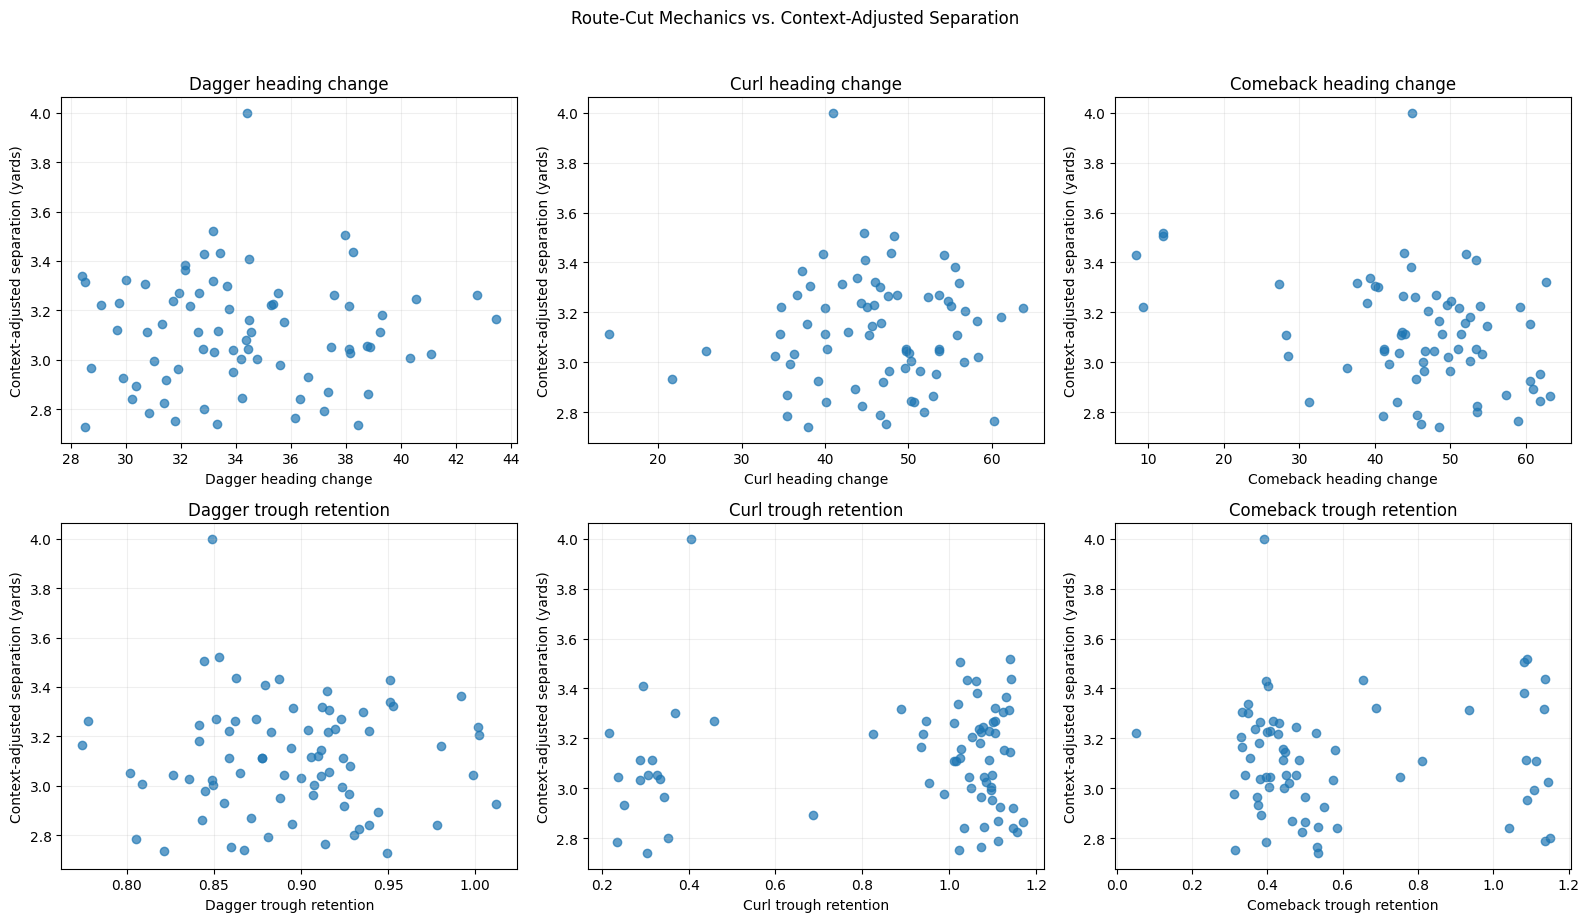


Cell 7 completed.


In [37]:

# ============================================================
# CELL 7 — TEST ASSOCIATIONS BETWEEN CUT MECHANICS AND SEPARATION
# ============================================================
#
# Primary outcome:
#   adjusted_sep_mean
#
# Sensitivity outcome:
#   target_adjusted_sep_mean
#
# Primary mechanical predictors:
#   - Heading change in Dagger, Curl, and Comeback
#   - Trough speed retention in Dagger, Curl, and Comeback
#
# Statistical approach:
#   1. Spearman correlations
#   2. Benjamini-Hochberg correction across six tests
#   3. Exploratory HC3-robust regressions controlling for:
#        - Separation sample size
#        - NGS athleticism score
#
# Caution:
#   Most drill summaries are based on one attempt per player.
#   Results are exploratory associations, not causal effects.
# ============================================================

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Define the six primary mechanical predictors
# ------------------------------------------------------------

mechanics_features = {
    "Dagger heading change":
        "DAGGER_ROUTE_LEFT_mean_heading_change_deg",

    "Curl heading change":
        "CURL_ROUTE_RIGHT_mean_heading_change_deg",

    "Comeback heading change":
        "COMEBACK_ROUTE_RIGHT_mean_heading_change_deg",

    "Dagger trough retention":
        "DAGGER_ROUTE_LEFT_mean_trough_retention",

    "Curl trough retention":
        "CURL_ROUTE_RIGHT_mean_trough_retention",

    "Comeback trough retention":
        "COMEBACK_ROUTE_RIGHT_mean_trough_retention",
}

outcome = "adjusted_sep_mean"
target_outcome = "target_adjusted_sep_mean"

control_columns = [
    "n_separation_plays",
    "ngs_athleticism_score",
]

required_columns = (
    ["nfl_id", outcome, target_outcome]
    + list(mechanics_features.values())
    + control_columns
)

missing_columns = [
    col for col in required_columns
    if col not in primary_analysis_df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns required for Cell 7: {missing_columns}"
    )

# Work from a copy so the main analysis dataset remains unchanged.
model_df = primary_analysis_df.copy()

# Ensure analysis variables are numeric.
numeric_columns = (
    [outcome, target_outcome]
    + list(mechanics_features.values())
    + control_columns
)

for col in numeric_columns:
    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 2. Spearman correlations: mechanics vs adjusted separation
# ------------------------------------------------------------

correlation_results = []

for feature_label, feature_column in mechanics_features.items():

    subset = model_df[
        [outcome, feature_column]
    ].dropna()

    if (
        len(subset) < 10
        or subset[feature_column].nunique() < 2
        or subset[outcome].nunique() < 2
    ):
        rho, p_value = np.nan, np.nan
    else:
        rho, p_value = stats.spearmanr(
            subset[feature_column],
            subset[outcome]
        )

    correlation_results.append({
        "feature": feature_label,
        "feature_column": feature_column,
        "n_players": len(subset),
        "spearman_rho": rho,
        "p_value": p_value,
    })

correlation_results = pd.DataFrame(correlation_results)

# Correct the six primary correlation tests for multiple comparisons.
valid_p = correlation_results["p_value"].notna()

correlation_results["p_fdr"] = np.nan

if valid_p.sum() > 0:
    correlation_results.loc[valid_p, "p_fdr"] = (
        multipletests(
            correlation_results.loc[valid_p, "p_value"],
            method="fdr_bh"
        )[1]
    )

correlation_results = correlation_results.sort_values(
    "p_value",
    na_position="last"
)

print("=" * 75)
print("PRIMARY SPEARMAN CORRELATIONS")
print("=" * 75)

print(
    correlation_results[
        [
            "feature",
            "n_players",
            "spearman_rho",
            "p_value",
            "p_fdr",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 3. Exploratory regressions with HC3 robust standard errors
# ------------------------------------------------------------
#
# Each model tests one mechanical feature at a time.
#
# Standardized coefficient:
#   Change in outcome standard deviations associated with a
#   one-standard-deviation increase in the mechanical feature,
#   conditional on the two controls.
#
# We fit separate models rather than placing all six correlated
# features into one model. This limits overfitting and makes
# the drill-specific comparisons easier to interpret.

regression_results = []

for feature_label, feature_column in mechanics_features.items():

    required = [
        outcome,
        feature_column,
        "n_separation_plays",
        "ngs_athleticism_score",
    ]

    subset = model_df[required].dropna().copy()

    if len(subset) < 15:
        regression_results.append({
            "feature": feature_label,
            "n_players": len(subset),
            "beta_standardized": np.nan,
            "p_value": np.nan,
            "r_squared": np.nan,
        })
        continue

    # Log-transform the play count because its distribution
    # is strongly right-skewed.
    subset["log_play_count"] = np.log1p(
        subset["n_separation_plays"]
    )

    predictors = [
        feature_column,
        "log_play_count",
        "ngs_athleticism_score",
    ]

    # Standardize outcome and all predictors.
    y_std = (
        subset[outcome] - subset[outcome].mean()
    ) / subset[outcome].std(ddof=0)

    X_std = pd.DataFrame(index=subset.index)

    for col in predictors:
        sd = subset[col].std(ddof=0)

        if sd == 0 or pd.isna(sd):
            X_std[col] = 0.0
        else:
            X_std[col] = (
                subset[col] - subset[col].mean()
            ) / sd

    X_std = sm.add_constant(X_std)

    model = sm.OLS(
        y_std,
        X_std
    ).fit(cov_type="HC3")

    regression_results.append({
        "feature": feature_label,
        "n_players": len(subset),
        "beta_standardized": model.params[feature_column],
        "p_value": model.pvalues[feature_column],
        "r_squared": model.rsquared,
    })

regression_results = pd.DataFrame(regression_results)

valid_p = regression_results["p_value"].notna()

regression_results["p_fdr"] = np.nan

if valid_p.sum() > 0:
    regression_results.loc[valid_p, "p_fdr"] = (
        multipletests(
            regression_results.loc[valid_p, "p_value"],
            method="fdr_bh"
        )[1]
    )

regression_results = regression_results.sort_values(
    "p_value",
    na_position="last"
)

print("\n" + "=" * 75)
print("EXPLORATORY REGRESSION RESULTS")
print("=" * 75)

print(
    regression_results.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 4. Sensitivity analysis: targeted-play separation only
# ------------------------------------------------------------
#
# The target-only outcome is based on fewer observations and
# may be noisier. We use it to check whether the direction of
# the associations is broadly similar, not as a replacement
# for the primary outcome.

target_results = []

for feature_label, feature_column in mechanics_features.items():

    subset = model_df[
        [
            target_outcome,
            feature_column,
            "n_targeted_plays",
        ]
    ].dropna()

    # Exclude players with no targeted plays.
    subset = subset[
        subset["n_targeted_plays"] > 0
    ]

    if (
        len(subset) < 10
        or subset[feature_column].nunique() < 2
        or subset[target_outcome].nunique() < 2
    ):
        rho, p_value = np.nan, np.nan
    else:
        rho, p_value = stats.spearmanr(
            subset[feature_column],
            subset[target_outcome]
        )

    target_results.append({
        "feature": feature_label,
        "n_players": len(subset),
        "target_spearman_rho": rho,
        "p_value": p_value,
    })

target_results = pd.DataFrame(target_results)

valid_p = target_results["p_value"].notna()

target_results["p_fdr"] = np.nan

if valid_p.sum() > 0:
    target_results.loc[valid_p, "p_fdr"] = (
        multipletests(
            target_results.loc[valid_p, "p_value"],
            method="fdr_bh"
        )[1]
    )

print("\n" + "=" * 75)
print("TARGET-ONLY SENSITIVITY ANALYSIS")
print("=" * 75)

print(
    target_results.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Compare the primary and target-only associations
# ------------------------------------------------------------

comparison = (
    correlation_results[
        ["feature", "n_players", "spearman_rho"]
    ]
    .rename(columns={
        "n_players": "primary_n",
        "spearman_rho": "primary_rho",
    })
    .merge(
        target_results[
            ["feature", "n_players", "target_spearman_rho"]
        ].rename(columns={
            "n_players": "target_n",
        }),
        on="feature",
        how="left"
    )
)

print("\n" + "=" * 75)
print("PRIMARY VS TARGET-ONLY COMPARISON")
print("=" * 75)

print(comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# 6. Visualize the six primary relationships
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for ax, (feature_label, feature_column) in zip(
    axes.flat,
    mechanics_features.items()
):

    subset = model_df[
        [feature_column, outcome]
    ].dropna()

    ax.scatter(
        subset[feature_column],
        subset[outcome],
        alpha=0.7
    )

    ax.set_title(feature_label)
    ax.set_xlabel(feature_label)
    ax.set_ylabel("Context-adjusted separation (yards)")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Route-Cut Mechanics vs. Context-Adjusted Separation",
    y=1.02
)

plt.tight_layout()
plt.show()

print("\nCell 7 completed.")


COMEBACK HEADING-CHANGE STABILITY ANALYSIS

NESTED MODEL COMPARISON
                        outcome  n_players  heading_beta  heading_p_HC3  base_r_squared  full_r_squared  incremental_r_squared
        All-play raw separation         68       -0.1851         0.0746          0.0133          0.0452                 0.0319
   All-play adjusted separation         68       -0.3266         0.0018          0.0352          0.1345                 0.0994
     Target-only raw separation         67       -0.1393         0.1560          0.0127          0.0311                 0.0184
Target-only adjusted separation         67       -0.3013         0.0038          0.0212          0.1072                 0.0861


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


BOOTSTRAP COEFFICIENT INTERVAL
Successful bootstrap samples: 3,000
Observed standardized coefficient: -0.3266
Bootstrap median coefficient: -0.3229
95% bootstrap interval: [-0.5567, -0.0843]

FIVE MOST INFLUENTIAL PLAYERS
 nfl_id  COMEBACK_ROUTE_RIGHT_mean_heading_change_deg  adjusted_sep_mean  n_separation_plays  cooks_distance  leverage  studentized_residual
  58968                                       42.9529             2.8414             17.0000          0.0912    0.1400               -1.5125
  55990                                       44.9711             3.9987            144.0000          0.0783    0.0186                4.6814
  57361                                       53.4570             3.4096             28.0000          0.0670    0.0947                1.6214
  56121                                       46.0781             2.7511             27.0000          0.0646    0.0683               -1.9154
  58307                                       43.8481             3.4376

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



LEAVE-ONE-PLAYER-OUT STABILITY
Minimum coefficient: -0.3772
Median coefficient: -0.3268
Maximum coefficient: -0.2784
Number of positive coefficients: 0
Number of negative coefficients: 68


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


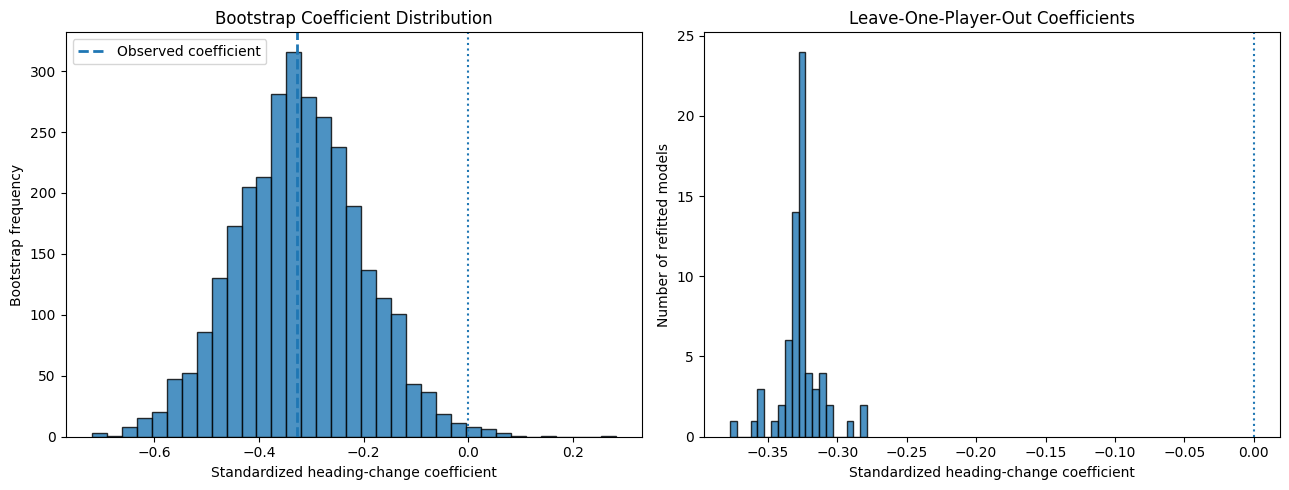


Cell 8 completed.


In [38]:

# ============================================================
# CELL 8 — VALIDATE THE COMEBACK HEADING-CHANGE ASSOCIATION
# ============================================================
#
# Research question:
#   Is Comeback heading change consistently associated with
#   receiver separation, or is the result sensitive to outcome
#   definition, individual players, or model specification?
#
# Outcomes:
#   1. All-play raw separation
#   2. All-play context-adjusted separation
#   3. Target-only raw separation
#   4. Target-only context-adjusted separation
#
# Main predictor:
#   COMEBACK_ROUTE_RIGHT_mean_heading_change_deg
#
# Controls:
#   - NGS athleticism score
#   - Log number of relevant observations
#
# Additional checks:
#   - Incremental R-squared
#   - HC3 robust standard errors
#   - Bootstrap confidence interval
#   - Cook's distance
#   - Leave-one-player-out coefficient stability
#
# This remains an observational analysis.
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

# ------------------------------------------------------------
# 1. Set up the Comeback analysis sample
# ------------------------------------------------------------

heading_feature = (
    "COMEBACK_ROUTE_RIGHT_mean_heading_change_deg"
)

outcome_definitions = {
    "All-play raw separation": (
        "raw_sep_mean",
        "n_separation_plays"
    ),

    "All-play adjusted separation": (
        "adjusted_sep_mean",
        "n_separation_plays"
    ),

    "Target-only raw separation": (
        "target_raw_sep_mean",
        "n_targeted_plays"
    ),

    "Target-only adjusted separation": (
        "target_adjusted_sep_mean",
        "n_targeted_plays"
    ),
}

base_required = [
    "nfl_id",
    heading_feature,
    "ngs_athleticism_score",
]

for outcome_name, (outcome_col, count_col) in outcome_definitions.items():
    missing = [
        col for col in [outcome_col, count_col]
        if col not in primary_analysis_df.columns
    ]

    if missing:
        raise KeyError(
            f"Missing columns for {outcome_name}: {missing}"
        )

print("=" * 75)
print("COMEBACK HEADING-CHANGE STABILITY ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 2. Fit nested models for each outcome
# ------------------------------------------------------------
#
# Base model:
#   Separation ~ NGS athleticism + log observation count
#
# Full model:
#   Separation ~ NGS athleticism + log observation count
#               + Comeback heading change
#
# The incremental R-squared estimates how much additional
# in-sample variance is explained by adding heading change.
#
# It is not an out-of-sample predictive performance measure.

nested_results = []
primary_model = None
primary_model_data = None
primary_model_columns = None

for outcome_name, (outcome_col, count_col) in outcome_definitions.items():

    cols = [
        "nfl_id",
        outcome_col,
        heading_feature,
        count_col,
        "ngs_athleticism_score",
    ]

    subset = primary_analysis_df[cols].copy()

    for col in cols:
        if col != "nfl_id":
            subset[col] = pd.to_numeric(
                subset[col],
                errors="coerce"
            )

    subset = subset.dropna().copy()
    subset = subset[subset[count_col] > 0].copy()

    if len(subset) < 15:
        print(
            f"Skipping {outcome_name}: "
            f"only {len(subset)} complete observations."
        )
        continue

    subset["log_observation_count"] = np.log1p(
        subset[count_col]
    )

    # Standardize the outcome and predictors.
    y = (
        subset[outcome_col] - subset[outcome_col].mean()
    ) / subset[outcome_col].std(ddof=0)

    X_base = pd.DataFrame(index=subset.index)

    for col in ["ngs_athleticism_score", "log_observation_count"]:
        sd = subset[col].std(ddof=0)

        if sd == 0:
            X_base[col] = 0.0
        else:
            X_base[col] = (
                subset[col] - subset[col].mean()
            ) / sd

    X_full = X_base.copy()

    heading_sd = subset[heading_feature].std(ddof=0)

    if heading_sd == 0:
        print(f"Skipping {outcome_name}: no heading variation.")
        continue

    X_full[heading_feature] = (
        subset[heading_feature]
        - subset[heading_feature].mean()
    ) / heading_sd

    base_model = sm.OLS(
        y,
        sm.add_constant(X_base)
    ).fit()

    full_model = sm.OLS(
        y,
        sm.add_constant(X_full)
    ).fit(cov_type="HC3")

    nested_results.append({
        "outcome": outcome_name,
        "n_players": len(subset),
        "heading_beta": full_model.params[heading_feature],
        "heading_p_HC3": full_model.pvalues[heading_feature],
        "base_r_squared": base_model.rsquared,
        "full_r_squared": full_model.rsquared,
        "incremental_r_squared": (
            full_model.rsquared - base_model.rsquared
        ),
    })

    if outcome_name == "All-play adjusted separation":
        primary_model = full_model
        primary_model_data = subset.copy()
        primary_model_columns = X_full.copy()

nested_results = pd.DataFrame(nested_results)

print("\n" + "=" * 75)
print("NESTED MODEL COMPARISON")
print("=" * 75)

print(
    nested_results
    .round(4)
    .to_string(index=False)
)

if primary_model is None:
    raise RuntimeError(
        "Primary adjusted-separation model could not be fitted."
    )

# ------------------------------------------------------------
# 3. Bootstrap confidence interval for the primary coefficient
# ------------------------------------------------------------
#
# Resample players, not individual plays.
# Each bootstrap sample contains the same number of player
# records as the original complete-case sample.
#
# The bootstrap estimates uncertainty in the player-level
# association. It does not correct for measurement error in
# the underlying single-attempt drill features.

rng = np.random.default_rng(RANDOM_SEED)

bootstrap_data = primary_model_data.reset_index(drop=True)

bootstrap_betas = []

N_BOOTSTRAP = 3000

for iteration in range(N_BOOTSTRAP):

    sampled_positions = rng.integers(
        low=0,
        high=len(bootstrap_data),
        size=len(bootstrap_data)
    )

    sample = bootstrap_data.iloc[
        sampled_positions
    ].copy()

    y_raw = sample["adjusted_sep_mean"]
    heading_raw = sample[heading_feature]
    count_raw = np.log1p(sample["n_separation_plays"])
    ngs_raw = sample["ngs_athleticism_score"]

    if (
        y_raw.std(ddof=0) == 0
        or heading_raw.std(ddof=0) == 0
    ):
        continue

    y_boot = (
        y_raw - y_raw.mean()
    ) / y_raw.std(ddof=0)

    X_boot = pd.DataFrame({
        heading_feature: (
            heading_raw - heading_raw.mean()
        ) / heading_raw.std(ddof=0),

        "log_observation_count": (
            count_raw - count_raw.mean()
        ) / count_raw.std(ddof=0),

        "ngs_athleticism_score": (
            ngs_raw - ngs_raw.mean()
        ) / ngs_raw.std(ddof=0),
    })

    try:
        boot_fit = sm.OLS(
            y_boot,
            sm.add_constant(X_boot)
        ).fit()

        bootstrap_betas.append(
            boot_fit.params[heading_feature]
        )

    except Exception:
        continue

bootstrap_betas = np.asarray(bootstrap_betas)

bootstrap_ci = np.percentile(
    bootstrap_betas,
    [2.5, 50, 97.5]
)

print("\n" + "=" * 75)
print("BOOTSTRAP COEFFICIENT INTERVAL")
print("=" * 75)

print(f"Successful bootstrap samples: {len(bootstrap_betas):,}")
print(
    "Observed standardized coefficient:",
    round(primary_model.params[heading_feature], 4)
)
print(
    "Bootstrap median coefficient:",
    round(bootstrap_ci[1], 4)
)
print(
    "95% bootstrap interval:",
    f"[{bootstrap_ci[0]:.4f}, {bootstrap_ci[2]:.4f}]"
)

# ------------------------------------------------------------
# 4. Identify influential observations
# ------------------------------------------------------------
#
# Cook's distance is a diagnostic for observations that have
# unusual influence on the fitted regression.
#
# It is a screening measure, not a rule for automatically
# deleting players.

influence_model = sm.OLS(
    primary_model.model.endog,
    primary_model.model.exog
).fit()

influence = influence_model.get_influence()

influence_table = primary_model_data[
    [
        "nfl_id",
        heading_feature,
        "adjusted_sep_mean",
        "n_separation_plays",
    ]
].copy().reset_index(drop=True)

influence_table["cooks_distance"] = (
    influence.cooks_distance[0]
)

influence_table["leverage"] = (
    influence.hat_matrix_diag
)

influence_table["studentized_residual"] = (
    influence.resid_studentized_external
)

influence_table = influence_table.sort_values(
    "cooks_distance",
    ascending=False
)

print("\n" + "=" * 75)
print("FIVE MOST INFLUENTIAL PLAYERS")
print("=" * 75)

print(
    influence_table.head(5)
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 5. Leave-one-player-out coefficient stability
# ------------------------------------------------------------
#
# Refit the primary model after removing each player once.
# This checks whether the estimated heading relationship
# depends heavily on any one individual.

loo_betas = []

for player_id in primary_model_data["nfl_id"].unique():

    loo_data = primary_model_data[
        primary_model_data["nfl_id"] != player_id
    ].copy()

    if len(loo_data) < 15:
        continue

    y_raw = loo_data["adjusted_sep_mean"]
    heading_raw = loo_data[heading_feature]
    count_raw = np.log1p(loo_data["n_separation_plays"])
    ngs_raw = loo_data["ngs_athleticism_score"]

    if (
        y_raw.std(ddof=0) == 0
        or heading_raw.std(ddof=0) == 0
        or count_raw.std(ddof=0) == 0
        or ngs_raw.std(ddof=0) == 0
    ):
        continue

    y_loo = (
        y_raw - y_raw.mean()
    ) / y_raw.std(ddof=0)

    X_loo = pd.DataFrame({
        heading_feature: (
            heading_raw - heading_raw.mean()
        ) / heading_raw.std(ddof=0),

        "log_observation_count": (
            count_raw - count_raw.mean()
        ) / count_raw.std(ddof=0),

        "ngs_athleticism_score": (
            ngs_raw - ngs_raw.mean()
        ) / ngs_raw.std(ddof=0),
    })

    loo_fit = sm.OLS(
        y_loo,
        sm.add_constant(X_loo)
    ).fit()

    loo_betas.append({
        "excluded_nfl_id": player_id,
        "heading_beta": loo_fit.params[heading_feature],
    })

loo_results = pd.DataFrame(loo_betas)

print("\n" + "=" * 75)
print("LEAVE-ONE-PLAYER-OUT STABILITY")
print("=" * 75)

print(
    "Minimum coefficient:",
    round(loo_results["heading_beta"].min(), 4)
)
print(
    "Median coefficient:",
    round(loo_results["heading_beta"].median(), 4)
)
print(
    "Maximum coefficient:",
    round(loo_results["heading_beta"].max(), 4)
)
print(
    "Number of positive coefficients:",
    int((loo_results["heading_beta"] > 0).sum())
)
print(
    "Number of negative coefficients:",
    int((loo_results["heading_beta"] < 0).sum())
)

# ------------------------------------------------------------
# 6. Plot bootstrap and leave-one-out distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    bootstrap_betas,
    bins=35,
    edgecolor="black",
    alpha=0.8
)

axes[0].axvline(
    primary_model.params[heading_feature],
    linestyle="--",
    linewidth=2,
    label="Observed coefficient"
)

axes[0].axvline(
    0,
    linestyle=":",
    linewidth=1.5
)

axes[0].set_title("Bootstrap Coefficient Distribution")
axes[0].set_xlabel("Standardized heading-change coefficient")
axes[0].set_ylabel("Bootstrap frequency")
axes[0].legend()

axes[1].hist(
    loo_results["heading_beta"],
    bins=20,
    edgecolor="black",
    alpha=0.8
)

axes[1].axvline(
    0,
    linestyle=":",
    linewidth=1.5
)

axes[1].set_title("Leave-One-Player-Out Coefficients")
axes[1].set_xlabel("Standardized heading-change coefficient")
axes[1].set_ylabel("Number of refitted models")

plt.tight_layout()
plt.show()

print("\nCell 8 completed.")


SELECTED COMEBACK ATTEMPTS
 nfl_id                         event_id  window_heading_change_deg  trough_retention  exit_retention  true_braking_decel  true_exit_reaccel
  58968 20250301100800_1740876026215_000                    39.4150            0.9980          1.0090              0.0650             0.1740
  58307 20250301100700_1740866727822_000                    43.8480            1.1380          1.5990              1.3520             5.1280
  55990    6414e5fde3d8e72dcdc8d49b-2023                    44.9710            0.3920          0.5850             -6.5500             1.9830
  56121    6414e5fde3d8e72dcdc8d4a7-2023                    46.0780            0.3140          0.5570             -9.0830             1.8830
  58968 20250301100800_1740876137686_000                    46.4910            1.0850          1.4980              0.2850             3.2090
  57223 20240302100700_1709415889162_000                    47.1020            0.3290          0.5820             -8.3170      

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


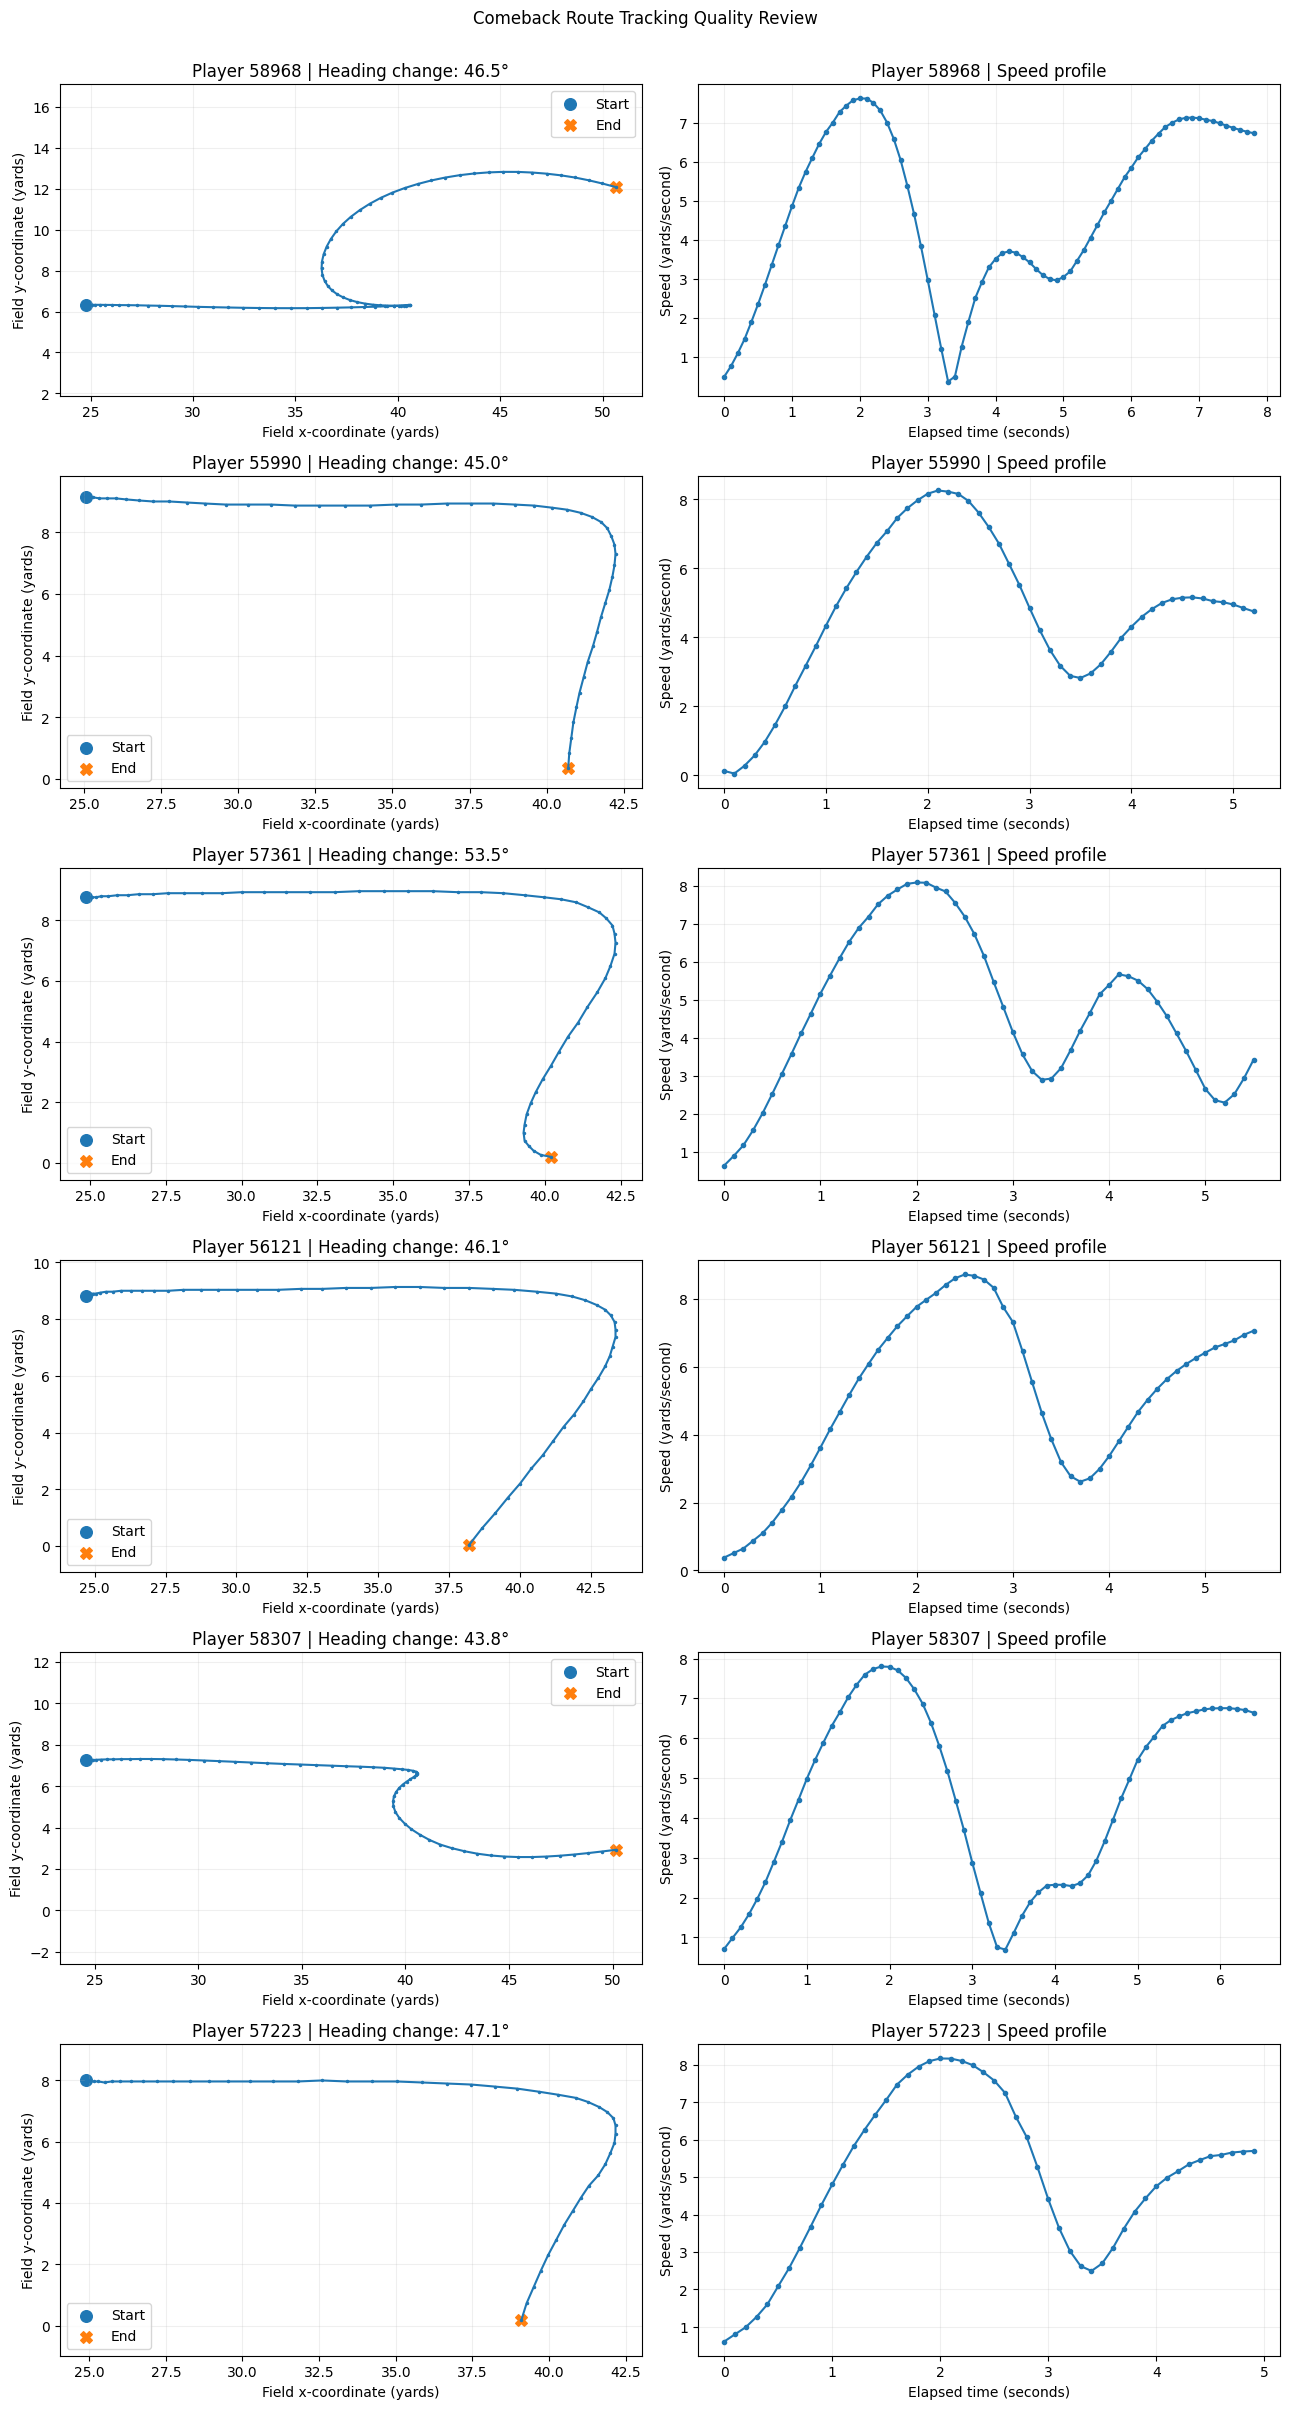


COMEBACK HEADING-CHANGE DISTRIBUTION
count   108.0000
mean     43.8700
std      13.8300
min       3.6100
5%       11.9200
25%      39.8700
50%      47.2400
75%      52.6800
95%      60.8700
max      63.4900
Name: window_heading_change_deg, dtype: float64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


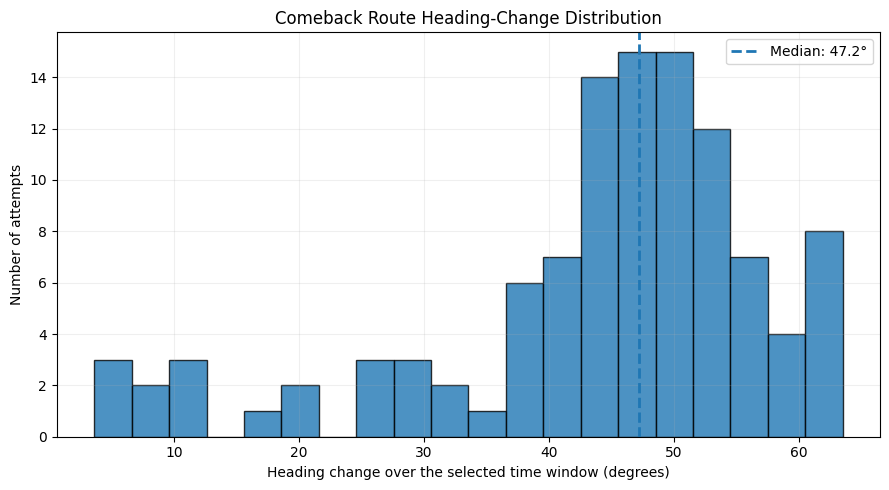


Cell 9 completed.


In [39]:

# ============================================================
# CELL 9 — VISUAL QUALITY CHECK OF COMEBACK ROUTE ATTEMPTS
# ============================================================
#
# Objective:
#   Inspect the original tracking data behind the Comeback
#   heading-change association.
#
# We inspect:
#   - The five most influential players from Cell 8
#   - One player near the median Comeback heading change
#
# Each player has:
#   1. An x-y field trajectory
#   2. A speed-over-time profile
#
# These plots help us check whether the selected heading
# change represents the intended route break.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Identify players for visual inspection
# ------------------------------------------------------------

influential_ids = (
    influence_table
    .head(5)["nfl_id"]
    .tolist()
)

comeback_attempts = wr_cut_attempts[
    wr_cut_attempts["drill_name"] == "COMEBACK_ROUTE_RIGHT"
].copy()

# Select the player closest to the median heading change.
median_heading = comeback_attempts[
    "window_heading_change_deg"
].median()

median_player_row = (
    comeback_attempts
    .assign(
        distance_from_median=lambda x: (
            x["window_heading_change_deg"] - median_heading
        ).abs()
    )
    .sort_values("distance_from_median")
    .iloc[0]
)

median_player_id = median_player_row["nfl_id"]

inspection_ids = list(dict.fromkeys(
    influential_ids + [median_player_id]
))

print("=" * 75)
print("SELECTED COMEBACK ATTEMPTS")
print("=" * 75)

inspection_attempts = comeback_attempts[
    comeback_attempts["nfl_id"].isin(inspection_ids)
].copy()

display_columns = [
    "nfl_id",
    "event_id",
    "window_heading_change_deg",
    "trough_retention",
    "exit_retention",
    "true_braking_decel",
    "true_exit_reaccel",
]

print(
    inspection_attempts[display_columns]
    .sort_values("window_heading_change_deg")
    .round(3)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 2. Check tracking columns
# ------------------------------------------------------------

tracking_required = [
    "nfl_id",
    "event_id",
    "x",
    "y",
    "s",
    "time",
]

missing_tracking_columns = [
    col for col in tracking_required
    if col not in wr_trk.columns
]

if missing_tracking_columns:
    raise KeyError(
        "Required tracking columns missing: "
        f"{missing_tracking_columns}"
    )

tracking = wr_trk.copy()

tracking["nfl_id"] = pd.to_numeric(
    tracking["nfl_id"],
    errors="coerce"
)

tracking["x"] = pd.to_numeric(
    tracking["x"],
    errors="coerce"
)

tracking["y"] = pd.to_numeric(
    tracking["y"],
    errors="coerce"
)

tracking["s"] = pd.to_numeric(
    tracking["s"],
    errors="coerce"
)

tracking["time"] = pd.to_datetime(
    tracking["time"],
    errors="coerce"
)

# Retain player tracking observations only, if entity_type exists.
if "entity_type" in tracking.columns:
    tracking = tracking[
        tracking["entity_type"] == "PLAYER"
    ].copy()

# ------------------------------------------------------------
# 3. Plot each selected attempt
# ------------------------------------------------------------

n_players = len(inspection_ids)

fig, axes = plt.subplots(
    n_players,
    2,
    figsize=(13, 4 * n_players),
    squeeze=False
)

for row_index, player_id in enumerate(inspection_ids):

    attempt_rows = inspection_attempts[
        inspection_attempts["nfl_id"] == player_id
    ]

    if attempt_rows.empty:
        continue

    # Most players have one attempt. If more than one exists,
    # inspect the attempt with the largest heading change.
    attempt = (
        attempt_rows
        .sort_values(
            "window_heading_change_deg",
            ascending=False
        )
        .iloc[0]
    )

    event_id = attempt["event_id"]

    player_tracking = tracking[
        (tracking["nfl_id"] == player_id)
        & (tracking["event_id"].astype(str) == str(event_id))
    ].copy()

    player_tracking = (
        player_tracking
        .dropna(subset=["x", "y", "s", "time"])
        .sort_values("time")
    )

    ax_path = axes[row_index, 0]
    ax_speed = axes[row_index, 1]

    if len(player_tracking) < 5:
        ax_path.set_title(
            f"Player {player_id}: insufficient tracking data"
        )
        ax_speed.set_axis_off()
        continue

    elapsed_seconds = (
        player_tracking["time"]
        - player_tracking["time"].iloc[0]
    ).dt.total_seconds()

    heading_value = attempt["window_heading_change_deg"]

    # Field trajectory.
    ax_path.plot(
        player_tracking["x"],
        player_tracking["y"],
        marker=".",
        markersize=3,
        linewidth=1.5
    )

    ax_path.scatter(
        player_tracking["x"].iloc[0],
        player_tracking["y"].iloc[0],
        marker="o",
        s=70,
        label="Start"
    )

    ax_path.scatter(
        player_tracking["x"].iloc[-1],
        player_tracking["y"].iloc[-1],
        marker="X",
        s=70,
        label="End"
    )

    ax_path.set_title(
        f"Player {player_id} | Heading change: {heading_value:.1f}°"
    )
    ax_path.set_xlabel("Field x-coordinate (yards)")
    ax_path.set_ylabel("Field y-coordinate (yards)")
    ax_path.legend()
    ax_path.grid(alpha=0.2)
    ax_path.axis("equal")

    # Speed profile.
    ax_speed.plot(
        elapsed_seconds,
        player_tracking["s"],
        marker=".",
        linewidth=1.5
    )

    ax_speed.set_title(
        f"Player {player_id} | Speed profile"
    )
    ax_speed.set_xlabel("Elapsed time (seconds)")
    ax_speed.set_ylabel("Speed (yards/second)")
    ax_speed.grid(alpha=0.2)

plt.suptitle(
    "Comeback Route Tracking Quality Review",
    y=1.002
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Inspect the full Comeback heading-change distribution
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COMEBACK HEADING-CHANGE DISTRIBUTION")
print("=" * 75)

print(
    comeback_attempts[
        "window_heading_change_deg"
    ].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).round(2)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    comeback_attempts["window_heading_change_deg"].dropna(),
    bins=20,
    edgecolor="black",
    alpha=0.8
)

ax.axvline(
    median_heading,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_heading:.1f}°"
)

ax.set_title("Comeback Route Heading-Change Distribution")
ax.set_xlabel("Heading change over the selected time window (degrees)")
ax.set_ylabel("Number of attempts")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("\nCell 9 completed.")


CELL 10 — ROUTE SHAPE AND CUTTING DYNAMICS
Attempts with Cell 4 cut centers: 326
Attempts with coordinate dynamics: 325
Players represented: 106

Exclusion counts:
too_few_frames: 0
invalid_time_sequence: 0
invalid_velocity: 0
invalid_initial_direction: 1
cut_center_outside_tracking: 0
insufficient_local_window: 0

Retained attempts by drill:
drill_name
DAGGER_ROUTE_LEFT       114
COMEBACK_ROUTE_RIGHT    107
CURL_ROUTE_RIGHT        104

NEW MOVEMENT FEATURES BY DRILL
                      attempts  mean_peak_angular_velocity  median_peak_angular_velocity  mean_cumulative_heading  mean_turn_duration  mean_speed_loss_fraction  reversal_attempts
drill_name                                                                                                                                                                        
COMEBACK_ROUTE_RIGHT       107                    124.4790                      132.7680                  80.5020              0.8590                    0.2350           

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


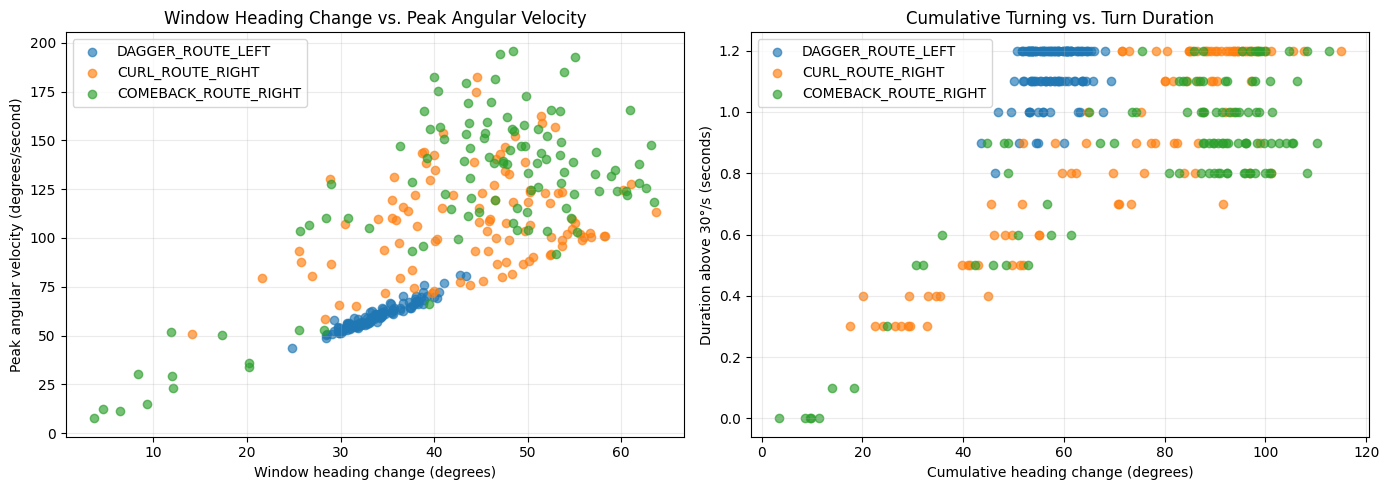


PLAYER-LEVEL DYNAMICS FEATURE TABLE
Rows: 106
Unique players: 106
Columns: 25

New feature availability:
DAGGER_ROUTE_LEFT_n_dynamics_attempts                       106
DAGGER_ROUTE_LEFT_mean_peak_angular_velocity_deg_s          106
DAGGER_ROUTE_LEFT_mean_reverse_motion_fraction_local        106
DAGGER_ROUTE_LEFT_mean_min_initial_direction_velocity       106
DAGGER_ROUTE_LEFT_mean_local_speed_loss_fraction            106
DAGGER_ROUTE_LEFT_mean_turn_duration_above_30_deg_s         106
DAGGER_ROUTE_LEFT_mean_net_heading_change_deg               106
DAGGER_ROUTE_LEFT_mean_cumulative_heading_change_deg        106
CURL_ROUTE_RIGHT_mean_reverse_motion_fraction_local         102
CURL_ROUTE_RIGHT_mean_min_initial_direction_velocity        102
CURL_ROUTE_RIGHT_mean_local_speed_loss_fraction             102
CURL_ROUTE_RIGHT_mean_cumulative_heading_change_deg         102
CURL_ROUTE_RIGHT_n_dynamics_attempts                        102
CURL_ROUTE_RIGHT_mean_peak_angular_velocity_deg_s           10

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [40]:
# ============================================================
# CELL 10 — ROUTE SHAPE AND CUTTING DYNAMICS
# ============================================================
#
# Objective:
#   Extend the existing window-heading-change feature with
#   coordinate-derived measures of turning and speed dynamics.
#
# Important:
#   - We retain the cut center detected in Cell 4.
#   - We do NOT overwrite wr_cut_attempts or wr_kinematics.
#   - Direction is calculated from x/y coordinates.
#   - Actual timestamps are used for all derivatives.
#   - A short centered smoothing window reduces tracking noise.
#
# These are observed attempt-level movement features.
# They should not yet be interpreted as stable player traits.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Define feature-extraction settings
# ------------------------------------------------------------

# Analyze movement within 0.6 seconds before and after
# the cut center selected in Cell 4.
LOCAL_WINDOW_SECONDS = 0.6

# Use the first 0.5 seconds to estimate the player's
# initial direction of movement.
INITIAL_DIRECTION_SECONDS = 0.5

# Use a centered 3-observation rolling mean to reduce
# small tracking fluctuations before calculating velocity.
POSITION_SMOOTHING_FRAMES = 3

# Descriptive angular-velocity threshold for turn duration.
# This is fixed before examining separation associations.
TURN_RATE_THRESHOLD_DEG_S = 30.0

# Minimum number of valid observations needed for derivatives.
MIN_DYNAMICS_FRAMES = 10


# ------------------------------------------------------------
# 2. Validate required columns
# ------------------------------------------------------------

required_tracking_columns = [
    "nfl_id",
    "drill_name",
    "event_id",
    "time",
    "x",
    "y",
]

missing_tracking_columns = [
    col for col in required_tracking_columns
    if col not in wr_player_trk.columns
]

if missing_tracking_columns:
    raise KeyError(
        "Required columns missing from wr_player_trk: "
        f"{missing_tracking_columns}"
    )

required_cut_columns = [
    "nfl_id",
    "drill_name",
    "event_id",
    "cut_time_s",
    "window_heading_change_deg",
]

missing_cut_columns = [
    col for col in required_cut_columns
    if col not in wr_cut_attempts.columns
]

if missing_cut_columns:
    raise KeyError(
        "Required columns missing from wr_cut_attempts: "
        f"{missing_cut_columns}"
    )


# ------------------------------------------------------------
# 3. Prepare the tracking data
# ------------------------------------------------------------

dynamics_tracking = wr_player_trk[
    wr_player_trk["drill_name"].isin(SHARP_BREAK_DRILLS)
].copy()

dynamics_tracking["nfl_id"] = pd.to_numeric(
    dynamics_tracking["nfl_id"],
    errors="coerce"
)

dynamics_tracking["x"] = pd.to_numeric(
    dynamics_tracking["x"],
    errors="coerce"
)

dynamics_tracking["y"] = pd.to_numeric(
    dynamics_tracking["y"],
    errors="coerce"
)

dynamics_tracking["time"] = pd.to_datetime(
    dynamics_tracking["time"],
    errors="coerce"
)

dynamics_tracking = dynamics_tracking.dropna(
    subset=[
        "nfl_id",
        "drill_name",
        "event_id",
        "time",
        "x",
        "y",
    ]
).copy()

dynamics_tracking = dynamics_tracking.sort_values(
    ["nfl_id", "drill_name", "event_id", "time"]
)


# ------------------------------------------------------------
# 4. Extract coordinate-based movement features
# ------------------------------------------------------------

dynamics_rows = []

dynamics_exclusions = {
    "too_few_frames": 0,
    "invalid_time_sequence": 0,
    "invalid_velocity": 0,
    "invalid_initial_direction": 0,
    "cut_center_outside_tracking": 0,
    "insufficient_local_window": 0,
}

# The Cell 4 cut centers are the reference points.
# We use them rather than selecting a new center based on
# the features being evaluated in this cell.

for (nfl_id, drill_name, event_id), group in dynamics_tracking.groupby(
    ["nfl_id", "drill_name", "event_id"]
):

    g = (
        group
        .sort_values("time")
        .drop_duplicates(subset="time")
        .reset_index(drop=True)
        .copy()
    )

    if len(g) < MIN_DYNAMICS_FRAMES:
        dynamics_exclusions["too_few_frames"] += 1
        continue

    # --------------------------------------------------------
    # 4a. Find the existing Cell 4 cut center
    # --------------------------------------------------------

    matching_cut = wr_cut_attempts[
        (wr_cut_attempts["nfl_id"] == nfl_id)
        & (wr_cut_attempts["drill_name"] == drill_name)
        & (wr_cut_attempts["event_id"].astype(str) == str(event_id))
    ]

    if matching_cut.empty:
        # This tracking attempt did not pass the Cell 4
        # cut-detection criteria.
        continue

    cut_time_s = float(
        matching_cut.iloc[0]["cut_time_s"]
    )

    # Elapsed time from the first tracking observation.
    t = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds().to_numpy(dtype=float)

    x = g["x"].to_numpy(dtype=float)
    y = g["y"].to_numpy(dtype=float)

    if (
        not np.isfinite(t).all()
        or not np.isfinite(x).all()
        or not np.isfinite(y).all()
        or np.any(np.diff(t) <= 0)
    ):
        dynamics_exclusions["invalid_time_sequence"] += 1
        continue

    # --------------------------------------------------------
    # 4b. Smooth position slightly before differentiation
    # --------------------------------------------------------
    #
    # A derivative amplifies small coordinate fluctuations.
    # The centered rolling mean reduces this noise while
    # preserving the approximate location of the turn.
    #
    # Because the window is centered, it does not intentionally
    # shift the detected cut center forward or backward.

    x_smooth = (
        pd.Series(x)
        .rolling(
            window=POSITION_SMOOTHING_FRAMES,
            center=True,
            min_periods=1
        )
        .mean()
        .to_numpy()
    )

    y_smooth = (
        pd.Series(y)
        .rolling(
            window=POSITION_SMOOTHING_FRAMES,
            center=True,
            min_periods=1
        )
        .mean()
        .to_numpy()
    )

    # --------------------------------------------------------
    # 4c. Calculate coordinate-derived velocity
    # --------------------------------------------------------

    vx = np.gradient(x_smooth, t)
    vy = np.gradient(y_smooth, t)

    coordinate_speed = np.sqrt(
        vx**2 + vy**2
    )

    if (
        not np.isfinite(vx).all()
        or not np.isfinite(vy).all()
        or not np.isfinite(coordinate_speed).all()
    ):
        dynamics_exclusions["invalid_velocity"] += 1
        continue

    # --------------------------------------------------------
    # 4d. Calculate direction of movement from coordinates
    # --------------------------------------------------------
    #
    # atan2 gives the direction of the velocity vector.
    # Unwrapping prevents discontinuities at 0/360 degrees.
    #
    # Example:
    #   359 degrees -> 1 degree
    # should represent a 2-degree change, not 358 degrees.

    course_deg = np.degrees(
        np.arctan2(vy, vx)
    )

    course_unwrapped_deg = np.degrees(
        np.unwrap(np.radians(course_deg))
    )

    # Frame-to-frame heading change.
    heading_change_deg = np.diff(
        course_unwrapped_deg
    )

    # Actual elapsed time between adjacent observations.
    dt = np.diff(t)

    # Angular velocity in degrees per second.
    angular_velocity_deg_s = (
        heading_change_deg / dt
    )

    # Midpoint timestamps associate each angular velocity
    # value with the interval over which it was calculated.
    interval_midpoint_s = (
        t[:-1] + t[1:]
    ) / 2.0

    # --------------------------------------------------------
    # 4e. Define the local turn window
    # --------------------------------------------------------

    local_start = (
        cut_time_s - LOCAL_WINDOW_SECONDS
    )

    local_end = (
        cut_time_s + LOCAL_WINDOW_SECONDS
    )

    local_frame_mask = (
        (t >= local_start)
        & (t <= local_end)
    )

    local_interval_mask = (
        (interval_midpoint_s >= local_start)
        & (interval_midpoint_s <= local_end)
    )

    if (
        local_frame_mask.sum() < 5
        or local_interval_mask.sum() < 4
    ):
        dynamics_exclusions[
            "insufficient_local_window"
        ] += 1
        continue

    local_course = course_unwrapped_deg[
        local_frame_mask
    ]

    local_heading_changes = heading_change_deg[
        local_interval_mask
    ]

    local_angular_velocity = angular_velocity_deg_s[
        local_interval_mask
    ]

    local_dt = dt[
        local_interval_mask
    ]

    # --------------------------------------------------------
    # 4f. Turning magnitude and turning rate
    #     REFINED VERSION
    # --------------------------------------------------------
    #
    # Coordinate-derived direction becomes unreliable when
    # speed is very low.
    #
    # We therefore calculate angular-velocity features only
    # when the average speed across the tracking interval
    # is at least 2.5 yd/s.
    #
    # The 95th percentile of angular velocity is used instead
    # of the absolute maximum to reduce sensitivity to isolated
    # tracking spikes.
    # --------------------------------------------------------

    # Average speed across each interval between observations.
    interval_speed = (
        coordinate_speed[:-1]
        + coordinate_speed[1:]
    ) / 2.0

    # Keep only intervals inside the local cut window.
    local_interval_speed = interval_speed[
        local_interval_mask
    ]

    # Exclude intervals where direction is unstable
    # because the player is moving very slowly.
    MIN_SPEED_FOR_ANGULAR_FEATURES = 2.5

    valid_angular_mask = (
        local_interval_speed
        >= MIN_SPEED_FOR_ANGULAR_FEATURES
    )

    valid_local_angular_velocity = (
        local_angular_velocity[
            valid_angular_mask
        ]
    )

    valid_local_heading_changes = (
        local_heading_changes[
            valid_angular_mask
        ]
    )

    valid_local_dt = (
        local_dt[
            valid_angular_mask
        ]
    )

    # Require enough valid intervals to characterize the turn.
    if len(valid_local_angular_velocity) < 3:
        dynamics_exclusions[
            "insufficient_local_window"
        ] += 1
        continue

    # Robust peak angular velocity:
    # use the 95th percentile of absolute angular velocity.
    peak_angular_velocity = float(
        np.percentile(
            np.abs(valid_local_angular_velocity),
            95
        )
    )

    # Cumulative heading change after low-speed intervals
    # have been excluded.
    cumulative_heading_change = float(
        np.sum(
            np.abs(valid_local_heading_changes)
        )
    )

    # Net heading change:
    # use the first and last valid course measurements
    # within the local window.
    valid_course_indices = np.where(
        local_frame_mask
    )[0]

    valid_course_speeds = coordinate_speed[
        valid_course_indices
    ]

    valid_course_mask = (
        valid_course_speeds
        >= MIN_SPEED_FOR_ANGULAR_FEATURES
    )

    valid_course_indices = (
        valid_course_indices[
            valid_course_mask
        ]
    )

    if len(valid_course_indices) < 2:
        dynamics_exclusions[
            "insufficient_local_window"
        ] += 1
        continue

    first_valid_course = (
        course_unwrapped_deg[
            valid_course_indices[0]
        ]
    )

    last_valid_course = (
        course_unwrapped_deg[
            valid_course_indices[-1]
        ]
    )

    net_heading_change = float(
        angular_diff_deg(
            last_valid_course % 360.0,
            first_valid_course % 360.0
        )
    )

    # Turn duration above the fixed angular-velocity threshold.
    # Only intervals with sufficiently reliable speed are used.
    high_turn_rate_mask = (
        np.abs(valid_local_angular_velocity)
        >= TURN_RATE_THRESHOLD_DEG_S
    )

    turn_duration_above_threshold = float(
        np.sum(
            valid_local_dt[
                high_turn_rate_mask
            ]
        )
    )

    # --------------------------------------------------------
    # 4g. Calculate local speed reduction
    # --------------------------------------------------------

    # Entry speed is the median coordinate-derived speed
    # during the 0.5 seconds immediately before the cut center.

    pre_cut_mask = (
        (t >= cut_time_s - 0.5)
        & (t < cut_time_s)
    )

    # Trough speed is the minimum coordinate-derived speed
    # during the 0.6 seconds after the cut center.

    post_cut_mask = (
        (t >= cut_time_s)
        & (t <= cut_time_s + LOCAL_WINDOW_SECONDS)
    )

    if (
        pre_cut_mask.sum() < 3
        or post_cut_mask.sum() < 3
    ):
        dynamics_exclusions[
            "insufficient_local_window"
        ] += 1
        continue

    entry_coordinate_speed = float(
        np.median(
            coordinate_speed[pre_cut_mask]
        )
    )

    trough_coordinate_speed = float(
        np.min(
            coordinate_speed[post_cut_mask]
        )
    )

    if entry_coordinate_speed <= 0.5:
        dynamics_exclusions[
            "insufficient_local_window"
        ] += 1
        continue

    local_speed_loss_fraction = (
        entry_coordinate_speed
        - trough_coordinate_speed
    ) / entry_coordinate_speed

    # --------------------------------------------------------
    # 4h. Estimate reversal relative to initial movement
    # --------------------------------------------------------
    #
    # We do not assume that x is always the downfield axis.
    #
    # Instead, estimate the player's initial direction using
    # the median velocity during the first 0.5 seconds.
    #
    # Then project later velocity onto that initial direction.
    #
    # Negative projection means movement opposite to the
    # player's initial direction.
    #
    # This is a relative-motion measure, not proof that the
    # player returned toward the quarterback.

    initial_direction_mask = (
        t <= t[0] + INITIAL_DIRECTION_SECONDS
    )

    initial_vx = float(
        np.median(
            vx[initial_direction_mask]
        )
    )

    initial_vy = float(
        np.median(
            vy[initial_direction_mask]
        )
    )

    initial_direction_magnitude = np.sqrt(
        initial_vx**2 + initial_vy**2
    )

    if initial_direction_magnitude <= 0.5:
        dynamics_exclusions[
            "invalid_initial_direction"
        ] += 1
        continue

    initial_unit_x = (
        initial_vx / initial_direction_magnitude
    )

    initial_unit_y = (
        initial_vy / initial_direction_magnitude
    )

    # Velocity projected onto the initial direction.
    initial_direction_velocity = (
        vx * initial_unit_x
        + vy * initial_unit_y
    )

    local_projected_velocity = (
        initial_direction_velocity[
            local_frame_mask
        ]
    )

    minimum_initial_direction_velocity = float(
        np.min(
            local_projected_velocity
        )
    )

    reverse_motion_fraction = float(
        np.mean(
            local_projected_velocity < 0
        )
    )

    # --------------------------------------------------------
    # 4i. Store attempt-level features
    # --------------------------------------------------------

    dynamics_rows.append(
        {
            "nfl_id": nfl_id,
            "drill_name": drill_name,
            "event_id": event_id,

            "cut_time_s": cut_time_s,

            "peak_angular_velocity_deg_s":
                peak_angular_velocity,

            "cumulative_heading_change_deg":
                cumulative_heading_change,

            "net_heading_change_deg":
                net_heading_change,

            "turn_duration_above_30_deg_s":
                turn_duration_above_threshold,

            "entry_coordinate_speed":
                entry_coordinate_speed,

            "trough_coordinate_speed":
                trough_coordinate_speed,

            "local_speed_loss_fraction":
                local_speed_loss_fraction,

            "min_initial_direction_velocity":
                minimum_initial_direction_velocity,

            "reverse_motion_fraction_local":
                reverse_motion_fraction,

            "has_local_direction_reversal":
                minimum_initial_direction_velocity < -0.5,
        }
    )


# ------------------------------------------------------------
# 5. Build the attempt-level feature table
# ------------------------------------------------------------

wr_cut_dynamics_attempts = pd.DataFrame(
    dynamics_rows
)

if wr_cut_dynamics_attempts.empty:
    raise ValueError(
        "No attempts passed the Cell 10 dynamics extraction."
    )

# Add the original Cell 4 measurements for direct comparison.
baseline_columns = [
    "nfl_id",
    "drill_name",
    "event_id",
    "window_heading_change_deg",
    "trough_retention",
    "exit_retention",
    "true_braking_decel",
    "true_exit_reaccel",
]

wr_cut_dynamics_attempts = (
    wr_cut_dynamics_attempts
    .merge(
        wr_cut_attempts[baseline_columns],
        on=[
            "nfl_id",
            "drill_name",
            "event_id",
        ],
        how="left",
        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# 6. Aggregate observed attempts by player and drill
# ------------------------------------------------------------
#
# Most players have only one attempt in a drill.
# We retain the number of attempts and the standard deviation
# so future analyses can distinguish repeated measurements
# from single observed attempts.

dynamics_metrics = [
    "peak_angular_velocity_deg_s",
    "cumulative_heading_change_deg",
    "net_heading_change_deg",
    "turn_duration_above_30_deg_s",
    "local_speed_loss_fraction",
    "min_initial_direction_velocity",
    "reverse_motion_fraction_local",
]

wr_cut_dynamics_player = (
    wr_cut_dynamics_attempts
    .groupby(
        ["nfl_id", "drill_name"]
    )
    .agg(
        n_dynamics_attempts=(
            "event_id",
            "nunique"
        ),

        **{
            f"mean_{metric}": (
                metric,
                "mean"
            )
            for metric in dynamics_metrics
        },

        **{
            f"sd_{metric}": (
                metric,
                "std"
            )
            for metric in dynamics_metrics
        },
    )
    .reset_index()
)


# ------------------------------------------------------------
# 7. Report extraction quality
# ------------------------------------------------------------

print("=" * 75)
print("CELL 10 — ROUTE SHAPE AND CUTTING DYNAMICS")
print("=" * 75)

print(
    "Attempts with Cell 4 cut centers:",
    len(wr_cut_attempts)
)

print(
    "Attempts with coordinate dynamics:",
    len(wr_cut_dynamics_attempts)
)

print(
    "Players represented:",
    wr_cut_dynamics_attempts["nfl_id"].nunique()
)

print("\nExclusion counts:")
for reason, count in dynamics_exclusions.items():
    print(f"{reason}: {count}")

print("\nRetained attempts by drill:")
print(
    wr_cut_dynamics_attempts[
        "drill_name"
    ]
    .value_counts()
    .to_string()
)


# ------------------------------------------------------------
# 8. Summarize new features by drill
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("NEW MOVEMENT FEATURES BY DRILL")
print("=" * 75)

dynamics_drill_summary = (
    wr_cut_dynamics_attempts
    .groupby("drill_name")
    .agg(
        attempts=(
            "event_id",
            "count"
        ),

        mean_peak_angular_velocity=(
            "peak_angular_velocity_deg_s",
            "mean"
        ),

        median_peak_angular_velocity=(
            "peak_angular_velocity_deg_s",
            "median"
        ),

        mean_cumulative_heading=(
            "cumulative_heading_change_deg",
            "mean"
        ),

        mean_turn_duration=(
            "turn_duration_above_30_deg_s",
            "mean"
        ),

        mean_speed_loss_fraction=(
            "local_speed_loss_fraction",
            "mean"
        ),

        reversal_attempts=(
            "has_local_direction_reversal",
            "sum"
        ),
    )
    .round(3)
)

print(
    dynamics_drill_summary.to_string()
)


# ------------------------------------------------------------
# 9. Inspect the Comeback attempts
# ------------------------------------------------------------

comeback_dynamics = (
    wr_cut_dynamics_attempts[
        wr_cut_dynamics_attempts["drill_name"]
        == "COMEBACK_ROUTE_RIGHT"
    ]
    .copy()
)

print("\n" + "=" * 75)
print("COMEBACK ROUTE FEATURE SUMMARY")
print("=" * 75)

comeback_feature_columns = [
    "window_heading_change_deg",
    "peak_angular_velocity_deg_s",
    "cumulative_heading_change_deg",
    "net_heading_change_deg",
    "turn_duration_above_30_deg_s",
    "local_speed_loss_fraction",
    "min_initial_direction_velocity",
    "reverse_motion_fraction_local",
]

print(
    comeback_dynamics[
        comeback_feature_columns
    ]
    .describe()
    .round(3)
)


# ------------------------------------------------------------
# 10. Visualize the relationship between turning magnitude
#     and peak angular velocity
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Panel 1:
# Compare the original heading-change measurement with
# the peak angular velocity derived from coordinates.

for drill in SHARP_BREAK_DRILLS:

    drill_data = wr_cut_dynamics_attempts[
        wr_cut_dynamics_attempts["drill_name"]
        == drill
    ]

    axes[0].scatter(
        drill_data["window_heading_change_deg"],
        drill_data["peak_angular_velocity_deg_s"],
        alpha=0.65,
        label=drill
    )

axes[0].set_title(
    "Window Heading Change vs. Peak Angular Velocity"
)

axes[0].set_xlabel(
    "Window heading change (degrees)"
)

axes[0].set_ylabel(
    "Peak angular velocity (degrees/second)"
)

axes[0].legend()
axes[0].grid(alpha=0.25)


# Panel 2:
# Compare total turning with the time spent turning
# above the descriptive angular-velocity threshold.

for drill in SHARP_BREAK_DRILLS:

    drill_data = wr_cut_dynamics_attempts[
        wr_cut_dynamics_attempts["drill_name"]
        == drill
    ]

    axes[1].scatter(
        drill_data["cumulative_heading_change_deg"],
        drill_data["turn_duration_above_30_deg_s"],
        alpha=0.65,
        label=drill
    )

axes[1].set_title(
    "Cumulative Turning vs. Turn Duration"
)

axes[1].set_xlabel(
    "Cumulative heading change (degrees)"
)

axes[1].set_ylabel(
    "Duration above 30°/s (seconds)"
)

axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Create a wide player-level feature table
# ------------------------------------------------------------
#
# This table can be merged into analysis_df later.
# We deliberately do not modify analysis_df in Cell 10.

dynamics_wide_tables = []

for metric in [
    "n_dynamics_attempts",
    *[
        f"mean_{metric}"
        for metric in dynamics_metrics
    ],
]:

    wide_metric = wr_cut_dynamics_player.pivot(
        index="nfl_id",
        columns="drill_name",
        values=metric
    )

    wide_metric.columns = [
        f"{drill}_{metric}"
        for drill in wide_metric.columns
    ]

    dynamics_wide_tables.append(
        wide_metric
    )

wr_cut_dynamics_features = (
    pd.concat(
        dynamics_wide_tables,
        axis=1
    )
    .reset_index()
)

# Add absolute net heading change to the attempt-level table
wr_cut_dynamics_attempts[
    "absolute_net_heading_change_deg"
] = (
    wr_cut_dynamics_attempts[
        "net_heading_change_deg"
    ].abs()
)

print("\n" + "=" * 75)
print("PLAYER-LEVEL DYNAMICS FEATURE TABLE")
print("=" * 75)

print(
    "Rows:",
    len(wr_cut_dynamics_features)
)

print(
    "Unique players:",
    wr_cut_dynamics_features["nfl_id"].nunique()
)

print(
    "Columns:",
    len(wr_cut_dynamics_features.columns)
)

print("\nNew feature availability:")
print(
    wr_cut_dynamics_features
    .set_index("nfl_id")
    .notna()
    .sum()
    .sort_values(ascending=False)
    .to_string()
)


print("\nCell 10 completed.")

CELL 11 — SELECTED COMEBACK ATTEMPTS
 nfl_id                         event_id  window_heading_change_deg  peak_angular_velocity_deg_s  cumulative_heading_change_deg  net_heading_change_deg  turn_duration_above_30_deg_s  local_speed_loss_fraction  reverse_motion_fraction_local
  58968 20250301100800_1740876137686_000                    46.4910                     119.4380                        97.0120                -85.1820                        1.2000                    -0.2610                         0.2500
  57361 20240302100800_1709424489824_000                    53.4570                     164.8800                        99.6970                -99.6970                        0.9000                     0.5310                         0.1540
  56121    6414e5fde3d8e72dcdc8d4a7-2023                    46.0780                     169.7720                        96.9100                -96.9100                        0.8000                     0.6360                         0.1540
  5

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


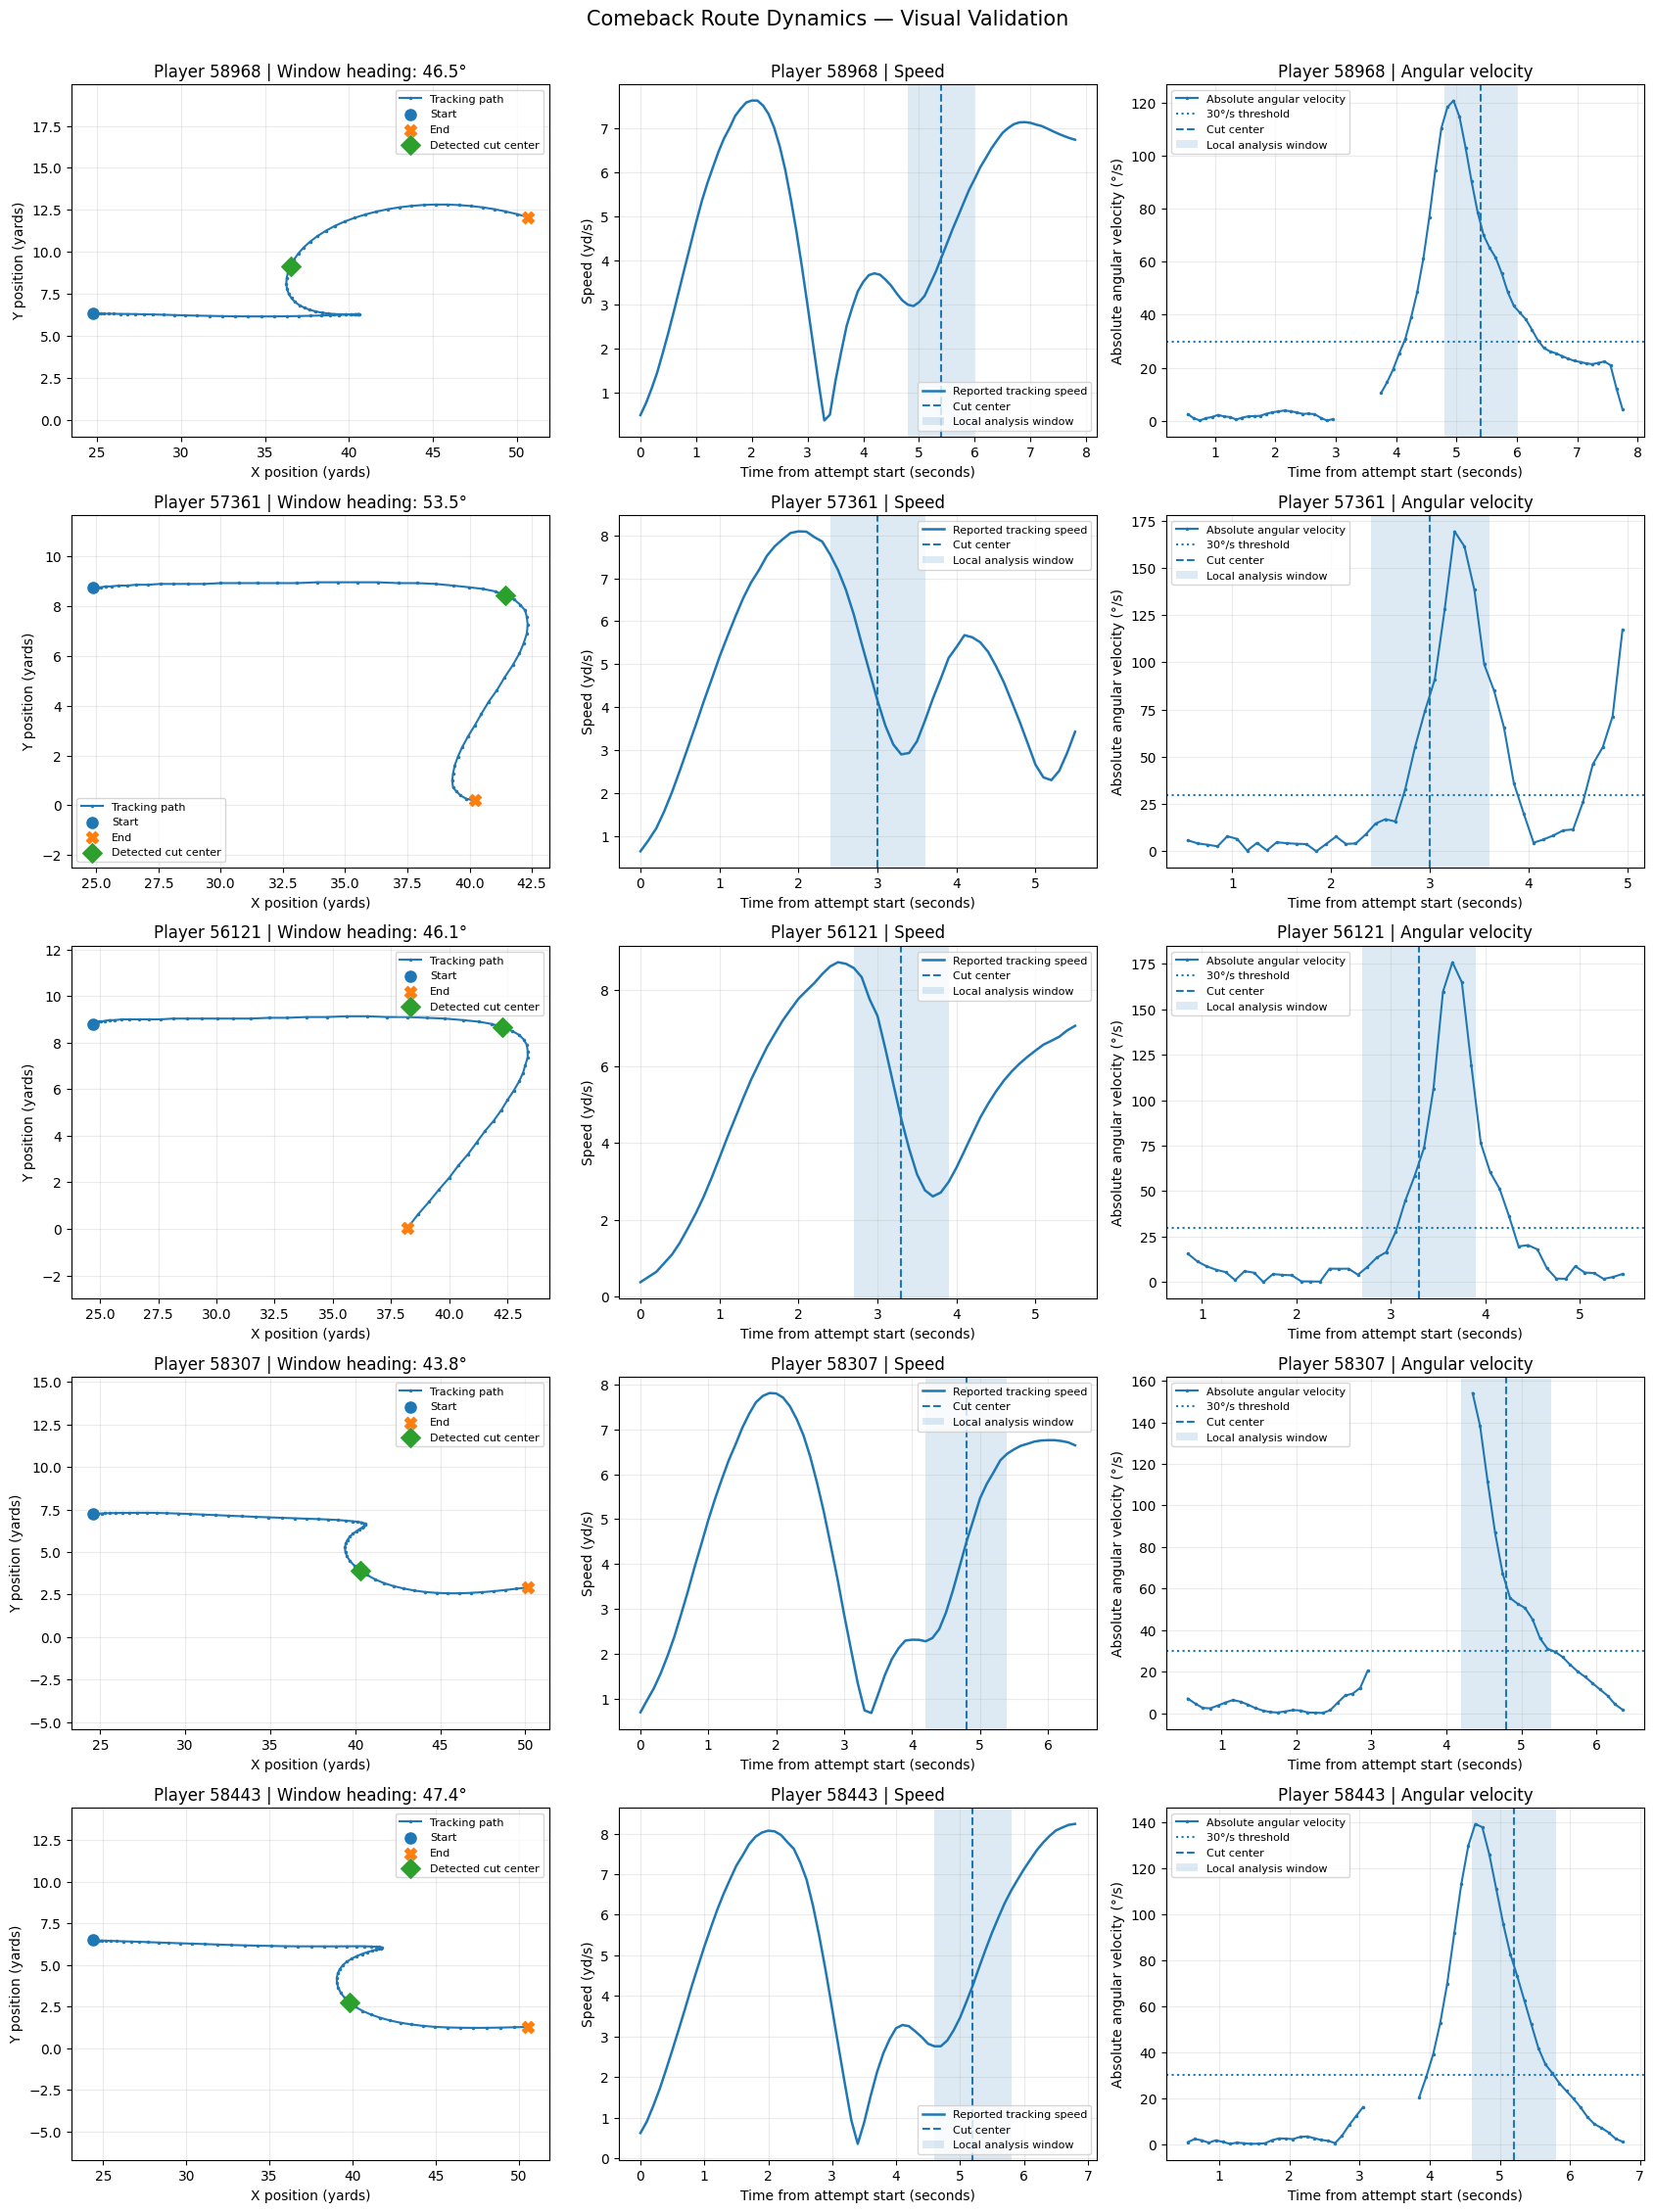


VISUAL VALIDATION NOTES
1. The local window is cut center ± 0.6 seconds.
2. Angular velocity is masked when coordinate speed is below 2.5 yd/s.
3. A high angular-velocity value should coincide with a visible direction change, not merely a low-speed wiggle.
4. Cumulative heading change may include multiple bends; inspect the path for S-shaped or looping movement.
5. Reverse-motion fraction is relative to the initial direction vector, not necessarily football-style backward running.

Cell 11 completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [41]:

# ============================================================
# CELL 11 — VISUAL VALIDATION OF REFINED ROUTE DYNAMICS
# ============================================================
#
# Purpose:
#   Validate that refined angular-velocity and route-shape
#   features correspond to visible movement in the tracking.
#
# For selected Comeback attempts, inspect:
#   1. x-y trajectory and detected cut center
#   2. speed profile
#   3. coordinate-derived angular velocity
#
# Angular velocity is masked when coordinate speed < 2.5 yd/s
# to reduce unstable heading estimates at low speed.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Select attempts for inspection
# ------------------------------------------------------------

COMEBACK_DRILL = "COMEBACK_ROUTE_RIGHT"
ANGULAR_SPEED_THRESHOLD = 2.5
LOCAL_WINDOW_HALF_WIDTH_S = 0.6

# Previously reviewed influential / representative players.
previously_reviewed_ids = [
    58968,
    55990,
    57361,
    56121,
    58307,
]

comeback_dynamics = wr_cut_dynamics_attempts[
    wr_cut_dynamics_attempts["drill_name"] == COMEBACK_DRILL
].copy()

if comeback_dynamics.empty:
    raise ValueError(
        "No Comeback attempts found in wr_cut_dynamics_attempts."
    )

required_attempt_columns = [
    "nfl_id",
    "event_id",
    "cut_time_s",
    "window_heading_change_deg",
]

missing_attempt_columns = [
    col for col in required_attempt_columns
    if col not in comeback_dynamics.columns
]

if missing_attempt_columns:
    raise KeyError(
        "Missing required attempt columns: "
        f"{missing_attempt_columns}"
    )

# Select the largest-heading-change attempt for each previously
# reviewed player, if multiple attempts exist.
selected_rows = []

for player_id in previously_reviewed_ids:
    player_rows = comeback_dynamics[
        comeback_dynamics["nfl_id"] == player_id
    ]

    if not player_rows.empty:
        selected_rows.append(
            player_rows.sort_values(
                "window_heading_change_deg",
                ascending=False
            ).iloc[0]
        )

# Add a median-like attempt, preferably from a player not
# already selected.
median_heading = comeback_dynamics[
    "window_heading_change_deg"
].median()

median_candidates = (
    comeback_dynamics
    .assign(
        distance_from_median=lambda df: (
            df["window_heading_change_deg"] - median_heading
        ).abs()
    )
    .sort_values("distance_from_median")
)

selected_ids = {
    int(row["nfl_id"])
    for row in selected_rows
}

for _, row in median_candidates.iterrows():
    if int(row["nfl_id"]) not in selected_ids:
        selected_rows.append(row)
        break

inspection_attempts = pd.DataFrame(selected_rows)

if inspection_attempts.empty:
    raise ValueError("No attempts selected for visual inspection.")

inspection_attempts = (
    inspection_attempts
    .drop_duplicates(["nfl_id", "event_id"])
    .reset_index(drop=True)
)

print("=" * 75)
print("CELL 11 — SELECTED COMEBACK ATTEMPTS")
print("=" * 75)

summary_columns = [
    col for col in [
        "nfl_id",
        "event_id",
        "window_heading_change_deg",
        "peak_angular_velocity_deg_s",
        "cumulative_heading_change_deg",
        "net_heading_change_deg",
        "turn_duration_above_30_deg_s",
        "local_speed_loss_fraction",
        "reverse_motion_fraction_local",
    ]
    if col in inspection_attempts.columns
]

print(
    inspection_attempts[summary_columns]
    .round(3)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 2. Prepare tracking data
# ------------------------------------------------------------

tracking = wr_player_trk.copy()

tracking["nfl_id"] = pd.to_numeric(
    tracking["nfl_id"],
    errors="coerce"
)

tracking["x"] = pd.to_numeric(
    tracking["x"],
    errors="coerce"
)

tracking["y"] = pd.to_numeric(
    tracking["y"],
    errors="coerce"
)

tracking["s"] = pd.to_numeric(
    tracking["s"],
    errors="coerce"
)

tracking["time"] = pd.to_datetime(
    tracking["time"],
    errors="coerce"
)

tracking = tracking.dropna(
    subset=["nfl_id", "event_id", "x", "y", "s", "time"]
).copy()


# ------------------------------------------------------------
# 3. Plot trajectory, speed, and angular velocity
# ------------------------------------------------------------

n_attempts = len(inspection_attempts)

fig, axes = plt.subplots(
    n_attempts,
    3,
    figsize=(17, 4.5 * n_attempts),
    squeeze=False
)

for row_index, attempt in inspection_attempts.iterrows():

    player_id = int(attempt["nfl_id"])
    event_id = attempt["event_id"]
    cut_time_s = float(attempt["cut_time_s"])

    g = tracking[
        (tracking["nfl_id"] == player_id)
        & (tracking["event_id"].astype(str) == str(event_id))
        & (tracking["drill_name"] == COMEBACK_DRILL)
    ].copy()

    g = (
        g.sort_values("time")
        .drop_duplicates("time")
        .reset_index(drop=True)
    )

    ax_path = axes[row_index, 0]
    ax_speed = axes[row_index, 1]
    ax_angular = axes[row_index, 2]

    if len(g) < 5:
        for ax in [ax_path, ax_speed, ax_angular]:
            ax.set_axis_off()

        ax_path.set_title(
            f"Player {player_id}: insufficient tracking frames"
        )
        continue

    # Elapsed time from the start of this attempt.
    t = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds().to_numpy(dtype=float)

    x = g["x"].to_numpy(dtype=float)
    y = g["y"].to_numpy(dtype=float)
    reported_speed = g["s"].to_numpy(dtype=float)

    if np.any(np.diff(t) <= 0):
        for ax in [ax_path, ax_speed, ax_angular]:
            ax.set_axis_off()

        ax_path.set_title(
            f"Player {player_id}: invalid time sequence"
        )
        continue

    # Smooth positions slightly before deriving direction.
    # A centered 3-frame rolling mean reduces frame-level noise.
    x_smooth = (
        pd.Series(x)
        .rolling(window=3, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )

    y_smooth = (
        pd.Series(y)
        .rolling(window=3, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )

    # Coordinate-derived velocity and speed.
    vx = np.gradient(x_smooth, t)
    vy = np.gradient(y_smooth, t)

    coordinate_speed = np.sqrt(vx**2 + vy**2)

    # Direction of travel in coordinate space.
    heading_rad = np.arctan2(vy, vx)

    # Wrapped heading change between adjacent frames.
    heading_change_rad = np.arctan2(
        np.sin(np.diff(heading_rad)),
        np.cos(np.diff(heading_rad))
    )

    dt = np.diff(t)
    interval_midpoint = (t[:-1] + t[1:]) / 2

    angular_velocity_deg_s = (
        np.abs(np.degrees(heading_change_rad)) / dt
    )

    interval_speed = (
        coordinate_speed[:-1] + coordinate_speed[1:]
    ) / 2

    # Mask angular velocity when direction is unreliable
    # at low coordinate speed.
    valid_angular = (
        np.isfinite(angular_velocity_deg_s)
        & np.isfinite(interval_speed)
        & (interval_speed >= ANGULAR_SPEED_THRESHOLD)
    )

    angular_velocity_plot = np.where(
        valid_angular,
        angular_velocity_deg_s,
        np.nan
    )

    # Local analysis window around the selected cut center.
    window_start = cut_time_s - LOCAL_WINDOW_HALF_WIDTH_S
    window_end = cut_time_s + LOCAL_WINDOW_HALF_WIDTH_S

    heading_value = attempt["window_heading_change_deg"]

    # --------------------------------------------------------
    # Panel A: spatial trajectory
    # --------------------------------------------------------

    ax_path.plot(
        x,
        y,
        marker=".",
        markersize=3,
        linewidth=1.5,
        label="Tracking path"
    )

    ax_path.scatter(
        x[0], y[0],
        s=65,
        marker="o",
        label="Start",
        zorder=4
    )

    ax_path.scatter(
        x[-1], y[-1],
        s=75,
        marker="X",
        label="End",
        zorder=4
    )

    cut_idx = int(np.argmin(np.abs(t - cut_time_s)))

    ax_path.scatter(
        x[cut_idx],
        y[cut_idx],
        s=100,
        marker="D",
        label="Detected cut center",
        zorder=5
    )

    ax_path.set_title(
        f"Player {player_id} | Window heading: {heading_value:.1f}°"
    )
    ax_path.set_xlabel("X position (yards)")
    ax_path.set_ylabel("Y position (yards)")
    ax_path.axis("equal")
    ax_path.grid(alpha=0.25)
    ax_path.legend(fontsize=8)


    # --------------------------------------------------------
    # Panel B: speed profile
    # --------------------------------------------------------

    ax_speed.plot(
        t,
        reported_speed,
        linewidth=1.8,
        label="Reported tracking speed"
    )

    ax_speed.axvline(
        cut_time_s,
        linestyle="--",
        linewidth=1.5,
        label="Cut center"
    )

    ax_speed.axvspan(
        window_start,
        window_end,
        alpha=0.15,
        label="Local analysis window"
    )

    ax_speed.set_title(
        f"Player {player_id} | Speed"
    )
    ax_speed.set_xlabel("Time from attempt start (seconds)")
    ax_speed.set_ylabel("Speed (yd/s)")
    ax_speed.grid(alpha=0.25)
    ax_speed.legend(fontsize=8)


    # --------------------------------------------------------
    # Panel C: coordinate-derived angular velocity
    # --------------------------------------------------------

    ax_angular.plot(
        interval_midpoint,
        angular_velocity_plot,
        marker=".",
        markersize=3,
        linewidth=1.5,
        label="Absolute angular velocity"
    )

    ax_angular.axhline(
        30,
        linestyle=":",
        linewidth=1.5,
        label="30°/s threshold"
    )

    ax_angular.axvline(
        cut_time_s,
        linestyle="--",
        linewidth=1.5,
        label="Cut center"
    )

    ax_angular.axvspan(
        window_start,
        window_end,
        alpha=0.15,
        label="Local analysis window"
    )

    ax_angular.set_title(
        f"Player {player_id} | Angular velocity"
    )
    ax_angular.set_xlabel("Time from attempt start (seconds)")
    ax_angular.set_ylabel("Absolute angular velocity (°/s)")
    ax_angular.grid(alpha=0.25)
    ax_angular.legend(fontsize=8)

plt.suptitle(
    "Comeback Route Dynamics — Visual Validation",
    y=1.002,
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Print interpretation notes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VISUAL VALIDATION NOTES")
print("=" * 75)

print(
    "1. The local window is cut center ± "
    f"{LOCAL_WINDOW_HALF_WIDTH_S:.1f} seconds."
)

print(
    "2. Angular velocity is masked when coordinate speed is below "
    f"{ANGULAR_SPEED_THRESHOLD:.1f} yd/s."
)

print(
    "3. A high angular-velocity value should coincide with a visible "
    "direction change, not merely a low-speed wiggle."
)

print(
    "4. Cumulative heading change may include multiple bends; "
    "inspect the path for S-shaped or looping movement."
)

print(
    "5. Reverse-motion fraction is relative to the initial direction "
    "vector, not necessarily football-style backward running."
)

print("\nCell 11 completed.")


CELL 12 — COMEBACK REVERSAL DETECTION SUMMARY
Comeback attempts analyzed: 107

Detection outcomes:
revised_event_type
projection_reversal             62
original_cut_center_fallback    45

Reversal detection rate: 57.9 %

Event-time shift summary (seconds):
count   107.0000
mean     -0.2030
std       0.9150
min      -2.9000
25%       0.0000
50%       0.0000
75%       0.5000
max       2.3000

Largest detected retreats:
 nfl_id                         event_id  reversal_detected  maximum_retreat_yards  cut_time_s  reversal_time_s  event_time_shift_seconds
  57173 20240302100700_1709415986925_000               True                 3.0950      3.0000           3.4000                    0.4000
  57155 20240302100700_1709415953302_000               True                 2.8540      2.8000           3.2000                    0.4000
  59004 20250301100800_1740875998220_000               True                 2.8420      4.9000           3.2000                   -1.7000
  58284 20250301100800_174

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


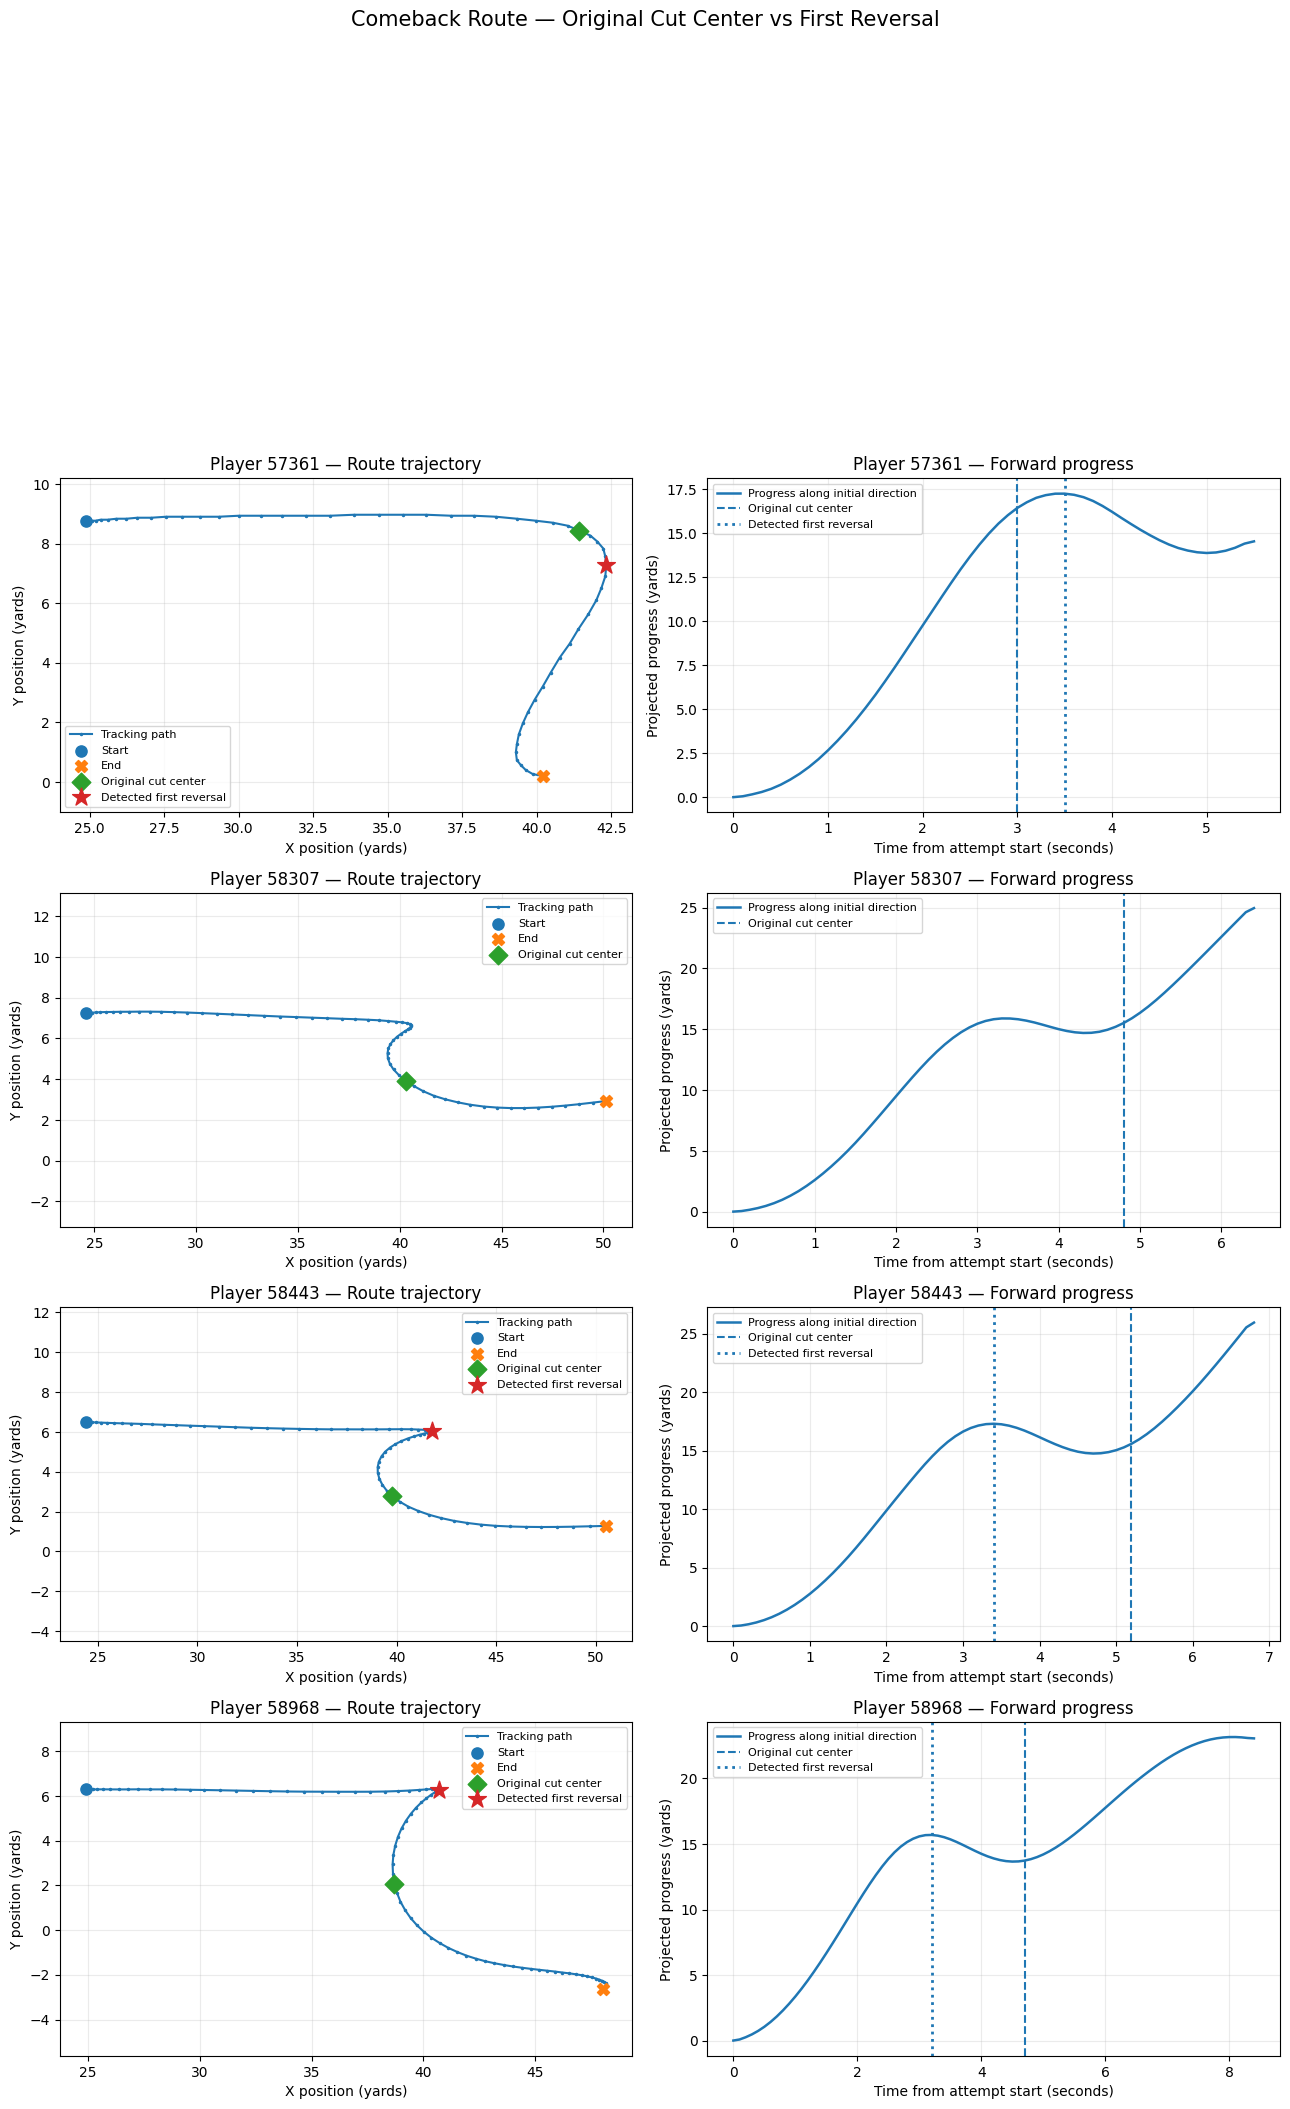


CELL 12 — REVIEWED PLAYER COMPARISON
 nfl_id  reversal_detected  maximum_retreat_yards  cut_time_s  reversal_time_s  revised_event_time_s  event_time_shift_seconds           revised_event_type
  56121              False                    NaN      3.3000              NaN                3.3000                    0.0000 original_cut_center_fallback
  57361               True                 2.6430      3.0000           3.5000                3.5000                    0.5000          projection_reversal
  58307              False                 1.1940      4.8000              NaN                4.8000                    0.0000 original_cut_center_fallback
  58443               True                 2.2200      5.2000           3.4000                3.4000                   -1.8000          projection_reversal
  58968               True                 1.7920      4.7000           3.2000                3.2000                   -1.5000          projection_reversal
  58968               True

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [42]:

# ============================================================
# CELL 12 — COMEBACK ROUTE REVERSAL AND BREAK-POINT DETECTOR
# ============================================================
#
# Purpose:
#   Identify the first meaningful reversal along a player's
#   initial direction of travel.
#
# Method:
#   1. Smooth x/y positions with a 3-frame rolling mean.
#   2. Estimate initial direction from the first 0.5 seconds.
#   3. Project positions onto that initial direction.
#   4. Find the first local progress peak followed by at least
#      1.5 yards of retreat within the next 1.0 second.
#   5. Retain Cell 4's cut center as a fallback when no clear
#      reversal is detected.
#
# Important:
#   This identifies a projection reversal, not necessarily
#   every football route break or change of direction.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Detection settings
# ------------------------------------------------------------

REVERSAL_RETREAT_THRESHOLD_YDS = 1.5
REVERSAL_LOOKAHEAD_SECONDS = 1.0
INITIAL_DIRECTION_SECONDS = 0.5
MIN_CANDIDATE_TIME_SECONDS = 0.8

COMEBACK_DRILL = "COMEBACK_ROUTE_RIGHT"

# Use the same tracking source as Cell 11.
tracking_c12 = wr_player_trk.copy()

tracking_c12["nfl_id"] = pd.to_numeric(
    tracking_c12["nfl_id"], errors="coerce"
)
tracking_c12["x"] = pd.to_numeric(
    tracking_c12["x"], errors="coerce"
)
tracking_c12["y"] = pd.to_numeric(
    tracking_c12["y"], errors="coerce"
)
tracking_c12["time"] = pd.to_datetime(
    tracking_c12["time"], errors="coerce"
)

tracking_c12 = tracking_c12.dropna(
    subset=["nfl_id", "event_id", "x", "y", "time"]
).copy()


# ------------------------------------------------------------
# 2. Identify the reversal point for one attempt
# ------------------------------------------------------------

def detect_projection_reversal(
    attempt_tracking,
    retreat_threshold=REVERSAL_RETREAT_THRESHOLD_YDS,
    lookahead_seconds=REVERSAL_LOOKAHEAD_SECONDS,
    initial_direction_seconds=INITIAL_DIRECTION_SECONDS,
    min_candidate_time=MIN_CANDIDATE_TIME_SECONDS
):
    """
    Detect the first meaningful retreat along the initial
    direction-of-travel axis.

    Returns a dictionary of event measurements.
    """

    g = (
        attempt_tracking
        .sort_values("time")
        .drop_duplicates("time")
        .reset_index(drop=True)
        .copy()
    )

    result = {
        "reversal_detected": False,
        "reversal_time_s": np.nan,
        "reversal_x": np.nan,
        "reversal_y": np.nan,
        "maximum_retreat_yards": np.nan,
        "initial_direction_x": np.nan,
        "initial_direction_y": np.nan,
        "initial_direction_quality": np.nan,
        "reversal_method": "no_clear_reversal"
    }

    if len(g) < 8:
        result["reversal_method"] = "too_few_frames"
        return result

    t = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds().to_numpy(dtype=float)

    x = g["x"].to_numpy(dtype=float)
    y = g["y"].to_numpy(dtype=float)

    if not np.all(np.diff(t) > 0):
        result["reversal_method"] = "invalid_time_sequence"
        return result

    # Smooth coordinates to reduce frame-level noise.
    xs = (
        pd.Series(x)
        .rolling(3, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )

    ys = (
        pd.Series(y)
        .rolling(3, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )

    # Estimate initial direction using the opening movement.
    initial_mask = (
        (t >= 0)
        & (t <= initial_direction_seconds)
    )

    initial_indices = np.where(initial_mask)[0]

    if len(initial_indices) < 3:
        result["reversal_method"] = "insufficient_initial_frames"
        return result

    first_idx = initial_indices[0]
    last_idx = initial_indices[-1]

    dx = xs[last_idx] - xs[first_idx]
    dy = ys[last_idx] - ys[first_idx]

    initial_distance = np.sqrt(dx**2 + dy**2)

    if not np.isfinite(initial_distance) or initial_distance < 0.5:
        result["reversal_method"] = "weak_initial_direction"
        return result

    ux = dx / initial_distance
    uy = dy / initial_distance

    result["initial_direction_x"] = ux
    result["initial_direction_y"] = uy
    result["initial_direction_quality"] = initial_distance

    # Project all smoothed positions onto the initial direction.
    # This produces a one-dimensional forward-progress measure.
    progress = (
        (xs - xs[first_idx]) * ux
        + (ys - ys[first_idx]) * uy
    )

    # Search for the first local maximum in forward progress.
    candidate_indices = []

    for i in range(1, len(progress) - 1):

        if t[i] < min_candidate_time:
            continue

        is_local_peak = (
            progress[i] >= progress[i - 1]
            and progress[i] > progress[i + 1]
        )

        if is_local_peak:
            candidate_indices.append(i)

    # Test each candidate for meaningful retreat within the
    # following lookahead interval.
    for peak_idx in candidate_indices:

        future_mask = (
            (t > t[peak_idx])
            & (t <= t[peak_idx] + lookahead_seconds)
        )

        future_indices = np.where(future_mask)[0]

        if len(future_indices) == 0:
            continue

        future_min_idx = future_indices[
            np.argmin(progress[future_indices])
        ]

        retreat = progress[peak_idx] - progress[future_min_idx]

        if retreat >= retreat_threshold:

            result.update({
                "reversal_detected": True,
                "reversal_time_s": float(t[peak_idx]),
                "reversal_x": float(xs[peak_idx]),
                "reversal_y": float(ys[peak_idx]),
                "maximum_retreat_yards": float(retreat),
                "reversal_method": "projection_reversal"
            })

            return result

    # No qualifying reversal was detected.
    result["maximum_retreat_yards"] = 0.0

    if len(candidate_indices) > 0:
        # Record the largest observed retreat from a local peak,
        # even when it did not meet the detection threshold.
        retreats = []

        for peak_idx in candidate_indices:
            future_mask = (
                (t > t[peak_idx])
                & (t <= t[peak_idx] + lookahead_seconds)
            )

            future_indices = np.where(future_mask)[0]

            if len(future_indices) > 0:
                future_min = np.min(progress[future_indices])
                retreats.append(progress[peak_idx] - future_min)

        if retreats:
            result["maximum_retreat_yards"] = float(max(retreats))

    return result


# ------------------------------------------------------------
# 3. Apply detector to all Comeback attempts
# ------------------------------------------------------------

comeback_attempts_c12 = (
    wr_cut_dynamics_attempts[
        wr_cut_dynamics_attempts["drill_name"] == COMEBACK_DRILL
    ]
    .copy()
    .reset_index(drop=True)
)

c12_results = []

for _, attempt in comeback_attempts_c12.iterrows():

    player_id = attempt["nfl_id"]
    event_id = attempt["event_id"]

    g = tracking_c12[
        (tracking_c12["nfl_id"] == player_id)
        & (tracking_c12["event_id"].astype(str) == str(event_id))
        & (tracking_c12["drill_name"] == COMEBACK_DRILL)
    ].copy()

    detection = detect_projection_reversal(g)

    c12_results.append({
        "nfl_id": player_id,
        "event_id": event_id,
        **detection
    })

wr_comeback_reversal_attempts = pd.DataFrame(c12_results)

# Attach the original Cell 4 cut-center time and existing
# movement features for direct comparison.
comparison_columns = [
    "nfl_id",
    "event_id",
    "cut_time_s",
    "window_heading_change_deg",
    "peak_angular_velocity_deg_s",
    "cumulative_heading_change_deg",
    "net_heading_change_deg",
    "reverse_motion_fraction_local"
]

comparison_columns = [
    c for c in comparison_columns
    if c in comeback_attempts_c12.columns
]

wr_comeback_reversal_attempts = (
    wr_comeback_reversal_attempts
    .merge(
        comeback_attempts_c12[comparison_columns],
        on=["nfl_id", "event_id"],
        how="left",
        validate="one_to_one"
    )
)

# Keep the original cut center when no reversal is detected.
wr_comeback_reversal_attempts[
    "revised_event_time_s"
] = np.where(
    wr_comeback_reversal_attempts["reversal_detected"],
    wr_comeback_reversal_attempts["reversal_time_s"],
    wr_comeback_reversal_attempts["cut_time_s"]
)

wr_comeback_reversal_attempts[
    "revised_event_type"
] = np.where(
    wr_comeback_reversal_attempts["reversal_detected"],
    "projection_reversal",
    "original_cut_center_fallback"
)

# Difference between new event and original cut center.
wr_comeback_reversal_attempts[
    "event_time_shift_seconds"
] = (
    wr_comeback_reversal_attempts["revised_event_time_s"]
    - wr_comeback_reversal_attempts["cut_time_s"]
)


# ------------------------------------------------------------
# 4. Detection summary
# ------------------------------------------------------------

print("=" * 75)
print("CELL 12 — COMEBACK REVERSAL DETECTION SUMMARY")
print("=" * 75)

print(
    "Comeback attempts analyzed:",
    len(wr_comeback_reversal_attempts)
)

print(
    "\nDetection outcomes:"
)

print(
    wr_comeback_reversal_attempts[
        "revised_event_type"
    ].value_counts(dropna=False).to_string()
)

print(
    "\nReversal detection rate:",
    round(
        wr_comeback_reversal_attempts[
            "reversal_detected"
        ].mean() * 100,
        1
    ),
    "%"
)

print(
    "\nEvent-time shift summary (seconds):"
)

print(
    wr_comeback_reversal_attempts[
        "event_time_shift_seconds"
    ].describe().round(3).to_string()
)

print(
    "\nLargest detected retreats:"
)

retreat_summary = (
    wr_comeback_reversal_attempts
    .sort_values(
        "maximum_retreat_yards",
        ascending=False
    )
    [[
        "nfl_id",
        "event_id",
        "reversal_detected",
        "maximum_retreat_yards",
        "cut_time_s",
        "reversal_time_s",
        "event_time_shift_seconds"
    ]]
    .head(10)
)

print(retreat_summary.round(3).to_string(index=False))


# ------------------------------------------------------------
# 5. Visual validation for the five Cell 11 examples
# ------------------------------------------------------------

validation_player_ids = [
    58968,
    57361,
    56121,
    58307,
    58443
]

validation_rows = (
    wr_comeback_reversal_attempts[
        wr_comeback_reversal_attempts["nfl_id"].isin(
            validation_player_ids
        )
    ]
    .drop_duplicates("nfl_id")
    .copy()
)

n_plots = len(validation_rows)

if n_plots == 0:
    print("\nNo previously reviewed players matched.")
else:

    fig, axes = plt.subplots(
        n_plots,
        2,
        figsize=(13, 4.2 * n_plots),
        squeeze=False
    )

    for plot_idx, (_, attempt) in enumerate(
        validation_rows.iterrows()
    ):

        player_id = attempt["nfl_id"]
        event_id = attempt["event_id"]

        g = tracking_c12[
            (tracking_c12["nfl_id"] == player_id)
            & (tracking_c12["event_id"].astype(str) == str(event_id))
            & (tracking_c12["drill_name"] == COMEBACK_DRILL)
        ].copy()

        g = (
            g.sort_values("time")
            .drop_duplicates("time")
            .reset_index(drop=True)
        )

        ax_path = axes[plot_idx, 0]
        ax_progress = axes[plot_idx, 1]

        if len(g) < 5:
            ax_path.set_axis_off()
            ax_progress.set_axis_off()
            continue

        t = (
            g["time"] - g["time"].iloc[0]
        ).dt.total_seconds().to_numpy(dtype=float)

        x = g["x"].to_numpy(dtype=float)
        y = g["y"].to_numpy(dtype=float)

        xs = (
            pd.Series(x)
            .rolling(3, center=True, min_periods=1)
            .mean()
            .to_numpy()
        )

        ys = (
            pd.Series(y)
            .rolling(3, center=True, min_periods=1)
            .mean()
            .to_numpy()
        )

        # Reconstruct the initial direction and progress axis.
        initial_indices = np.where(
            t <= INITIAL_DIRECTION_SECONDS
        )[0]

        if len(initial_indices) < 3:
            ax_path.set_axis_off()
            ax_progress.set_axis_off()
            continue

        i0 = initial_indices[0]
        i1 = initial_indices[-1]

        dx = xs[i1] - xs[i0]
        dy = ys[i1] - ys[i0]
        distance = np.sqrt(dx**2 + dy**2)

        if distance < 0.5:
            ax_path.set_axis_off()
            ax_progress.set_axis_off()
            continue

        ux = dx / distance
        uy = dy / distance

        progress = (
            (xs - xs[i0]) * ux
            + (ys - ys[i0]) * uy
        )

        original_time = attempt["cut_time_s"]
        reversal_time = attempt["reversal_time_s"]

        # Spatial trajectory.
        ax_path.plot(
            x, y,
            linewidth=1.5,
            marker=".",
            markersize=3,
            label="Tracking path"
        )

        ax_path.scatter(
            x[0], y[0],
            marker="o",
            s=65,
            label="Start",
            zorder=4
        )

        ax_path.scatter(
            x[-1], y[-1],
            marker="X",
            s=75,
            label="End",
            zorder=4
        )

        # Original Cell 4 cut center.
        original_idx = int(
            np.argmin(np.abs(t - original_time))
        )

        ax_path.scatter(
            x[original_idx],
            y[original_idx],
            marker="D",
            s=90,
            label="Original cut center",
            zorder=5
        )

        # Newly detected reversal.
        if bool(attempt["reversal_detected"]):
            reversal_idx = int(
                np.argmin(np.abs(t - reversal_time))
            )

            ax_path.scatter(
                x[reversal_idx],
                y[reversal_idx],
                marker="*",
                s=180,
                label="Detected first reversal",
                zorder=6
            )

        ax_path.set_title(
            f"Player {int(player_id)} — Route trajectory"
        )
        ax_path.set_xlabel("X position (yards)")
        ax_path.set_ylabel("Y position (yards)")
        ax_path.axis("equal")
        ax_path.grid(alpha=0.25)
        ax_path.legend(fontsize=8)

        # Initial-direction progress.
        ax_progress.plot(
            t,
            progress,
            linewidth=1.8,
            label="Progress along initial direction"
        )

        ax_progress.axvline(
            original_time,
            linestyle="--",
            label="Original cut center"
        )

        if bool(attempt["reversal_detected"]):
            ax_progress.axvline(
                reversal_time,
                linestyle=":",
                linewidth=2,
                label="Detected first reversal"
            )

        ax_progress.set_title(
            f"Player {int(player_id)} — Forward progress"
        )
        ax_progress.set_xlabel("Time from attempt start (seconds)")
        ax_progress.set_ylabel("Projected progress (yards)")
        ax_progress.grid(alpha=0.25)
        ax_progress.legend(fontsize=8)

    plt.suptitle(
        "Comeback Route — Original Cut Center vs First Reversal",
        y=1.002,
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 6. Final validation table
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 12 — REVIEWED PLAYER COMPARISON")
print("=" * 75)

review_columns = [
    "nfl_id",
    "reversal_detected",
    "maximum_retreat_yards",
    "cut_time_s",
    "reversal_time_s",
    "revised_event_time_s",
    "event_time_shift_seconds",
    "revised_event_type"
]

print(
    wr_comeback_reversal_attempts[
        wr_comeback_reversal_attempts["nfl_id"].isin(
            validation_player_ids
        )
    ][review_columns]
    .round(3)
    .to_string(index=False)
)

print("\nCell 12 completed.")


CELL 13 — OVERALL THRESHOLD SENSITIVITY
 retreat_threshold_yards  attempts  detected_reversals  detection_rate_pct  median_event_shift
                  0.7500       107                  86             80.3740              0.0000
                  1.0000       107                  81             75.7010              0.0000
                  1.2500       107                  69             64.4860              0.0000
                  1.5000       107                  62             57.9440              0.0000
                  2.0000       107                  30             28.0370              0.0000

CELL 13 — DETECTION CONSISTENCY
number_of_thresholds_detected
0    21
1     5
2    12
3     7
4    32
5    30

CELL 13 — REVIEWED ATTEMPT SENSITIVITY
 nfl_id                         event_id  retreat_threshold_yards  reversal_detected  maximum_retreat_yards  original_cut_time_s  reversal_time_s  event_time_shift_seconds
  56121    6414e5fde3d8e72dcdc8d4a7-2023                   0.7500  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


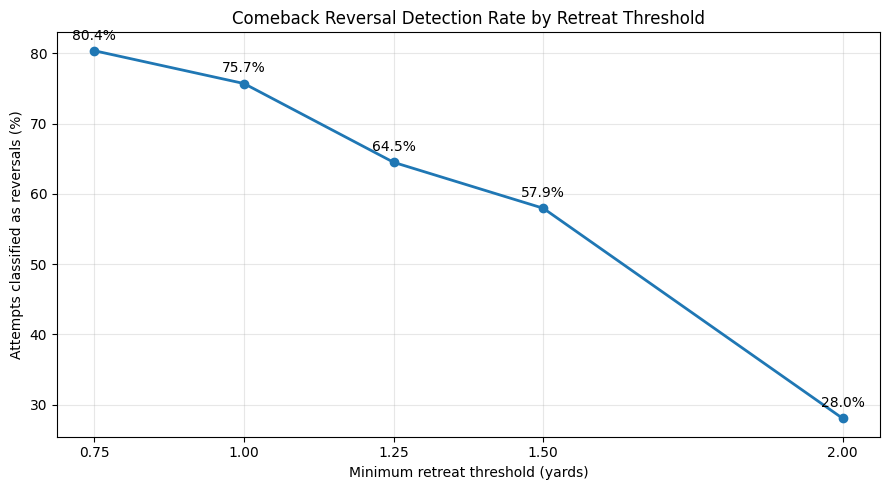


CELL 13 — PLAYER 58307 CHECK
                        event_id  retreat_threshold_yards  reversal_detected  maximum_retreat_yards  reversal_time_s
20250301100700_1740866727822_000                   0.7500               True                 1.1940           3.3000
20250301100700_1740866727822_000                   1.0000               True                 1.1940           3.3000
20250301100700_1740866727822_000                   1.2500              False                 1.1940              NaN
20250301100700_1740866727822_000                   1.5000              False                 1.1940              NaN
20250301100700_1740866727822_000                   2.0000              False                 1.1940              NaN

Cell 13 completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [43]:

# ============================================================
# CELL 13 — REVERSAL THRESHOLD SENSITIVITY ANALYSIS
# ============================================================
#
# Purpose:
#   Determine how sensitive reversal detection is to the
#   minimum retreat threshold.
#
# Thresholds tested:
#   0.75, 1.00, 1.25, 1.50, 2.00 yards
#
# We compare:
#   1. Overall detection rate
#   2. Detection consistency across thresholds
#   3. Exact reviewed attempts from Cell 11
#
# No existing Cell 4, 10, or 12 results are overwritten.
# ============================================================

RETREAT_THRESHOLDS = [0.75, 1.00, 1.25, 1.50, 2.00]

sensitivity_results = []

for threshold in RETREAT_THRESHOLDS:

    for _, attempt in comeback_attempts_c12.iterrows():

        player_id = attempt["nfl_id"]
        event_id = attempt["event_id"]

        g = tracking_c12[
            (tracking_c12["nfl_id"] == player_id)
            & (tracking_c12["event_id"].astype(str) == str(event_id))
            & (tracking_c12["drill_name"] == COMEBACK_DRILL)
        ].copy()

        detection = detect_projection_reversal(
            g,
            retreat_threshold=threshold
        )

        original_cut_time = attempt["cut_time_s"]

        revised_time = (
            detection["reversal_time_s"]
            if detection["reversal_detected"]
            else original_cut_time
        )

        sensitivity_results.append({
            "nfl_id": player_id,
            "event_id": event_id,
            "retreat_threshold_yards": threshold,
            "reversal_detected": detection["reversal_detected"],
            "maximum_retreat_yards": detection["maximum_retreat_yards"],
            "reversal_time_s": detection["reversal_time_s"],
            "original_cut_time_s": original_cut_time,
            "event_time_shift_seconds": (
                revised_time - original_cut_time
            )
        })

wr_reversal_sensitivity = pd.DataFrame(sensitivity_results)


# ------------------------------------------------------------
# 1. Overall detection rates
# ------------------------------------------------------------

sensitivity_summary = (
    wr_reversal_sensitivity
    .groupby("retreat_threshold_yards")
    .agg(
        attempts=("event_id", "count"),
        detected_reversals=("reversal_detected", "sum"),
        detection_rate=("reversal_detected", "mean"),
        median_event_shift=("event_time_shift_seconds", "median")
    )
    .reset_index()
)

sensitivity_summary["detection_rate_pct"] = (
    sensitivity_summary["detection_rate"] * 100
)

print("=" * 75)
print("CELL 13 — OVERALL THRESHOLD SENSITIVITY")
print("=" * 75)

print(
    sensitivity_summary[
        [
            "retreat_threshold_yards",
            "attempts",
            "detected_reversals",
            "detection_rate_pct",
            "median_event_shift"
        ]
    ].round(3).to_string(index=False)
)


# ------------------------------------------------------------
# 2. Detection consistency across thresholds
# ------------------------------------------------------------

detection_matrix = (
    wr_reversal_sensitivity
    .pivot(
        index=["nfl_id", "event_id"],
        columns="retreat_threshold_yards",
        values="reversal_detected"
    )
)

detection_matrix.columns = [
    f"detected_at_{threshold:.2f}yd"
    for threshold in detection_matrix.columns
]

detection_matrix = detection_matrix.reset_index()

print("\n" + "=" * 75)
print("CELL 13 — DETECTION CONSISTENCY")
print("=" * 75)

detection_columns = [
    col for col in detection_matrix.columns
    if col.startswith("detected_at_")
]

detection_matrix["number_of_thresholds_detected"] = (
    detection_matrix[detection_columns]
    .sum(axis=1)
)

print(
    detection_matrix[
        "number_of_thresholds_detected"
    ].value_counts().sort_index().to_string()
)


# ------------------------------------------------------------
# 3. Exact reviewed attempts from Cell 11
# ------------------------------------------------------------

reviewed_keys = (
    inspection_attempts[["nfl_id", "event_id"]]
    .drop_duplicates()
    .copy()
)

reviewed_sensitivity = wr_reversal_sensitivity.merge(
    reviewed_keys,
    on=["nfl_id", "event_id"],
    how="inner",
    validate="many_to_one"
)

print("\n" + "=" * 75)
print("CELL 13 — REVIEWED ATTEMPT SENSITIVITY")
print("=" * 75)

print(
    reviewed_sensitivity[
        [
            "nfl_id",
            "event_id",
            "retreat_threshold_yards",
            "reversal_detected",
            "maximum_retreat_yards",
            "original_cut_time_s",
            "reversal_time_s",
            "event_time_shift_seconds"
        ]
    ]
    .sort_values(
        ["nfl_id", "event_id", "retreat_threshold_yards"]
    )
    .round(3)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 4. Plot detection rate by threshold
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    sensitivity_summary["retreat_threshold_yards"],
    sensitivity_summary["detection_rate_pct"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Comeback Reversal Detection Rate by Retreat Threshold"
)
ax.set_xlabel("Minimum retreat threshold (yards)")
ax.set_ylabel("Attempts classified as reversals (%)")
ax.set_xticks(RETREAT_THRESHOLDS)
ax.grid(alpha=0.3)

for _, row in sensitivity_summary.iterrows():
    ax.annotate(
        f"{row['detection_rate_pct']:.1f}%",
        (
            row["retreat_threshold_yards"],
            row["detection_rate_pct"]
        ),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Explicit check for the 58307 example
# ------------------------------------------------------------

player_58307 = reviewed_sensitivity[
    reviewed_sensitivity["nfl_id"] == 58307
].copy()

if not player_58307.empty:

    print("\n" + "=" * 75)
    print("CELL 13 — PLAYER 58307 CHECK")
    print("=" * 75)

    print(
        player_58307[
            [
                "event_id",
                "retreat_threshold_yards",
                "reversal_detected",
                "maximum_retreat_yards",
                "reversal_time_s"
            ]
        ]
        .sort_values("retreat_threshold_yards")
        .round(3)
        .to_string(index=False)
    )

print("\nCell 13 completed.")


CELL 14 — ATTEMPT COUNTS BY RETREAT GROUP


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,attempts,mean_retreat,median_retreat,detected_at_1_5
audit_group,,,,
Strong,30,2.3920,2.2870,30
Moderate,32,1.7760,1.7840,32
Borderline,19,1.2230,1.1880,0
Weak / no measurable retreat,26,0.5820,0.7340,0



CELL 14 — SELECTED ATTEMPTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,event_id,audit_group,maximum_retreat_yards,reversal_detected,original_cut_time_s,reversal_time_s
0,56559,6414e684e3d8e72dcdcb4fa1-2023,Strong,2.0020,True,2.9000,3.5000
1,58997,20250301100800_1740875988279_000,Strong,2.2850,True,4.8000,3.3000
2,57173,20240302100700_1709415986925_000,Strong,3.0950,True,3.0000,3.4000
3,57201,20240302100700_1709415831630_000,Moderate,1.5720,True,2.9000,3.5000
4,58968,20250301100800_1740876026215_000,Moderate,1.7920,True,4.7000,3.2000
5,55965,6414e684e3d8e72dcdcb4fa4-2023,Moderate,1.9800,True,3.1000,3.6000
6,58751,20250301100700_1740866834858_000,Borderline,1.0510,False,7.2000,NaN
7,59278,20250301100700_1740866824051_000,Borderline,1.1880,False,4.8000,NaN
8,55939,6414e684e3d8e72dcdcb4f9f-2023,Borderline,1.5000,False,3.0000,NaN
9,55934,6414e5fde3d8e72dcdc8d49e-2023,Weak / no measurable retreat,NaN,False,3.2000,NaN


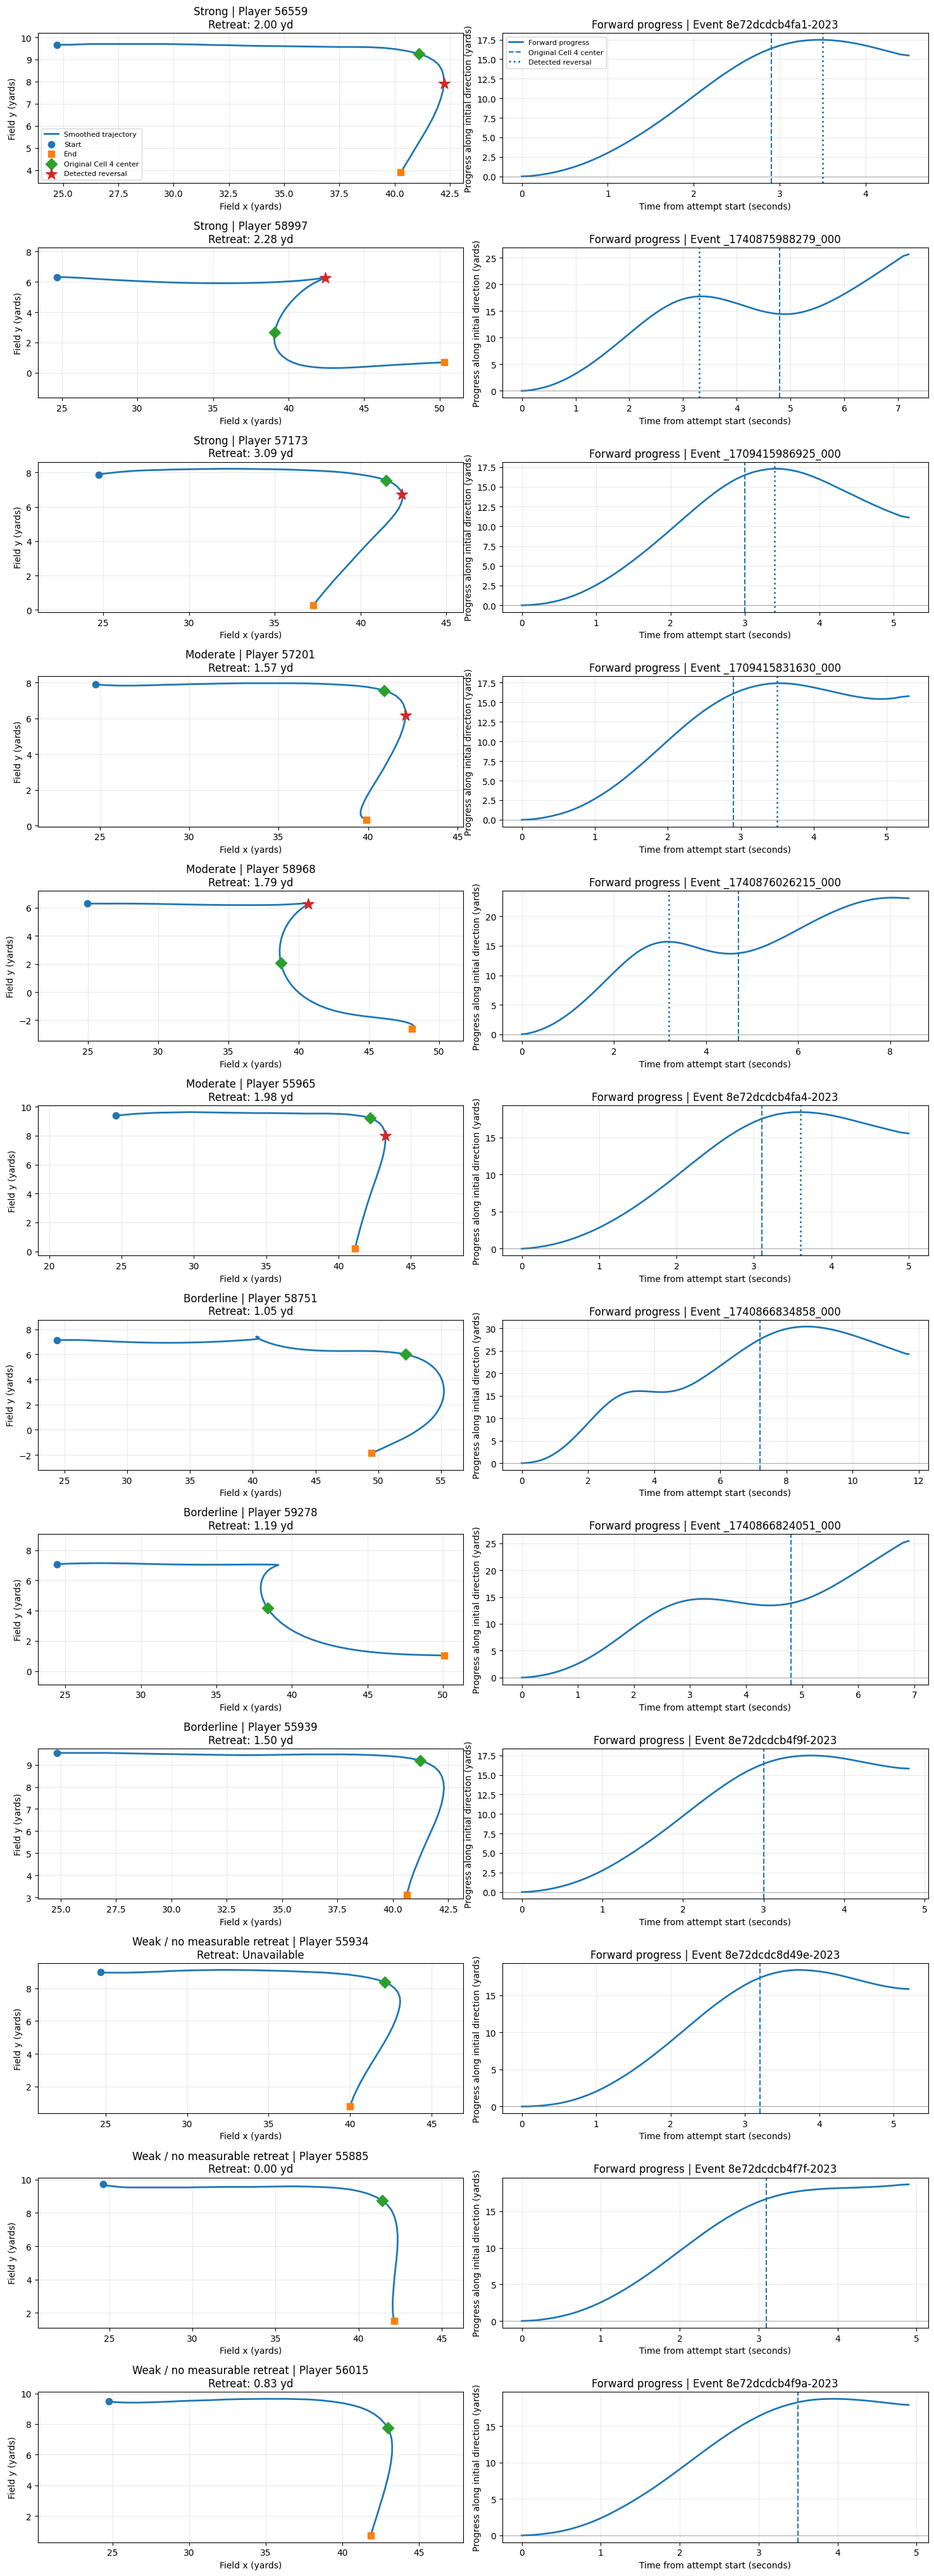


CELL 14 — AUDIT COMPLETION
Selected attempts: 12
Successfully plotted: 12
Tracking unavailable / insufficient: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [44]:

# ============================================================================
# CELL 14 — STRATIFIED VISUAL AUDIT OF COMEBACK REVERSAL DETECTOR
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# 1. Use the 1.5-yard sensitivity results as the audit reference
# ---------------------------------------------------------------------------

AUDIT_THRESHOLD = 1.50
SAMPLES_PER_GROUP = 3

audit_base = (
    wr_reversal_sensitivity[
        wr_reversal_sensitivity["retreat_threshold_yards"].eq(AUDIT_THRESHOLD)
    ]
    .copy()
)

required_columns = [
    "nfl_id",
    "event_id",
    "maximum_retreat_yards",
    "original_cut_time_s",
    "reversal_time_s",
    "reversal_detected",
]

missing_columns = [c for c in required_columns if c not in audit_base.columns]

if missing_columns:
    raise ValueError(f"Missing required audit columns: {missing_columns}")

# Preserve exact attempt identity.
audit_base["nfl_id_key"] = audit_base["nfl_id"].astype(str)
audit_base["event_id_key"] = audit_base["event_id"].astype(str)

if audit_base.duplicated(["nfl_id_key", "event_id_key"]).any():
    raise ValueError("Duplicate player/event combinations found in audit_base.")

# ---------------------------------------------------------------------------
# 2. Assign mutually exclusive retreat groups
# ---------------------------------------------------------------------------

def classify_retreat(value):
    if pd.isna(value):
        return "Weak / no measurable retreat"
    elif value >= 2.0:
        return "Strong"
    elif value >= 1.5:
        return "Moderate"
    elif value >= 1.0:
        return "Borderline"
    else:
        return "Weak / no measurable retreat"


audit_base["audit_group"] = audit_base["maximum_retreat_yards"].apply(
    classify_retreat
)

group_order = [
    "Strong",
    "Moderate",
    "Borderline",
    "Weak / no measurable retreat",
]

print("=" * 85)
print("CELL 14 — ATTEMPT COUNTS BY RETREAT GROUP")
print("=" * 85)

group_summary = (
    audit_base.groupby("audit_group", observed=False)
    .agg(
        attempts=("event_id", "count"),
        mean_retreat=("maximum_retreat_yards", "mean"),
        median_retreat=("maximum_retreat_yards", "median"),
        detected_at_1_5=("reversal_detected", "sum"),
    )
    .reindex(group_order)
)

display(group_summary.round(3))

# ---------------------------------------------------------------------------
# 3. Select representative attempts from each group
# ---------------------------------------------------------------------------

def select_representatives(group, n=SAMPLES_PER_GROUP):
    """Select low, middle, and high retreat examples without replacement."""

    group = group.copy()

    if group.empty:
        return group

    group = group.sort_values(
        "maximum_retreat_yards",
        na_position="first"
    )

    if len(group) <= n:
        return group

    # For the weak group, try to include an unavailable/NaN example.
    if group["maximum_retreat_yards"].isna().any():
        missing_example = group[group["maximum_retreat_yards"].isna()].head(1)
        measurable = group[group["maximum_retreat_yards"].notna()]

        remaining_n = n - len(missing_example)

        if remaining_n > 0 and not measurable.empty:
            positions = np.linspace(
                0, len(measurable) - 1,
                min(remaining_n, len(measurable))
            ).round().astype(int)

            selected = measurable.iloc[positions]
            result = pd.concat([missing_example, selected])
        else:
            result = missing_example

        return result.drop_duplicates(
            ["nfl_id_key", "event_id_key"]
        ).head(n)

    # Otherwise select examples spread across the retreat distribution.
    positions = np.linspace(
        0, len(group) - 1, n
    ).round().astype(int)

    return group.iloc[positions].drop_duplicates(
        ["nfl_id_key", "event_id_key"]
    )


selected_attempts = pd.concat(
    [
        select_representatives(
            audit_base[audit_base["audit_group"].eq(group)]
        )
        for group in group_order
    ],
    ignore_index=True
)

selected_attempts = selected_attempts.drop_duplicates(
    ["nfl_id_key", "event_id_key"]
).reset_index(drop=True)

print("\n" + "=" * 85)
print("CELL 14 — SELECTED ATTEMPTS")
print("=" * 85)

display(
    selected_attempts[
        [
            "nfl_id",
            "event_id",
            "audit_group",
            "maximum_retreat_yards",
            "reversal_detected",
            "original_cut_time_s",
            "reversal_time_s",
        ]
    ].round(3)
)

# ---------------------------------------------------------------------------
# 4. Prepare player tracking data
# ---------------------------------------------------------------------------

audit_tracking = wr_player_trk.copy()

required_tracking_columns = [
    "nfl_id", "event_id", "time", "x", "y"
]

missing_tracking = [
    c for c in required_tracking_columns
    if c not in audit_tracking.columns
]

if missing_tracking:
    raise ValueError(
        f"Missing tracking columns: {missing_tracking}"
    )

audit_tracking["nfl_id_key"] = audit_tracking["nfl_id"].astype(str)
audit_tracking["event_id_key"] = audit_tracking["event_id"].astype(str)

audit_tracking["time"] = pd.to_datetime(
    audit_tracking["time"], errors="coerce"
)

audit_tracking = audit_tracking.dropna(
    subset=["time", "x", "y"]
).copy()

# ---------------------------------------------------------------------------
# 5. Plot trajectory and forward progress for each selected attempt
# ---------------------------------------------------------------------------

def prepare_attempt_path(attempt):
    """Retrieve one exact player/event tracking sequence."""

    g = audit_tracking[
        audit_tracking["nfl_id_key"].eq(attempt["nfl_id_key"])
        & audit_tracking["event_id_key"].eq(attempt["event_id_key"])
    ].copy()

    if g.empty:
        return None

    g = g.sort_values("time").reset_index(drop=True)

    # Relative time in seconds from the beginning of this tracking sequence.
    g["time_s"] = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds()

    # Smooth position slightly to reduce frame-to-frame tracking noise.
    g["x_smooth"] = g["x"].rolling(
        window=3, center=True, min_periods=1
    ).mean()

    g["y_smooth"] = g["y"].rolling(
        window=3, center=True, min_periods=1
    ).mean()

    # Estimate initial direction from the first half-second of movement.
    initial = g[g["time_s"] <= 0.5]

    if len(initial) < 2:
        initial = g.head(min(5, len(g)))

    dx = initial["x_smooth"].iloc[-1] - g["x_smooth"].iloc[0]
    dy = initial["y_smooth"].iloc[-1] - g["y_smooth"].iloc[0]

    norm = np.sqrt(dx**2 + dy**2)

    if not np.isfinite(norm) or norm < 0.05:
        return None

    dir_x = dx / norm
    dir_y = dy / norm

    # Project the smoothed path onto the estimated initial direction.
    g["forward_progress_yards"] = (
        (g["x_smooth"] - g["x_smooth"].iloc[0]) * dir_x
        + (g["y_smooth"] - g["y_smooth"].iloc[0]) * dir_y
    )

    return g


# ---------------------------------------------------------------------------
# 6. Render audit plots
# ---------------------------------------------------------------------------

n_attempts = len(selected_attempts)

if n_attempts == 0:
    print("No attempts available for visual audit.")
else:
    fig, axes = plt.subplots(
        n_attempts, 2,
        figsize=(15, max(4, 3.4 * n_attempts)),
        squeeze=False
    )

    plotted = 0
    unavailable = []

    for row_idx, (_, attempt) in enumerate(
        selected_attempts.iterrows()
    ):

        g = prepare_attempt_path(attempt)

        ax_path = axes[row_idx, 0]
        ax_progress = axes[row_idx, 1]

        player_id = attempt["nfl_id"]
        event_id = attempt["event_id"]
        group = attempt["audit_group"]
        retreat = attempt["maximum_retreat_yards"]

        title_retreat = (
            f"{retreat:.2f} yd"
            if pd.notna(retreat)
            else "Unavailable"
        )

        if g is None or len(g) < 3:
            ax_path.set_title(
                f"Player {player_id} — tracking unavailable"
            )
            ax_progress.set_visible(False)
            unavailable.append((player_id, event_id))
            continue

        plotted += 1

        # Original Cell 4 center and candidate reversal time.
        original_time = attempt["original_cut_time_s"]
        reversal_time = attempt["reversal_time_s"]

        # ---- Left: XY trajectory ----
        ax_path.plot(
            g["x_smooth"],
            g["y_smooth"],
            linewidth=2,
            label="Smoothed trajectory"
        )

        ax_path.scatter(
            g["x_smooth"].iloc[0],
            g["y_smooth"].iloc[0],
            marker="o",
            s=55,
            label="Start",
            zorder=5
        )

        ax_path.scatter(
            g["x_smooth"].iloc[-1],
            g["y_smooth"].iloc[-1],
            marker="s",
            s=55,
            label="End",
            zorder=5
        )

        # Mark the original Cell 4 event center.
        if pd.notna(original_time):
            original_idx = (
                g["time_s"] - float(original_time)
            ).abs().idxmin()

            ax_path.scatter(
                g.loc[original_idx, "x_smooth"],
                g.loc[original_idx, "y_smooth"],
                marker="D",
                s=85,
                label="Original Cell 4 center",
                zorder=7
            )

        # Mark the projection-reversal event.
        if pd.notna(reversal_time):
            reversal_idx = (
                g["time_s"] - float(reversal_time)
            ).abs().idxmin()

            ax_path.scatter(
                g.loc[reversal_idx, "x_smooth"],
                g.loc[reversal_idx, "y_smooth"],
                marker="*",
                s=170,
                label="Detected reversal",
                zorder=8
            )

        ax_path.set_title(
            f"{group} | Player {player_id}\n"
            f"Retreat: {title_retreat}"
        )
        ax_path.set_xlabel("Field x (yards)")
        ax_path.set_ylabel("Field y (yards)")
        ax_path.grid(alpha=0.25)
        ax_path.set_aspect("equal", adjustable="datalim")

        # ---- Right: forward progress ----
        ax_progress.plot(
            g["time_s"],
            g["forward_progress_yards"],
            linewidth=2,
            label="Forward progress"
        )

        ax_progress.axhline(
            0, color="gray", linewidth=0.8, alpha=0.6
        )

        if pd.notna(original_time):
            ax_progress.axvline(
                float(original_time),
                linestyle="--",
                linewidth=1.5,
                label="Original Cell 4 center"
            )

        if pd.notna(reversal_time):
            ax_progress.axvline(
                float(reversal_time),
                linestyle=":",
                linewidth=2,
                label="Detected reversal"
            )

        ax_progress.set_title(
            f"Forward progress | Event {str(event_id)[-18:]}"
        )
        ax_progress.set_xlabel("Time from attempt start (seconds)")
        ax_progress.set_ylabel("Progress along initial direction (yards)")
        ax_progress.grid(alpha=0.25)

        # Show legends only on the first plotted row to reduce clutter.
        if row_idx == 0:
            ax_path.legend(fontsize=8, loc="best")
            ax_progress.legend(fontsize=8, loc="best")

    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 85)
    print("CELL 14 — AUDIT COMPLETION")
    print("=" * 85)
    print(f"Selected attempts: {n_attempts}")
    print(f"Successfully plotted: {plotted}")
    print(f"Tracking unavailable / insufficient: {len(unavailable)}")

    if unavailable:
        print("\nAttempts needing tracking review:")
        display(pd.DataFrame(
            unavailable,
            columns=["nfl_id", "event_id"]
        ))


CELL 15 — PLAYER 55934 DETECTOR DIAGNOSTIC
Player: 55934
Event: 6414e5fde3d8e72dcdc8d49e-2023
Tracking frames: 53
Tracking duration: 5.20 seconds
Cell 13 maximum retreat: nan

Candidate peaks and subsequent retreats:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,peak_time_s,peak_progress_yards,trough_time_s,trough_progress_yards,retreat_yards,time_to_trough_s,remaining_tracking_s
0,3.7000,18.4350,4.7000,16.6310,1.8040,1.0000,1.5000


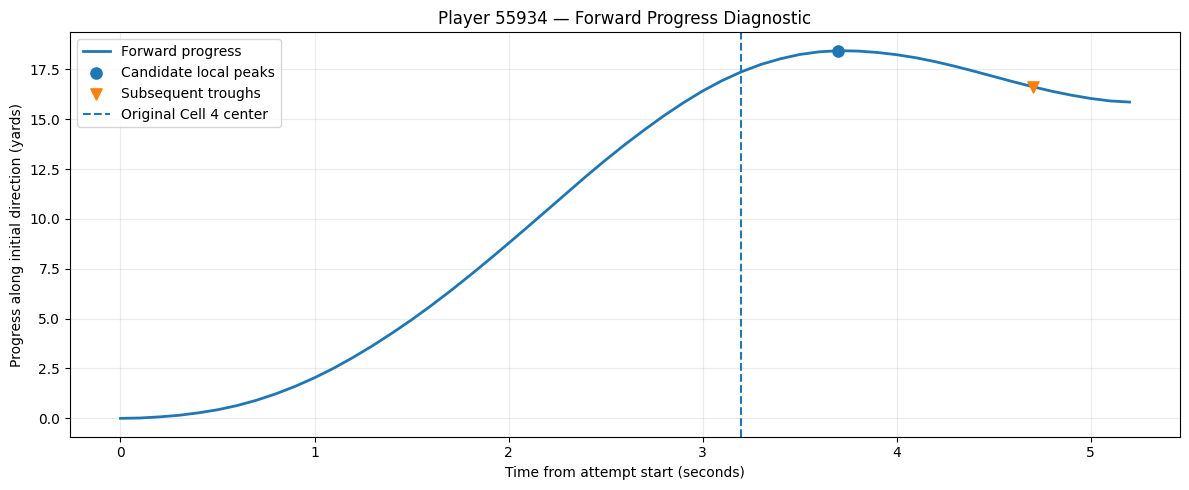

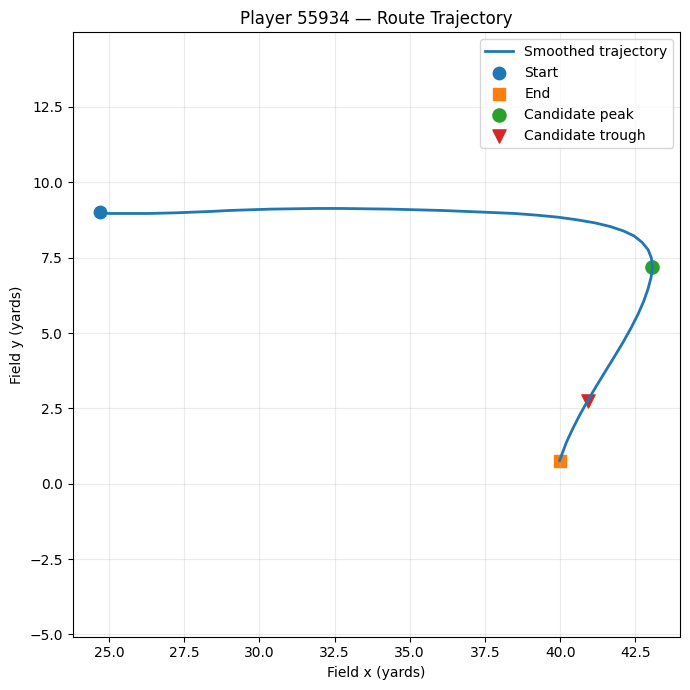


CELL 15 — DIAGNOSTIC SUMMARY
Largest diagnostic retreat: 1.804 yards
Peak time: 3.70 seconds
Trough time: 4.70 seconds
Time from peak to trough: 1.00 seconds
Tracking remaining after peak: 1.50 seconds


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [45]:

# ============================================================================
# CELL 15 — DIAGNOSTIC INVESTIGATION OF MISSED REVERSALS
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Focus on the attempt identified during Cell 14.
DIAGNOSTIC_PLAYER_ID = 55934

diagnostic_attempts = audit_base[
    audit_base["nfl_id_key"].eq(str(DIAGNOSTIC_PLAYER_ID))
].copy()

if diagnostic_attempts.empty:
    raise ValueError(
        f"No audit record found for player {DIAGNOSTIC_PLAYER_ID}."
    )

# Use the exact event ID, not player ID alone.
diagnostic_attempt = diagnostic_attempts.iloc[0]

diagnostic_path = prepare_attempt_path(diagnostic_attempt)

if diagnostic_path is None or len(diagnostic_path) < 5:
    raise ValueError("Insufficient tracking data for diagnostic attempt.")

g = diagnostic_path.copy().reset_index(drop=True)

# ---------------------------------------------------------------------------
# 1. Recalculate the largest forward-progress decline after local peaks
# ---------------------------------------------------------------------------

LOOKAHEAD_SECONDS = 1.0
MIN_CANDIDATE_TIME_SECONDS = 0.8

progress = g["forward_progress_yards"].to_numpy()
times = g["time_s"].to_numpy()

candidate_rows = []

for i in range(1, len(g) - 1):

    # A simple local maximum in projected forward progress.
    is_local_peak = (
        progress[i] >= progress[i - 1]
        and progress[i] > progress[i + 1]
    )

    if not is_local_peak:
        continue

    peak_time = times[i]

    if peak_time < MIN_CANDIDATE_TIME_SECONDS:
        continue

    # Look forward no more than the configured look-ahead period.
    future_indices = np.where(
        (times > peak_time)
        & (times <= peak_time + LOOKAHEAD_SECONDS)
    )[0]

    if len(future_indices) == 0:
        continue

    trough_idx = future_indices[
        np.argmin(progress[future_indices])
    ]

    retreat = progress[i] - progress[trough_idx]

    candidate_rows.append({
        "peak_time_s": peak_time,
        "peak_progress_yards": progress[i],
        "trough_time_s": times[trough_idx],
        "trough_progress_yards": progress[trough_idx],
        "retreat_yards": retreat,
        "time_to_trough_s": times[trough_idx] - peak_time,
        "remaining_tracking_s": times[-1] - peak_time,
    })

candidate_table = pd.DataFrame(candidate_rows)

print("=" * 85)
print("CELL 15 — PLAYER 55934 DETECTOR DIAGNOSTIC")
print("=" * 85)

print(f"Player: {diagnostic_attempt['nfl_id']}")
print(f"Event: {diagnostic_attempt['event_id']}")
print(f"Tracking frames: {len(g)}")
print(f"Tracking duration: {times[-1]:.2f} seconds")
print(
    "Cell 13 maximum retreat:",
    diagnostic_attempt["maximum_retreat_yards"]
)

if candidate_table.empty:
    print("\nNo local progress peaks satisfied the diagnostic timing rules.")
else:
    print("\nCandidate peaks and subsequent retreats:")
    display(
        candidate_table.sort_values(
            "retreat_yards", ascending=False
        ).round(3)
    )

# ---------------------------------------------------------------------------
# 2. Inspect the complete forward-progress curve
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    times,
    progress,
    linewidth=2,
    label="Forward progress"
)

# Show all candidate local peaks.
if not candidate_table.empty:
    ax.scatter(
        candidate_table["peak_time_s"],
        candidate_table["peak_progress_yards"],
        marker="o",
        s=65,
        label="Candidate local peaks",
        zorder=5
    )

    ax.scatter(
        candidate_table["trough_time_s"],
        candidate_table["trough_progress_yards"],
        marker="v",
        s=65,
        label="Subsequent troughs",
        zorder=5
    )

# Original Cell 4 event center.
original_time = diagnostic_attempt["original_cut_time_s"]

if pd.notna(original_time):
    ax.axvline(
        float(original_time),
        linestyle="--",
        linewidth=1.5,
        label="Original Cell 4 center"
    )

# Detected reversal, if any.
reversal_time = diagnostic_attempt["reversal_time_s"]

if pd.notna(reversal_time):
    ax.axvline(
        float(reversal_time),
        linestyle=":",
        linewidth=2,
        label="Detected reversal"
    )

ax.set_title(
    f"Player {DIAGNOSTIC_PLAYER_ID} — Forward Progress Diagnostic"
)
ax.set_xlabel("Time from attempt start (seconds)")
ax.set_ylabel("Progress along initial direction (yards)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 3. Inspect the route trajectory
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    g["x_smooth"],
    g["y_smooth"],
    linewidth=2,
    label="Smoothed trajectory"
)

ax.scatter(
    g["x_smooth"].iloc[0],
    g["y_smooth"].iloc[0],
    marker="o",
    s=80,
    label="Start"
)

ax.scatter(
    g["x_smooth"].iloc[-1],
    g["y_smooth"].iloc[-1],
    marker="s",
    s=80,
    label="End"
)

if not candidate_table.empty:
    for _, candidate in candidate_table.iterrows():

        peak_idx = (
            g["time_s"] - candidate["peak_time_s"]
        ).abs().idxmin()

        trough_idx = (
            g["time_s"] - candidate["trough_time_s"]
        ).abs().idxmin()

        ax.scatter(
            g.loc[peak_idx, "x_smooth"],
            g.loc[peak_idx, "y_smooth"],
            marker="o",
            s=90,
            label="Candidate peak"
        )

        ax.scatter(
            g.loc[trough_idx, "x_smooth"],
            g.loc[trough_idx, "y_smooth"],
            marker="v",
            s=90,
            label="Candidate trough"
        )

ax.set_title(
    f"Player {DIAGNOSTIC_PLAYER_ID} — Route Trajectory"
)
ax.set_xlabel("Field x (yards)")
ax.set_ylabel("Field y (yards)")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 4. Summarize what the diagnostic found
# ---------------------------------------------------------------------------

print("\n" + "=" * 85)
print("CELL 15 — DIAGNOSTIC SUMMARY")
print("=" * 85)

if candidate_table.empty:
    print(
        "No candidate peak was found under the diagnostic's "
        "minimum-time and look-ahead rules."
    )
else:
    best_candidate = candidate_table.loc[
        candidate_table["retreat_yards"].idxmax()
    ]

    print(
        f"Largest diagnostic retreat: "
        f"{best_candidate['retreat_yards']:.3f} yards"
    )
    print(
        f"Peak time: {best_candidate['peak_time_s']:.2f} seconds"
    )
    print(
        f"Trough time: {best_candidate['trough_time_s']:.2f} seconds"
    )
    print(
        f"Time from peak to trough: "
        f"{best_candidate['time_to_trough_s']:.2f} seconds"
    )
    print(
        f"Tracking remaining after peak: "
        f"{best_candidate['remaining_tracking_s']:.2f} seconds"
    )


In [46]:

# ============================================================================
# CELL 16 — COMPARE ORIGINAL REVERSAL HELPER WITH DIAGNOSTIC
# ============================================================================

import inspect
import pandas as pd
import numpy as np

DIAGNOSTIC_PLAYER_ID = 55934
DIAGNOSTIC_THRESHOLD = 1.50

# ---------------------------------------------------------------------------
# 1. Show the original helper source, if available
# ---------------------------------------------------------------------------

print("=" * 85)
print("CELL 16 — ORIGINAL DETECTOR SOURCE")
print("=" * 85)

try:
    print(inspect.getsource(detect_projection_reversal))
except (OSError, TypeError):
    print(
        "Python could not retrieve the function source automatically. "
        "Please inspect the original definition in Cell 12."
    )

# ---------------------------------------------------------------------------
# 2. Retrieve the exact raw tracking attempt
# ---------------------------------------------------------------------------

diagnostic_nfl_id_key = str(
    diagnostic_attempt["nfl_id"]
)

diagnostic_event_id_key = str(
    diagnostic_attempt["event_id"]
)

raw_diagnostic_tracking = wr_player_trk[
    wr_player_trk["nfl_id"].astype(str).eq(
        diagnostic_nfl_id_key
    )
    & wr_player_trk["event_id"].astype(str).eq(
        diagnostic_event_id_key
    )
].copy()

raw_diagnostic_tracking["time"] = pd.to_datetime(
    raw_diagnostic_tracking["time"],
    errors="coerce"
)

raw_diagnostic_tracking = (
    raw_diagnostic_tracking
    .dropna(subset=["time", "x", "y"])
    .sort_values("time")
    .reset_index(drop=True)
)

print("\n" + "=" * 85)
print("CELL 16 — RAW TRACKING ATTEMPT")
print("=" * 85)

print(f"Player ID: {diagnostic_nfl_id_key}")
print(f"Event ID: {diagnostic_event_id_key}")
print(f"Tracking rows: {len(raw_diagnostic_tracking)}")

if raw_diagnostic_tracking.empty:
    raise ValueError("Could not retrieve the exact tracking attempt.")

# ---------------------------------------------------------------------------
# 3. Run the original detector directly
# ---------------------------------------------------------------------------

original_helper_result = detect_projection_reversal(
    raw_diagnostic_tracking.copy(),
    retreat_threshold=DIAGNOSTIC_THRESHOLD
)

print("\n" + "=" * 85)
print("CELL 16 — ORIGINAL HELPER RESULT")
print("=" * 85)

print(original_helper_result)

# ---------------------------------------------------------------------------
# 4. Compare with the independently computed Cell 15 candidate
# ---------------------------------------------------------------------------

if candidate_table.empty:
    print(
        "\nNo diagnostic candidate was available for comparison."
    )
else:
    best_candidate = candidate_table.loc[
        candidate_table["retreat_yards"].idxmax()
    ]

    comparison = pd.DataFrame([{
        "method": "Cell 15 independent diagnostic",
        "peak_time_s": best_candidate["peak_time_s"],
        "trough_time_s": best_candidate["trough_time_s"],
        "retreat_yards": best_candidate["retreat_yards"],
        "threshold_yards": DIAGNOSTIC_THRESHOLD,
        "qualifies_by_magnitude": (
            best_candidate["retreat_yards"]
            >= DIAGNOSTIC_THRESHOLD
        ),
    }])

    print("\n" + "=" * 85)
    print("CELL 16 — INDEPENDENT DIAGNOSTIC COMPARISON")
    print("=" * 85)

    display(comparison.round(3))


CELL 16 — ORIGINAL DETECTOR SOURCE
def detect_projection_reversal(
    attempt_tracking,
    retreat_threshold=REVERSAL_RETREAT_THRESHOLD_YDS,
    lookahead_seconds=REVERSAL_LOOKAHEAD_SECONDS,
    initial_direction_seconds=INITIAL_DIRECTION_SECONDS,
    min_candidate_time=MIN_CANDIDATE_TIME_SECONDS
):
    """
    Detect the first meaningful retreat along the initial
    direction-of-travel axis.

    Returns a dictionary of event measurements.
    """

    g = (
        attempt_tracking
        .sort_values("time")
        .drop_duplicates("time")
        .reset_index(drop=True)
        .copy()
    )

    result = {
        "reversal_detected": False,
        "reversal_time_s": np.nan,
        "reversal_x": np.nan,
        "reversal_y": np.nan,
        "maximum_retreat_yards": np.nan,
        "initial_direction_x": np.nan,
        "initial_direction_y": np.nan,
        "initial_direction_quality": np.nan,
        "reversal_method": "no_clear_reversal"
    }

    if len(g) < 8:
        

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,method,peak_time_s,trough_time_s,retreat_yards,threshold_yards,qualifies_by_magnitude
0,Cell 15 independent diagnostic,3.7000,4.7000,1.8040,1.5000,True


In [47]:

# ============================================================================
# CELL 17 — INITIAL DIRECTION WINDOW SENSITIVITY
# ============================================================================

INITIAL_DIRECTION_WINDOWS = [0.5, 0.7, 1.0, 1.2]
TEST_RETREAT_THRESHOLD = 1.50
TEST_LOOKAHEAD_SECONDS = 1.00

direction_window_results = []

for direction_window in INITIAL_DIRECTION_WINDOWS:

    result = detect_projection_reversal(
        raw_diagnostic_tracking.copy(),
        retreat_threshold=TEST_RETREAT_THRESHOLD,
        lookahead_seconds=TEST_LOOKAHEAD_SECONDS,
        initial_direction_seconds=direction_window
    )

    direction_window_results.append({
        "initial_direction_window_s": direction_window,
        "initial_direction_quality_yards":
            result["initial_direction_quality"],
        "initial_direction_x":
            result["initial_direction_x"],
        "initial_direction_y":
            result["initial_direction_y"],
        "reversal_detected":
            result["reversal_detected"],
        "reversal_time_s":
            result["reversal_time_s"],
        "maximum_retreat_yards":
            result["maximum_retreat_yards"],
        "reversal_method":
            result["reversal_method"],
    })

direction_window_sensitivity = pd.DataFrame(
    direction_window_results
)

print("=" * 85)
print("CELL 17 — INITIAL DIRECTION WINDOW SENSITIVITY")
print("=" * 85)

display(direction_window_sensitivity.round(3))


CELL 17 — INITIAL DIRECTION WINDOW SENSITIVITY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,initial_direction_window_s,initial_direction_quality_yards,initial_direction_x,initial_direction_y,reversal_detected,reversal_time_s,maximum_retreat_yards,reversal_method
0,0.5000,NaN,NaN,NaN,False,NaN,NaN,weak_initial_direction
1,0.7000,0.9060,0.9990,-0.0370,True,3.7000,1.9910,projection_reversal
2,1.0000,2.0390,1.0000,-0.0110,True,3.7000,2.1070,projection_reversal
3,1.2000,3.0720,1.0000,0.0040,True,3.7000,2.1720,projection_reversal


In [48]:

# ============================================================
# CELL 18 — Initial Direction Window Sensitivity
# Test the reversal detector across all Comeback attempts.
# This cell does NOT modify the existing detector or Cell 12.
# ============================================================

DIRECTION_WINDOWS = [0.5, 0.7, 1.0, 1.2]
TEST_RETREAT_THRESHOLD = 1.5
TEST_LOOKAHEAD_SECONDS = 1.0

# Select Comeback attempts from the existing attempt-level table.
comeback_attempts = wr_cut_attempts[
    wr_cut_attempts["drill_name"].str.contains(
        "Comeback", case=False, na=False
    )
].copy()

print("Comeback attempts available:", len(comeback_attempts))

# Confirm the key columns needed to match each attempt to tracking.
required_attempt_cols = ["nfl_id", "event_id", "drill_name"]
required_tracking_cols = ["nfl_id", "event_id"]

missing_attempt_cols = [
    c for c in required_attempt_cols
    if c not in comeback_attempts.columns
]
missing_tracking_cols = [
    c for c in required_tracking_cols
    if c not in wr_trk.columns
]

if missing_attempt_cols:
    raise KeyError(
        f"Missing columns in wr_cut_attempts: {missing_attempt_cols}"
    )

if missing_tracking_cols:
    raise KeyError(
        f"Missing columns in wr_trk: {missing_tracking_cols}"
    )

# Run the detector for every attempt and every direction window.
sensitivity_records = []

for _, attempt in comeback_attempts.iterrows():

    player_id = attempt["nfl_id"]
    event_id = attempt["event_id"]

    attempt_tracking = wr_trk[
        (wr_trk["nfl_id"] == player_id)
        & (wr_trk["event_id"] == event_id)
    ].copy()

    if attempt_tracking.empty:
        continue

    for direction_window in DIRECTION_WINDOWS:

        result = detect_projection_reversal(
            attempt_tracking.copy(),
            retreat_threshold=TEST_RETREAT_THRESHOLD,
            lookahead_seconds=TEST_LOOKAHEAD_SECONDS,
            initial_direction_seconds=direction_window
        )

        sensitivity_records.append({
            "nfl_id": player_id,
            "event_id": event_id,
            "drill_name": attempt["drill_name"],
            "initial_direction_window_s": direction_window,
            "initial_direction_quality_yards":
                result.get("initial_direction_quality_yards", np.nan),
            "initial_direction_x":
                result.get("initial_direction_x", np.nan),
            "initial_direction_y":
                result.get("initial_direction_y", np.nan),
            "reversal_detected":
                result.get("reversal_detected", False),
            "reversal_time_s":
                result.get("reversal_time_s", np.nan),
            "maximum_retreat_yards":
                result.get("maximum_retreat_yards", np.nan),
            "reversal_method":
                result.get("reversal_method", "unknown")
        })

direction_window_sensitivity_all = pd.DataFrame(
    sensitivity_records
)

print(
    "Attempt-window results:",
    direction_window_sensitivity_all.shape
)

# ------------------------------------------------------------
# 1. Summary by initial direction window
# ------------------------------------------------------------

window_summary = (
    direction_window_sensitivity_all
    .groupby("initial_direction_window_s")
    .agg(
        attempts=("event_id", "nunique"),
        detected=("reversal_detected", "sum"),
        weak_direction=(
            "reversal_method",
            lambda x: (x == "weak_initial_direction").sum()
        ),
        median_direction_quality=(
            "initial_direction_quality_yards", "median"
        ),
        median_retreat=("maximum_retreat_yards", "median"),
        median_reversal_time=("reversal_time_s", "median")
    )
    .reset_index()
)

window_summary["detection_rate_pct"] = (
    100 * window_summary["detected"] / window_summary["attempts"]
)

display(
    window_summary.round(3)
)

# ------------------------------------------------------------
# 2. Detection consistency across the four windows
# ------------------------------------------------------------

detection_pivot = direction_window_sensitivity_all.pivot_table(
    index=["nfl_id", "event_id"],
    columns="initial_direction_window_s",
    values="reversal_detected",
    aggfunc="first"
)

detection_pivot.columns = [
    f"detected_{window:.1f}s"
    for window in detection_pivot.columns
]

detection_pivot = detection_pivot.fillna(False).astype(bool)

detection_pivot["windows_detected"] = (
    detection_pivot.sum(axis=1)
)

print("\nDetection consistency across windows:")
display(
    detection_pivot["windows_detected"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_windows_detected")
    .to_frame("number_of_attempts")
)

# ------------------------------------------------------------
# 3. Direction-vector stability
# Compare the estimated direction at 0.7, 1.0 and 1.2 seconds.
# ------------------------------------------------------------

direction_rows = direction_window_sensitivity_all[
    direction_window_sensitivity_all[
        "initial_direction_window_s"
    ].isin([0.7, 1.0, 1.2])
].copy()

direction_rows["direction_angle_deg"] = np.degrees(
    np.arctan2(
        direction_rows["initial_direction_y"],
        direction_rows["initial_direction_x"]
    )
)

direction_angle_pivot = direction_rows.pivot_table(
    index=["nfl_id", "event_id"],
    columns="initial_direction_window_s",
    values="direction_angle_deg",
    aggfunc="first"
)

# Wrapped angular difference, so angles near -180 and +180
# are treated as close rather than almost 360 degrees apart.
if 0.7 in direction_angle_pivot.columns and \
   1.2 in direction_angle_pivot.columns:

    angle_difference = (
        direction_angle_pivot[1.2]
        - direction_angle_pivot[0.7]
        + 180
    ) % 360 - 180

    direction_angle_pivot["angle_change_0.7_to_1.2_deg"] = (
        angle_difference.abs()
    )

    print("\nDirection-vector stability (0.7s vs 1.2s):")
    display(
        direction_angle_pivot[
            "angle_change_0.7_to_1.2_deg"
        ]
        .describe()
        .round(2)
        .to_frame("absolute_angle_change_deg")
    )

# ------------------------------------------------------------
# 4. Attempts whose detection status changes by window
# ------------------------------------------------------------

changed_attempts = detection_pivot[
    detection_pivot["windows_detected"].between(1, 3)
].copy()

print(
    "\nAttempts detected at some, but not all, windows:",
    len(changed_attempts)
)

display(changed_attempts.head(15))


Comeback attempts available: 108


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Attempt-window results: (432, 11)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,initial_direction_window_s,attempts,detected,weak_direction,median_direction_quality,median_retreat,median_reversal_time,detection_rate_pct
0,0.5000,108,74,17,NaN,2.2780,3.1000,68.5190
1,0.7000,108,88,0,NaN,2.0780,3.4000,81.4810
2,1.0000,108,89,0,NaN,2.1150,3.4000,82.4070
3,1.2000,108,88,0,NaN,2.1360,3.4500,81.4810



Detection consistency across windows:


... (4 outputs left out)

,absolute_angle_change_deg
count,108.0000
mean,15.3700
std,40.5600
min,0.0100
25%,0.8500
50%,2.1200
75%,5.5800
max,175.2700



Attempts detected at some, but not all, windows: 18


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,,detected_0.5s,detected_0.7s,detected_1.0s,detected_1.2s,windows_detected
nfl_id,event_id,,,,,
55934,6414e5fde3d8e72dcdc8d49e-2023,False,True,True,True,3
55959,6414e684e3d8e72dcdcb4fa7-2023,False,False,True,True,2
56042,6414e684e3d8e72dcdcb4f8a-2023,False,True,True,True,3
56052,6414e5fde3d8e72dcdc8d494-2023,False,True,True,True,3
56070,6414e5fde3d8e72dcdc8d4b8-2023,False,True,True,True,3
56071,6414e5fde3d8e72dcdc8d4ba-2023,False,True,False,False,1
56075,6414e5fde3d8e72dcdc8d4a2-2023,False,True,True,True,3
56084,6414e5fde3d8e72dcdc8d4ad-2023,False,False,True,True,2
56109,6414e5fde3d8e72dcdc8d4bf-2023,False,True,True,True,3


In [49]:

# ============================================================
# CELL 18B — Corrected Direction Window Sensitivity
# Uses PLAYER-only tracking, not combined player + ball data.
# ============================================================

DIRECTION_WINDOWS = [0.5, 0.7, 1.0, 1.2]
TEST_RETREAT_THRESHOLD = 1.5
TEST_LOOKAHEAD_SECONDS = 1.0

comeback_attempts = wr_cut_attempts[
    wr_cut_attempts["drill_name"].str.contains(
        "Comeback", case=False, na=False
    )
].copy()

# Check whether the attempt table has repeated keys.
attempt_key_cols = ["nfl_id", "event_id"]

print("Comeback rows:", len(comeback_attempts))
print(
    "Unique player-event keys:",
    comeback_attempts[attempt_key_cols].drop_duplicates().shape[0]
)

print("\nRepeated player-event keys:")
display(
    comeback_attempts[
        comeback_attempts.duplicated(
            attempt_key_cols, keep=False
        )
    ][attempt_key_cols + ["drill_name"]]
)

# Use PLAYER-only tracking.
sensitivity_records = []

for _, attempt in comeback_attempts.iterrows():

    player_id = attempt["nfl_id"]
    event_id = attempt["event_id"]

    attempt_tracking = wr_player_trk[
        (wr_player_trk["nfl_id"] == player_id)
        & (wr_player_trk["event_id"] == event_id)
    ].copy()

    if attempt_tracking.empty:
        continue

    for direction_window in DIRECTION_WINDOWS:

        result = detect_projection_reversal(
            attempt_tracking.copy(),
            retreat_threshold=TEST_RETREAT_THRESHOLD,
            lookahead_seconds=TEST_LOOKAHEAD_SECONDS,
            initial_direction_seconds=direction_window
        )

        sensitivity_records.append({
            "nfl_id": player_id,
            "event_id": event_id,
            "initial_direction_window_s": direction_window,
            "reversal_detected":
                result.get("reversal_detected", False),
            "reversal_time_s":
                result.get("reversal_time_s", np.nan),
            "maximum_retreat_yards":
                result.get("maximum_retreat_yards", np.nan),
            "reversal_method":
                result.get("reversal_method", "unknown"),
            "initial_direction_x":
                result.get("initial_direction_x", np.nan),
            "initial_direction_y":
                result.get("initial_direction_y", np.nan)
        })

direction_window_sensitivity_all = pd.DataFrame(
    sensitivity_records
)

print(
    "\nPlayer-only attempt-window results:",
    direction_window_sensitivity_all.shape
)

# Summary by window
window_summary = (
    direction_window_sensitivity_all
    .groupby("initial_direction_window_s")
    .agg(
        attempts=("event_id", "count"),
        detected=("reversal_detected", "sum"),
        weak_direction=(
            "reversal_method",
            lambda x: (x == "weak_initial_direction").sum()
        ),
        median_retreat=("maximum_retreat_yards", "median"),
        median_reversal_time=("reversal_time_s", "median")
    )
    .reset_index()
)

window_summary["detection_rate_pct"] = (
    100 * window_summary["detected"]
    / window_summary["attempts"]
)

display(window_summary.round(3))

# Detection consistency across windows
detection_pivot = direction_window_sensitivity_all.pivot_table(
    index=["nfl_id", "event_id"],
    columns="initial_direction_window_s",
    values="reversal_detected",
    aggfunc="first"
).fillna(False).astype(bool)

detection_pivot["windows_detected"] = (
    detection_pivot.sum(axis=1)
)

print("\nDetection consistency:")
display(
    detection_pivot["windows_detected"]
    .value_counts()
    .sort_index()
    .to_frame("attempts")
)

# Compare direction estimates between 0.7s and 1.2s
angle_data = direction_window_sensitivity_all.copy()

angle_data["direction_angle_deg"] = np.degrees(
    np.arctan2(
        angle_data["initial_direction_y"],
        angle_data["initial_direction_x"]
    )
)

angle_pivot = angle_data.pivot_table(
    index=["nfl_id", "event_id"],
    columns="initial_direction_window_s",
    values="direction_angle_deg",
    aggfunc="first"
)

if 0.7 in angle_pivot.columns and 1.2 in angle_pivot.columns:

    angle_diff = (
        angle_pivot[1.2] - angle_pivot[0.7] + 180
    ) % 360 - 180

    angle_pivot["angle_change_deg"] = angle_diff.abs()

    print("\nDirection angle change, 0.7s vs 1.2s:")
    display(
        angle_pivot["angle_change_deg"]
        .describe()
        .round(2)
        .to_frame("absolute_angle_change_deg")
    )

    print("\nLargest direction changes:")
    display(
        angle_pivot.nlargest(
            10, "angle_change_deg"
        )[["angle_change_deg"]].round(2)
    )


Comeback rows: 108
Unique player-event keys: 108

Repeated player-event keys:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,event_id,drill_name



Player-only attempt-window results: (432, 9)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,initial_direction_window_s,attempts,detected,weak_direction,median_retreat,median_reversal_time,detection_rate_pct
0,0.5000,108,62,17,1.7920,3.4000,57.4070
1,0.7000,108,76,0,1.8120,3.5000,70.3700
2,1.0000,108,77,0,1.8290,3.5000,71.2960
3,1.2000,108,75,0,1.8160,3.6000,69.4440


... (5 outputs left out)

,absolute_angle_change_deg
count,108.0000
mean,1.7000
std,1.5600
min,0.0100
25%,0.4900
50%,1.2800
75%,2.3900
max,7.7800



Largest direction changes:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,initial_direction_window_s,angle_change_deg
nfl_id,event_id,
56109,6414e5fde3d8e72dcdc8d4bf-2023,7.7800
57221,20240302100700_1709415942465_000,7.2100
56121,6414e5fde3d8e72dcdc8d4a7-2023,6.9500
55885,6414e684e3d8e72dcdcb4f7f-2023,5.1400
56220,6414e5fde3d8e72dcdc8d4b2-2023,4.3400
56471,6414e5fde3d8e72dcdc8d491-2023,4.3100
55920,6414e684e3d8e72dcdcb4f96-2023,4.2800
56070,6414e5fde3d8e72dcdc8d4b8-2023,4.2400
57345,20240302100800_1709424527116_000,3.9600


In [50]:

# ============================================================
# CELL 18C — Controlled Tracking Source Comparison
# Same attempts, same detector, same parameters.
# Only tracking source changes.
# ============================================================

comparison_records = []

for _, attempt in comeback_attempts.iterrows():

    player_id = attempt["nfl_id"]
    event_id = attempt["event_id"]

    for source_name, tracking_source in [
        ("combined_tracking", wr_trk),
        ("player_only_tracking", wr_player_trk)
    ]:

        attempt_tracking = tracking_source[
            (tracking_source["nfl_id"] == player_id)
            & (tracking_source["event_id"] == event_id)
        ].copy()

        result = detect_projection_reversal(
            attempt_tracking,
            retreat_threshold=1.5,
            lookahead_seconds=1.0,
            initial_direction_seconds=0.7
        )

        comparison_records.append({
            "nfl_id": player_id,
            "event_id": event_id,
            "source": source_name,
            "tracking_rows": len(attempt_tracking),
            "detected": result.get("reversal_detected", False),
            "reversal_time_s": result.get("reversal_time_s", np.nan),
            "retreat_yards": result.get("maximum_retreat_yards", np.nan),
            "method": result.get("reversal_method", "unknown")
        })

tracking_source_comparison = pd.DataFrame(comparison_records)

comparison_summary = (
    tracking_source_comparison
    .groupby("source")
    .agg(
        attempts=("event_id", "count"),
        detected=("detected", "sum"),
        median_retreat=("retreat_yards", "median"),
        median_reversal_time=("reversal_time_s", "median"),
        median_tracking_rows=("tracking_rows", "median")
    )
)

comparison_summary["detection_rate_pct"] = (
    100 * comparison_summary["detected"]
    / comparison_summary["attempts"]
)

display(comparison_summary.round(3))

# Compare detection decisions for matching attempts.
source_detection = tracking_source_comparison.pivot(
    index=["nfl_id", "event_id"],
    columns="source",
    values="detected"
)

source_detection["same_detection"] = (
    source_detection["combined_tracking"]
    == source_detection["player_only_tracking"]
)

print("\nDetection agreement:")
display(
    source_detection["same_detection"]
    .value_counts()
    .rename_axis("same_detection")
    .to_frame("attempts")
)

print("\nAttempts with different detection decisions:")
display(
    source_detection[
        ~source_detection["same_detection"]
    ].head(20)
)


,attempts,detected,median_retreat,median_reversal_time,median_tracking_rows,detection_rate_pct
source,,,,,,
combined_tracking,108,88,2.0780,3.4000,55.0000,81.4810
player_only_tracking,108,76,1.8120,3.5000,54.5000,70.3700



Detection agreement:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,attempts
same_detection,
True,96
False,12



Attempts with different detection decisions:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,source,combined_tracking,player_only_tracking,same_detection
nfl_id,event_id,,,
58239,20250301100700_1740866747038_000,True,False,False
58244,20250301100700_1740866700266_000,True,False,False
58307,20250301100700_1740866727822_000,True,False,False
58338,20250301100800_1740876037040_000,True,False,False
58341,20250301100700_1740866629636_000,True,False,False
58440,20250301100700_1740866790139_000,True,False,False
58493,20250301100700_1740866758439_000,True,False,False
58494,20250301100700_1740866801527_000,True,False,False
58751,20250301100700_1740866834858_000,True,False,False


In [51]:

# ============================================================
# CELL 19 — Final Comeback Reversal Detection
# Primary settings selected after sensitivity analysis.
# ============================================================

FINAL_DIRECTION_WINDOW = 0.7
FINAL_RETREAT_THRESHOLD = 1.5
FINAL_LOOKAHEAD_SECONDS = 1.0

final_reversal_records = []

final_comeback_attempts = wr_cut_attempts[
    wr_cut_attempts["drill_name"].str.contains(
        "Comeback", case=False, na=False
    )
].copy()

for _, attempt in final_comeback_attempts.iterrows():

    player_id = attempt["nfl_id"]
    event_id = attempt["event_id"]

    attempt_tracking = wr_player_trk[
        (wr_player_trk["nfl_id"] == player_id)
        & (wr_player_trk["event_id"] == event_id)
    ].copy()

    # Ensure that only player tracking rows are used.
    if "entity_type" in attempt_tracking.columns:
        attempt_tracking = attempt_tracking[
            attempt_tracking["entity_type"] == "PLAYER"
        ].copy()

    result = detect_projection_reversal(
        attempt_tracking,
        retreat_threshold=FINAL_RETREAT_THRESHOLD,
        lookahead_seconds=FINAL_LOOKAHEAD_SECONDS,
        initial_direction_seconds=FINAL_DIRECTION_WINDOW
    )

    final_reversal_records.append({
        "nfl_id": player_id,
        "event_id": event_id,
        "reversal_detected": result.get(
            "reversal_detected", False
        ),
        "reversal_time_s": result.get(
            "reversal_time_s", np.nan
        ),
        "maximum_retreat_yards": result.get(
            "maximum_retreat_yards", np.nan
        ),
        "initial_direction_x": result.get(
            "initial_direction_x", np.nan
        ),
        "initial_direction_y": result.get(
            "initial_direction_y", np.nan
        ),
        "initial_direction_quality_yards": result.get(
            "initial_direction_quality_yards", np.nan
        ),
        "reversal_method": result.get(
            "reversal_method", "unknown"
        )
    })

final_comeback_reversals = pd.DataFrame(
    final_reversal_records
)

# ------------------------------------------------------------
# Quality and completeness checks
# ------------------------------------------------------------

print("Final reversal table:", final_comeback_reversals.shape)

print(
    "Unique player-event keys:",
    final_comeback_reversals[
        ["nfl_id", "event_id"]
    ].drop_duplicates().shape[0]
)

print("\nDetection summary:")
display(
    final_comeback_reversals["reversal_detected"]
    .value_counts(dropna=False)
    .rename_axis("reversal_detected")
    .to_frame("attempts")
)

print("\nDetection rate:")
print(
    f"{100 * final_comeback_reversals['reversal_detected'].mean():.1f}%"
)

print("\nDetection method:")
display(
    final_comeback_reversals["reversal_method"]
    .value_counts(dropna=False)
    .to_frame("attempts")
)

print("\nRetreat distribution:")
display(
    final_comeback_reversals[
        "maximum_retreat_yards"
    ].describe().round(3).to_frame()
)

# Confirm no duplicate keys.
duplicate_count = final_comeback_reversals.duplicated(
    ["nfl_id", "event_id"]
).sum()

print("\nDuplicate player-event keys:", duplicate_count)

# Confirm player-only entity filtering.
print("\nFinal detector configuration:")
print({
    "tracking_source": "wr_player_trk",
    "entity_type": "PLAYER",
    "initial_direction_window_s": FINAL_DIRECTION_WINDOW,
    "retreat_threshold_yards": FINAL_RETREAT_THRESHOLD,
    "lookahead_seconds": FINAL_LOOKAHEAD_SECONDS
})


Final reversal table: (108, 9)
Unique player-event keys: 108

Detection summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,attempts
reversal_detected,
True,76
False,32



Detection rate:
70.4%

Detection method:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,attempts
reversal_method,
projection_reversal,76
no_clear_reversal,32



Retreat distribution:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,maximum_retreat_yards
count,108.0000
mean,1.7520
std,0.6080
min,0.0000
25%,1.4070
50%,1.8120
75%,2.1170
max,3.0130



Duplicate player-event keys: 0

Final detector configuration:
{'tracking_source': 'wr_player_trk', 'entity_type': 'PLAYER', 'initial_direction_window_s': 0.7, 'retreat_threshold_yards': 1.5, 'lookahead_seconds': 1.0}


In [52]:

# ============================================================
# CELL 20 — Final Reversal-Centered Route Dynamics
# Uses the existing prepare_attempt_path() helper correctly.
# ============================================================

final_dynamics_records = []

# Work from player-only tracking.
audit_tracking_player = audit_tracking[
    audit_tracking["entity_type"] == "PLAYER"
].copy()

for _, attempt in final_comeback_attempts.iterrows():

    player_id = attempt["nfl_id"]
    event_id = attempt["event_id"]

    # Retrieve the exact final reversal result.
    reversal_match = final_comeback_reversals[
        (final_comeback_reversals["nfl_id"] == player_id)
        & (final_comeback_reversals["event_id"] == event_id)
    ]

    if reversal_match.empty:
        continue

    reversal_row = reversal_match.iloc[0]

    # Build the key record required by prepare_attempt_path().
    helper_attempt = attempt.copy()

    helper_attempt["nfl_id_key"] = player_id
    helper_attempt["event_id_key"] = event_id

    # The helper reads audit_tracking, so temporarily use the
    # player-only version. Restore the original object afterward.
    original_audit_tracking = audit_tracking

    try:
        audit_tracking = audit_tracking_player
        path = prepare_attempt_path(helper_attempt)
    finally:
        audit_tracking = original_audit_tracking

    if path is None or len(path) < 5:
        continue

    path = path.sort_values("time_s").reset_index(drop=True)

    t = path["time_s"].to_numpy(dtype=float)
    x = path["x_smooth"].to_numpy(dtype=float)
    y = path["y_smooth"].to_numpy(dtype=float)

    # Select detected reversal time or original Cell 4 fallback.
    detected = bool(reversal_row["reversal_detected"])

    if detected:
        event_time = reversal_row["reversal_time_s"]
        event_source = "detected_projection_reversal"
    else:
        event_time = attempt["cut_time_s"]
        event_source = "original_cell4_fallback"

    if pd.isna(event_time):
        continue

    # Coordinate-based velocity between successive frames.
    dt = np.diff(t)

    valid_dt = dt > 0

    if valid_dt.sum() < 3:
        continue

    vx = np.diff(x) / dt
    vy = np.diff(y) / dt

    interval_t = (t[:-1] + t[1:]) / 2
    interval_speed = np.sqrt(vx**2 + vy**2)

    # Heading and wrapped angular change.
    heading = np.degrees(np.arctan2(vy, vx))

    heading_change = (
        (np.diff(heading) + 180) % 360
    ) - 180

    angular_dt = np.diff(interval_t)
    angular_time = (
        interval_t[:-1] + interval_t[1:]
    ) / 2

    # Exclude low-speed intervals to reduce heading instability.
    valid_angular = (
        (angular_dt > 0)
        & (interval_speed[:-1] >= 2.5)
        & (interval_speed[1:] >= 2.5)
    )

    angular_velocity = np.full(
        len(heading_change), np.nan
    )

    angular_velocity[valid_angular] = (
        heading_change[valid_angular]
        / angular_dt[valid_angular]
    )

    # Local event-centered angular window.
    local_angular_mask = (
        (angular_time >= event_time - 0.6)
        & (angular_time <= event_time + 0.6)
        & np.isfinite(angular_velocity)
    )

    local_angular = angular_velocity[local_angular_mask]

    # Local speed window.
    local_speed_mask = (
        (interval_t >= event_time - 0.6)
        & (interval_t <= event_time + 0.6)
        & (interval_speed >= 2.5)
    )

    local_speed = interval_speed[local_speed_mask]

    # Entry and exit speed: half-second windows.
    entry_mask = (
        (interval_t >= event_time - 0.5)
        & (interval_t < event_time)
    )

    exit_mask = (
        (interval_t > event_time)
        & (interval_t <= event_time + 0.5)
    )

    entry_speed = (
        np.nanmedian(interval_speed[entry_mask])
        if entry_mask.any() else np.nan
    )

    exit_speed = (
        np.nanmedian(interval_speed[exit_mask])
        if exit_mask.any() else np.nan
    )

    # Cumulative absolute heading change in the local window,
    # counting only intervals passing the speed filter.
    local_heading_mask = (
        valid_angular
        & (angular_time >= event_time - 0.6)
        & (angular_time <= event_time + 0.6)
    )

    cumulative_heading = np.sum(
        np.abs(heading_change[local_heading_mask])
    )

    final_dynamics_records.append({
        "nfl_id": player_id,
        "event_id": event_id,
        "event_time_s": event_time,
        "event_time_source": event_source,
        "reversal_detected": detected,
        "maximum_retreat_yards": reversal_row[
            "maximum_retreat_yards"
        ],
        "peak_angular_velocity_deg_s": (
            np.nanpercentile(np.abs(local_angular), 95)
            if len(local_angular) else np.nan
        ),
        "cumulative_heading_change_deg": cumulative_heading,
        "median_local_speed_yd_s": (
            np.nanmedian(local_speed)
            if len(local_speed) else np.nan
        ),
        "entry_speed_yd_s": entry_speed,
        "exit_speed_yd_s": exit_speed,
        "speed_change_yd_s": (
            exit_speed - entry_speed
            if pd.notna(entry_speed) and pd.notna(exit_speed)
            else np.nan
        ),
        "local_angular_observations": len(local_angular),
        "local_speed_observations": len(local_speed)
    })

wr_final_reversal_dynamics = pd.DataFrame(
    final_dynamics_records
)

# ------------------------------------------------------------
# Quality checks
# ------------------------------------------------------------

print("Final dynamics table:", wr_final_reversal_dynamics.shape)

print(
    "Unique player-event keys:",
    wr_final_reversal_dynamics[
        ["nfl_id", "event_id"]
    ].drop_duplicates().shape[0]
)

print("\nEvent-time source:")
display(
    wr_final_reversal_dynamics[
        "event_time_source"
    ].value_counts().to_frame("attempts")
)

print("\nFeature summary:")
feature_columns = [
    "peak_angular_velocity_deg_s",
    "cumulative_heading_change_deg",
    "median_local_speed_yd_s",
    "entry_speed_yd_s",
    "exit_speed_yd_s",
    "speed_change_yd_s"
]

display(
    wr_final_reversal_dynamics[
        feature_columns
    ].describe().round(3)
)

print("\nFeature availability by detection status:")
display(
    wr_final_reversal_dynamics.groupby(
        "reversal_detected"
    ).agg(
        attempts=("event_id", "count"),
        peak_angular_available=(
            "peak_angular_velocity_deg_s", "count"
        ),
        cumulative_heading_available=(
            "cumulative_heading_change_deg", "count"
        ),
        median_local_speed_available=(
            "median_local_speed_yd_s", "count"
        )
    )
)

print(
    "\nDuplicate keys:",
    wr_final_reversal_dynamics.duplicated(
        ["nfl_id", "event_id"]
    ).sum()
)


Final dynamics table: (0, 0)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


KeyError: "None of [Index(['nfl_id', 'event_id'], dtype='object')] are in the [columns]"

In [54]:

# ============================================================
# CELL 20A — Diagnose trajectory helper inputs
# ============================================================

import inspect

print("prepare_attempt_path source:")
print(inspect.getsource(prepare_attempt_path))

print("\nTracking dataframe columns:")
print(wr_player_trk.columns.tolist())

print("\nAudit tracking columns:")
print(audit_tracking.columns.tolist())

print("\nOriginal Comeback attempt columns:")
print(final_comeback_attempts.columns.tolist())

print("\nExample player-event identifiers:")
display(
    final_comeback_attempts[
        ["nfl_id", "event_id"]
    ].head()
)

print("\nAudit tracking sample:")
display(audit_tracking.head(3))


prepare_attempt_path source:
def prepare_attempt_path(attempt):
    """Retrieve one exact player/event tracking sequence."""

    g = audit_tracking[
        audit_tracking["nfl_id_key"].eq(attempt["nfl_id_key"])
        & audit_tracking["event_id_key"].eq(attempt["event_id_key"])
    ].copy()

    if g.empty:
        return None

    g = g.sort_values("time").reset_index(drop=True)

    # Relative time in seconds from the beginning of this tracking sequence.
    g["time_s"] = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds()

    # Smooth position slightly to reduce frame-to-frame tracking noise.
    g["x_smooth"] = g["x"].rolling(
        window=3, center=True, min_periods=1
    ).mean()

    g["y_smooth"] = g["y"].rolling(
        window=3, center=True, min_periods=1
    ).mean()

    # Estimate initial direction from the first half-second of movement.
    initial = g[g["time_s"] <= 0.5]

    if len(initial) < 2:
        initial = g.head(min(5, len(g)))

    dx = init

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,event_id
1,55885,6414e684e3d8e72dcdcb4f7f-2023
5,55904,6414e684e3d8e72dcdcb4f87-2023
8,55915,6414e684e3d8e72dcdcb4f92-2023
11,55920,6414e684e3d8e72dcdcb4f96-2023
14,55928,6414e684e3d8e72dcdcb4f85-2023



Audit tracking sample:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,nfl_id_key,event_id_key
43437,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02 00:45:26.700,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,24.7541,13.5835,0.6249,3.1182,0.0013,71.2104,58968,20250301100800_1740876338472_000
43438,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02 00:45:26.800,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,24.8255,13.6064,0.9528,3.5842,0.0051,70.5639,58968,20250301100800_1740876338472_000
43439,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02 00:45:26.900,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,24.9370,13.6385,1.3393,3.9973,0.0125,70.8297,58968,20250301100800_1740876338472_000


In [53]:

# ============================================================
# CELL 20B — Diagnose exact attempt matching
# ============================================================

print("DATAFRAME SIZES")
print("Comeback attempts:", len(final_comeback_attempts))
print("Final reversals:", len(final_comeback_reversals))
print("Audit tracking:", len(audit_tracking))
print("Player audit tracking:", len(audit_tracking_player))

print("\nIDENTIFIER DTYPES")
print("Attempt nfl_id:", final_comeback_attempts["nfl_id"].dtype)
print("Reversal nfl_id:", final_comeback_reversals["nfl_id"].dtype)
print("Audit nfl_id_key:", audit_tracking["nfl_id_key"].dtype)

print("Attempt event_id:", final_comeback_attempts["event_id"].dtype)
print("Reversal event_id:", final_comeback_reversals["event_id"].dtype)
print("Audit event_id_key:", audit_tracking["event_id_key"].dtype)

# Inspect one attempt.
test_attempt = final_comeback_attempts.iloc[0]

test_player_id = test_attempt["nfl_id"]
test_event_id = test_attempt["event_id"]

print("\nTEST ATTEMPT")
print("Player:", test_player_id)
print("Event:", test_event_id)

# Check reversal match.
reversal_match = final_comeback_reversals[
    (final_comeback_reversals["nfl_id"] == test_player_id)
    & (final_comeback_reversals["event_id"] == test_event_id)
]

print("\nREVERSAL MATCH COUNT:", len(reversal_match))

# Check tracking match using original columns.
raw_match = wr_player_trk[
    (wr_player_trk["nfl_id"] == test_player_id)
    & (wr_player_trk["event_id"] == test_event_id)
]

print("PLAYER TRACKING MATCH COUNT:", len(raw_match))

# Check tracking match using helper key columns.
audit_match = audit_tracking_player[
    (audit_tracking_player["nfl_id_key"] == test_player_id)
    & (audit_tracking_player["event_id_key"] == test_event_id)
]

print("AUDIT TRACKING MATCH COUNT:", len(audit_match))

# Call the helper with the exact expected key fields.
helper_attempt = test_attempt.copy()
helper_attempt["nfl_id_key"] = test_player_id
helper_attempt["event_id_key"] = test_event_id

original_audit_tracking = audit_tracking

try:
    audit_tracking = audit_tracking_player
    test_path = prepare_attempt_path(helper_attempt)
finally:
    audit_tracking = original_audit_tracking

print("\nHELPER RESULT")
if test_path is None:
    print("prepare_attempt_path returned None")
else:
    print("Path rows:", len(test_path))
    print("Path columns:", test_path.columns.tolist())
    display(test_path.head())


DATAFRAME SIZES
Comeback attempts: 108
Final reversals: 108
Audit tracking: 108403
Player audit tracking: 108403

IDENTIFIER DTYPES
Attempt nfl_id: int64
Reversal nfl_id: int64
Audit nfl_id_key: object
Attempt event_id: object
Reversal event_id: object
Audit event_id_key: object

TEST ATTEMPT
Player: 55885
Event: 6414e684e3d8e72dcdcb4f7f-2023

REVERSAL MATCH COUNT: 1
PLAYER TRACKING MATCH COUNT: 50
AUDIT TRACKING MATCH COUNT: 0

HELPER RESULT
prepare_attempt_path returned None


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [55]:

# ============================================================
# CELL 20C — Standardize player-event identifiers
# ============================================================

print("AUDIT KEY EXAMPLES")
print(audit_tracking_player[
    ["nfl_id", "nfl_id_key", "event_id", "event_id_key"]
].head(5).to_string(index=False))

print("\nKEY TYPES")
print("nfl_id_key Python type:",
      type(audit_tracking_player["nfl_id_key"].iloc[0]))
print("event_id_key Python type:",
      type(audit_tracking_player["event_id_key"].iloc[0]))

# Create standardized string keys in a separate dataframe.
audit_tracking_player_fixed = audit_tracking_player.copy()

audit_tracking_player_fixed["nfl_id_key"] = (
    audit_tracking_player_fixed["nfl_id"].astype("int64").astype(str)
)

audit_tracking_player_fixed["event_id_key"] = (
    audit_tracking_player_fixed["event_id"].astype(str).str.strip()
)

# Standardize attempt and reversal identifiers too.
final_comeback_attempts_fixed = final_comeback_attempts.copy()
final_comeback_reversals_fixed = final_comeback_reversals.copy()

for df in [final_comeback_attempts_fixed, final_comeback_reversals_fixed]:
    df["nfl_id_key"] = df["nfl_id"].astype("int64").astype(str)
    df["event_id_key"] = df["event_id"].astype(str).str.strip()

# Verify matching for the first attempt.
test_attempt = final_comeback_attempts_fixed.iloc[0]

test_match = audit_tracking_player_fixed[
    (audit_tracking_player_fixed["nfl_id_key"] == test_attempt["nfl_id_key"])
    & (audit_tracking_player_fixed["event_id_key"] == test_attempt["event_id_key"])
]

print("\nSTANDARDIZED MATCH")
print("Player:", test_attempt["nfl_id_key"])
print("Event:", test_attempt["event_id_key"])
print("Matching tracking rows:", len(test_match))

# Verify all 108 attempts have matching player tracking.
tracking_match_counts = []

for _, attempt in final_comeback_attempts_fixed.iterrows():
    matched = audit_tracking_player_fixed[
        (audit_tracking_player_fixed["nfl_id_key"] == attempt["nfl_id_key"])
        & (audit_tracking_player_fixed["event_id_key"] == attempt["event_id_key"])
    ]

    tracking_match_counts.append({
        "nfl_id": attempt["nfl_id"],
        "event_id": attempt["event_id"],
        "tracking_rows": len(matched)
    })

tracking_match_audit = pd.DataFrame(tracking_match_counts)

print("\nALL-ATTEMPT MATCH AUDIT")
print("Attempts:", len(tracking_match_audit))
print("Attempts with tracking:",
      (tracking_match_audit["tracking_rows"] > 0).sum())
print("Attempts without tracking:",
      (tracking_match_audit["tracking_rows"] == 0).sum())
print("Median tracking rows:",
      tracking_match_audit["tracking_rows"].median())

display(tracking_match_audit.head(10))


AUDIT KEY EXAMPLES
 nfl_id nfl_id_key                         event_id                     event_id_key
  58968      58968 20250301100800_1740876338472_000 20250301100800_1740876338472_000
  58968      58968 20250301100800_1740876338472_000 20250301100800_1740876338472_000
  58968      58968 20250301100800_1740876338472_000 20250301100800_1740876338472_000
  58968      58968 20250301100800_1740876338472_000 20250301100800_1740876338472_000
  58968      58968 20250301100800_1740876338472_000 20250301100800_1740876338472_000

KEY TYPES
nfl_id_key Python type: <class 'str'>
event_id_key Python type: <class 'str'>

STANDARDIZED MATCH
Player: 55885
Event: 6414e684e3d8e72dcdcb4f7f-2023
Matching tracking rows: 50


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



ALL-ATTEMPT MATCH AUDIT
Attempts: 108
Attempts with tracking: 108
Attempts without tracking: 0
Median tracking rows: 54.5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,event_id,tracking_rows
0,55885,6414e684e3d8e72dcdcb4f7f-2023,50
1,55904,6414e684e3d8e72dcdcb4f87-2023,49
2,55915,6414e684e3d8e72dcdcb4f92-2023,54
3,55920,6414e684e3d8e72dcdcb4f96-2023,48
4,55928,6414e684e3d8e72dcdcb4f85-2023,52
5,55934,6414e5fde3d8e72dcdc8d49e-2023,53
6,55939,6414e684e3d8e72dcdcb4f9f-2023,49
7,55959,6414e684e3d8e72dcdcb4fa7-2023,51
8,55965,6414e684e3d8e72dcdcb4fa4-2023,51
9,55990,6414e5fde3d8e72dcdc8d49b-2023,53


In [56]:

# ============================================================
# CELL 20D — FINAL REVERSAL-CENTERED ROUTE DYNAMICS
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

LOCAL_WINDOW_SECONDS = 0.6
MIN_ANGULAR_SPEED_YDS_S = 2.5
ENTRY_EXIT_WINDOW_SECONDS = 0.5

# Use standardized, player-only tracking data.
tracking_source = audit_tracking_player_fixed.copy()

# Ensure timestamps are datetime.
tracking_source["time"] = pd.to_datetime(tracking_source["time"])

# ------------------------------------------------------------
# 2. Path preparation helper
# ------------------------------------------------------------

def prepare_player_path(attempt, tracking_df):
    """
    Prepare one player's tracking path for one event.
    Uses the exact player-event key.
    """

    g = tracking_df[
        (tracking_df["nfl_id_key"] == attempt["nfl_id_key"])
        & (tracking_df["event_id_key"] == attempt["event_id_key"])
    ].copy()

    if g.empty:
        return None

    g = (
        g.sort_values("time")
         .drop_duplicates(subset="time")
         .reset_index(drop=True)
    )

    if len(g) < 5:
        return None

    g["time_s"] = (
        g["time"] - g["time"].iloc[0]
    ).dt.total_seconds()

    # Smooth coordinates slightly to reduce frame-to-frame noise.
    g["x_smooth"] = (
        g["x"].rolling(3, center=True, min_periods=1).mean()
    )
    g["y_smooth"] = (
        g["y"].rolling(3, center=True, min_periods=1).mean()
    )

    return g


# ------------------------------------------------------------
# 3. Retrieve the reversal result for each attempt
# ------------------------------------------------------------

reversal_lookup = final_comeback_reversals_fixed.set_index(
    ["nfl_id_key", "event_id_key"]
)

dynamics_rows = []
skipped_attempts = []

for _, attempt in final_comeback_attempts_fixed.iterrows():

    player_key = attempt["nfl_id_key"]
    event_key = attempt["event_id_key"]

    path = prepare_player_path(attempt, tracking_source)

    if path is None:
        skipped_attempts.append({
            "nfl_id": attempt["nfl_id"],
            "event_id": attempt["event_id"],
            "reason": "missing_or_short_tracking_path"
        })
        continue

    # Get reversal detection result.
    if (player_key, event_key) not in reversal_lookup.index:
        skipped_attempts.append({
            "nfl_id": attempt["nfl_id"],
            "event_id": attempt["event_id"],
            "reason": "missing_reversal_record"
        })
        continue

    reversal = reversal_lookup.loc[(player_key, event_key)]

    # Select event center.
    reversal_detected = bool(reversal["reversal_detected"])

    if reversal_detected and pd.notna(reversal["reversal_time_s"]):
        event_time = float(reversal["reversal_time_s"])
        event_source = "detected_reversal"
    else:
        event_time = float(attempt["cut_time_s"])
        event_source = "cell4_cut_fallback"

    t = path["time_s"].to_numpy(dtype=float)
    x = path["x_smooth"].to_numpy(dtype=float)
    y = path["y_smooth"].to_numpy(dtype=float)

    # --------------------------------------------------------
    # 4. Coordinate-derived velocity and heading
    # --------------------------------------------------------

    dt = np.diff(t)
    dx = np.diff(x)
    dy = np.diff(y)

    valid_dt = np.isfinite(dt) & (dt > 0)

    if valid_dt.sum() < 3:
        skipped_attempts.append({
            "nfl_id": attempt["nfl_id"],
            "event_id": attempt["event_id"],
            "reason": "insufficient_valid_time_intervals"
        })
        continue

    interval_time = (t[:-1] + t[1:]) / 2

    vx = np.divide(
        dx, dt,
        out=np.full_like(dx, np.nan),
        where=valid_dt
    )
    vy = np.divide(
        dy, dt,
        out=np.full_like(dy, np.nan),
        where=valid_dt
    )

    interval_speed = np.sqrt(vx**2 + vy**2)

    heading = np.unwrap(np.arctan2(vy, vx))
    heading_change_deg = np.degrees(np.diff(heading))

    heading_dt = np.diff(interval_time)

    angular_velocity = np.divide(
        heading_change_deg,
        heading_dt,
        out=np.full_like(heading_change_deg, np.nan),
        where=np.isfinite(heading_dt) & (heading_dt > 0)
    )

    angular_interval_speed = (
        interval_speed[:-1] + interval_speed[1:]
    ) / 2

    angular_time = (
        interval_time[:-1] + interval_time[1:]
    ) / 2

    # Exclude low-speed intervals, where heading becomes unstable.
    valid_angular = (
        np.isfinite(angular_velocity)
        & np.isfinite(angular_interval_speed)
        & (angular_interval_speed >= MIN_ANGULAR_SPEED_YDS_S)
    )

    # --------------------------------------------------------
    # 5. Define local event window
    # --------------------------------------------------------

    local_mask = (
        (angular_time >= event_time - LOCAL_WINDOW_SECONDS)
        & (angular_time <= event_time + LOCAL_WINDOW_SECONDS)
        & valid_angular
    )

    local_angular = np.abs(angular_velocity[local_mask])

    if len(local_angular) > 0:
        peak_angular_velocity_p95 = float(
            np.percentile(local_angular, 95)
        )
        cumulative_heading_change = float(
            np.sum(np.abs(heading_change_deg[local_mask]))
        )
    else:
        peak_angular_velocity_p95 = np.nan
        cumulative_heading_change = np.nan

    # --------------------------------------------------------
    # 6. Local speed features
    # --------------------------------------------------------

    speed_local_mask = (
        (interval_time >= event_time - LOCAL_WINDOW_SECONDS)
        & (interval_time <= event_time + LOCAL_WINDOW_SECONDS)
        & np.isfinite(interval_speed)
    )

    local_speeds = interval_speed[speed_local_mask]

    local_min_speed = (
        float(np.min(local_speeds))
        if len(local_speeds) else np.nan
    )

    local_median_speed = (
        float(np.median(local_speeds))
        if len(local_speeds) else np.nan
    )

    entry_mask = (
        (interval_time >= event_time - ENTRY_EXIT_WINDOW_SECONDS)
        & (interval_time < event_time)
        & np.isfinite(interval_speed)
    )

    exit_mask = (
        (interval_time > event_time)
        & (interval_time <= event_time + ENTRY_EXIT_WINDOW_SECONDS)
        & np.isfinite(interval_speed)
    )

    entry_speed = (
        float(np.median(interval_speed[entry_mask]))
        if entry_mask.any() else np.nan
    )

    exit_speed = (
        float(np.median(interval_speed[exit_mask]))
        if exit_mask.any() else np.nan
    )

    speed_change = (
        exit_speed - entry_speed
        if np.isfinite(entry_speed) and np.isfinite(exit_speed)
        else np.nan
    )

    speed_retention = (
        exit_speed / entry_speed
        if np.isfinite(entry_speed)
        and np.isfinite(exit_speed)
        and entry_speed > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 7. Save attempt-level features
    # --------------------------------------------------------

    dynamics_rows.append({
        "nfl_id": attempt["nfl_id"],
        "event_id": attempt["event_id"],
        "drill_name": attempt["drill_name"],

        "reversal_detected": reversal_detected,
        "event_time_source": event_source,
        "event_time_s": event_time,

        "maximum_retreat_yards": reversal["maximum_retreat_yards"],

        "peak_angular_velocity_p95_deg_s":
            peak_angular_velocity_p95,

        "cumulative_heading_change_deg":
            cumulative_heading_change,

        "local_min_speed_yds_s": local_min_speed,
        "local_median_speed_yds_s": local_median_speed,

        "entry_speed_yds_s": entry_speed,
        "exit_speed_yds_s": exit_speed,
        "exit_minus_entry_speed_yds_s": speed_change,
        "exit_entry_speed_ratio": speed_retention,

        "tracking_frames": len(path)
    })


# ------------------------------------------------------------
# 8. Assemble and audit output
# ------------------------------------------------------------

wr_final_reversal_dynamics = pd.DataFrame(dynamics_rows)

skipped_attempts_df = pd.DataFrame(skipped_attempts)

print("FINAL DYNAMICS TABLE")
print("Shape:", wr_final_reversal_dynamics.shape)

if len(wr_final_reversal_dynamics) > 0:

    print(
        "Unique player-event keys:",
        wr_final_reversal_dynamics[
            ["nfl_id", "event_id"]
        ].drop_duplicates().shape[0]
    )

    print("\nEVENT TIME SOURCE")
    display(
        wr_final_reversal_dynamics[
            "event_time_source"
        ].value_counts(dropna=False)
    )

    print("\nREVERSAL DETECTION")
    display(
        wr_final_reversal_dynamics[
            "reversal_detected"
        ].value_counts(dropna=False)
    )

    print("\nFEATURE SUMMARY")
    display(
        wr_final_reversal_dynamics[
            [
                "peak_angular_velocity_p95_deg_s",
                "cumulative_heading_change_deg",
                "local_min_speed_yds_s",
                "entry_speed_yds_s",
                "exit_speed_yds_s",
                "exit_minus_entry_speed_yds_s",
                "exit_entry_speed_ratio"
            ]
        ].describe().round(3)
    )

    print("\nSAMPLE ROWS")
    display(wr_final_reversal_dynamics.head(10))

print("\nSKIPPED ATTEMPTS:", len(skipped_attempts_df))
if len(skipped_attempts_df) > 0:
    display(skipped_attempts_df)


FINAL DYNAMICS TABLE
Shape: (108, 16)
Unique player-event keys: 108

EVENT TIME SOURCE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


event_time_source
detected_reversal     76
cell4_cut_fallback    32
Name: count, dtype: int64


REVERSAL DETECTION


reversal_detected
True     76
False    32
Name: count, dtype: int64


FEATURE SUMMARY


... (2 outputs left out)


SAMPLE ROWS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,event_id,drill_name,reversal_detected,event_time_source,event_time_s,maximum_retreat_yards,peak_angular_velocity_p95_deg_s,cumulative_heading_change_deg,local_min_speed_yds_s,local_median_speed_yds_s,entry_speed_yds_s,exit_speed_yds_s,exit_minus_entry_speed_yds_s,exit_entry_speed_ratio,tracking_frames
0,55885,6414e684e3d8e72dcdcb4f7f-2023,COMEBACK_ROUTE_RIGHT,False,cell4_cut_fallback,3.1000,0.0000,118.4096,87.3575,3.8006,4.2332,5.2045,3.9378,-1.2667,0.7566,50
1,55904,6414e684e3d8e72dcdcb4f87-2023,COMEBACK_ROUTE_RIGHT,False,cell4_cut_fallback,3.1000,0.8249,134.7231,98.6198,3.4084,4.1614,5.5567,3.5364,-2.0203,0.6364,49
2,55915,6414e684e3d8e72dcdcb4f92-2023,COMEBACK_ROUTE_RIGHT,True,detected_reversal,3.7000,1.8472,139.6192,98.2628,3.2830,4.0899,3.3993,4.9554,1.5560,1.4577,54
3,55920,6414e684e3d8e72dcdcb4f96-2023,COMEBACK_ROUTE_RIGHT,False,cell4_cut_fallback,3.2000,0.7443,121.5684,95.0309,3.8522,4.6752,5.3113,4.0855,-1.2258,0.7692,48
4,55928,6414e684e3d8e72dcdcb4f85-2023,COMEBACK_ROUTE_RIGHT,True,detected_reversal,3.6000,2.0475,180.8377,110.9858,2.5652,3.5642,2.7778,4.0277,1.2499,1.4500,52
5,55934,6414e5fde3d8e72dcdc8d49e-2023,COMEBACK_ROUTE_RIGHT,True,detected_reversal,3.7000,1.9906,162.7193,107.7107,2.9918,3.9173,3.1584,4.3575,1.1991,1.3797,53
6,55939,6414e684e3d8e72dcdcb4f9f-2023,COMEBACK_ROUTE_RIGHT,False,cell4_cut_fallback,3.0000,1.5000,150.9126,95.7106,2.5915,4.1223,5.6841,2.7778,-2.9063,0.4887,49
7,55959,6414e684e3d8e72dcdcb4fa7-2023,COMEBACK_ROUTE_RIGHT,False,cell4_cut_fallback,3.2000,1.4658,126.8156,95.0418,3.4462,4.2123,5.6884,3.5364,-2.1520,0.6217,51
8,55965,6414e684e3d8e72dcdcb4fa4-2023,COMEBACK_ROUTE_RIGHT,True,detected_reversal,3.6000,1.9400,154.4765,100.9134,3.0732,4.1185,3.3793,4.7506,1.3713,1.4058,51
9,55990,6414e5fde3d8e72dcdc8d49b-2023,COMEBACK_ROUTE_RIGHT,False,cell4_cut_fallback,3.1000,0.8852,146.5981,94.5098,2.8393,4.1744,5.6938,2.9856,-2.7083,0.5243,53



SKIPPED ATTEMPTS: 0


GROUP COUNTS
Detected reversals: 76
Cell 4 fallback events: 32

FEATURE SUMMARY BY EVENT SOURCE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


maximum_retreat_yards                       \
                                   count median   mean    std   
event_time_source                                               
cell4_cut_fallback                    32 1.0720 1.0260 0.3670   
detected_reversal                     76 2.0100 2.0580 0.3910   

                   peak_angular_velocity_p95_deg_s                            \
                                             count   median     mean     std   
event_time_source                                                              
cell4_cut_fallback                              32 117.8810 108.0950 39.5050   
detected_reversal                               76 138.5120 109.4610 62.9380   

                   cumulative_heading_change_deg                          \
                                           count  median    mean     std   
event_time_source                                                          
cell4_cut_fallback                            32 89.0150 74.6150 28.9430   
detected_reversal                             76 93.6100 67.8160 45.6320   

                   local_min_speed_yds_s                       \
                                   count median   mean    std   
event_time_source                                               
cell4_cut_fallback                    32 3.0580 2.9970 0.6570   
detected_reversal                     76 2.6280 2.0560 1.3060   

                   entry_speed_yds_s                      exit_speed_yds_s  \
                               count median   mean    std            count   
event_time_source                                                            
cell4_cut_fallback                32 5.2580 5.0040 1.1820               32   
detected_reversal                 76 2.9630 2.8810 0.6330               76   

                                        exit_minus_entry_speed_yds_s          \
                   median   mean    std                        count  median   
event_time_source                                                              
cell4_cut_fallback 3.7640 4.0370 0.8570                           32 -1.6110   
detected_reversal  3.7100 3.3630 1.2900                           76  0.7450   

                                  exit_entry_speed_ratio                       
                      mean    std                  count median   mean    std  
event_time_source                                                              
cell4_cut_fallback -0.9670 1.8330                     32 0.6970 0.8920 0.4190  
detected_reversal   0.4820 0.8520                     76 1.2500 1.1420 0.2920

/tmp/ipykernel_49/833108462.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_49/833108462.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_49/833108462.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_49/833108462.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is depreca

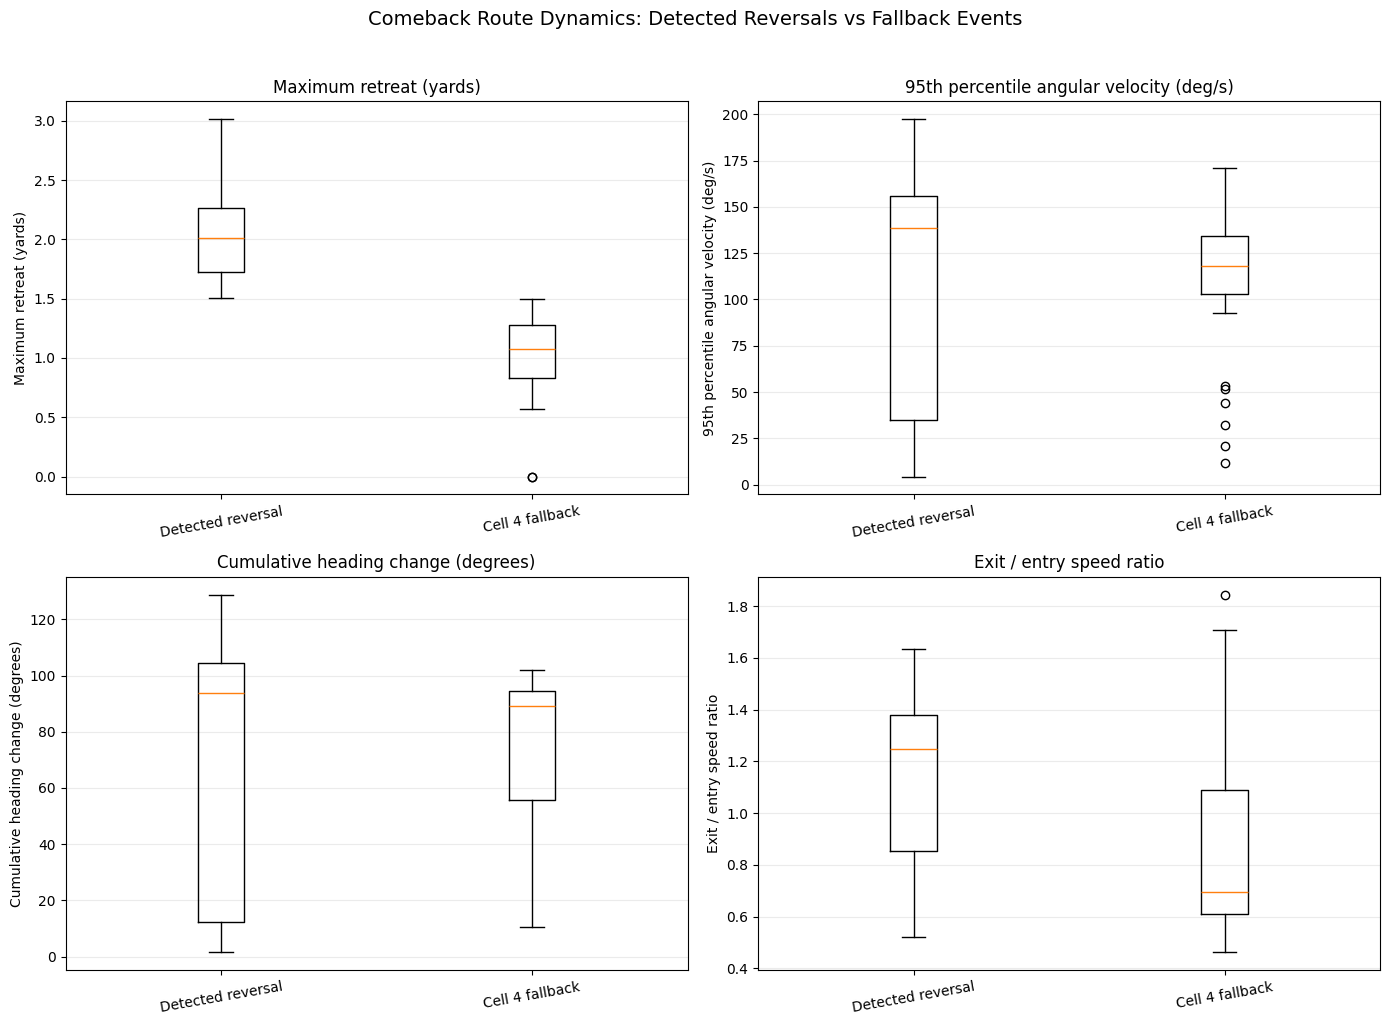


SPEARMAN CORRELATIONS — DETECTED REVERSALS ONLY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,maximum_retreat_yards,peak_angular_velocity_p95_deg_s,cumulative_heading_change_deg,local_min_speed_yds_s,exit_minus_entry_speed_yds_s,exit_entry_speed_ratio
maximum_retreat_yards,1.0000,-0.0470,-0.0310,-0.3550,-0.2650,-0.2110
peak_angular_velocity_p95_deg_s,-0.0470,1.0000,0.9050,0.5310,0.5910,0.6200
cumulative_heading_change_deg,-0.0310,0.9050,1.0000,0.6360,0.6520,0.6490
local_min_speed_yds_s,-0.3550,0.5310,0.6360,1.0000,0.7580,0.6450
exit_minus_entry_speed_yds_s,-0.2650,0.5910,0.6520,0.7580,1.0000,0.9670
exit_entry_speed_ratio,-0.2110,0.6200,0.6490,0.6450,0.9670,1.0000



DATA QUALITY
Missing values in key dynamics features:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,missing_count
maximum_retreat_yards,0
peak_angular_velocity_p95_deg_s,0
cumulative_heading_change_deg,0
local_min_speed_yds_s,0
entry_speed_yds_s,0
exit_speed_yds_s,0
exit_minus_entry_speed_yds_s,0
exit_entry_speed_ratio,0



Event-source counts:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


event_time_source
detected_reversal     76
cell4_cut_fallback    32
Name: count, dtype: int64


Unique player-event keys: 108


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [57]:

# ============================================================
# CELL 21 — DETECTED REVERSAL VS FALLBACK COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = wr_final_reversal_dynamics.copy()

# ------------------------------------------------------------
# 1. Define the two event groups
# ------------------------------------------------------------

detected = df[df["event_time_source"] == "detected_reversal"].copy()
fallback = df[df["event_time_source"] == "cell4_cut_fallback"].copy()

print("GROUP COUNTS")
print("Detected reversals:", len(detected))
print("Cell 4 fallback events:", len(fallback))

# ------------------------------------------------------------
# 2. Descriptive statistics by event source
# ------------------------------------------------------------

features = [
    "maximum_retreat_yards",
    "peak_angular_velocity_p95_deg_s",
    "cumulative_heading_change_deg",
    "local_min_speed_yds_s",
    "entry_speed_yds_s",
    "exit_speed_yds_s",
    "exit_minus_entry_speed_yds_s",
    "exit_entry_speed_ratio"
]

group_summary = (
    df.groupby("event_time_source")[features]
      .agg(["count", "median", "mean", "std"])
      .round(3)
)

print("\nFEATURE SUMMARY BY EVENT SOURCE")
display(group_summary)

# ------------------------------------------------------------
# 3. Compare distributions visually
# ------------------------------------------------------------

plot_features = [
    ("maximum_retreat_yards", "Maximum retreat (yards)"),
    ("peak_angular_velocity_p95_deg_s", "95th percentile angular velocity (deg/s)"),
    ("cumulative_heading_change_deg", "Cumulative heading change (degrees)"),
    ("exit_entry_speed_ratio", "Exit / entry speed ratio")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (feature, label) in zip(axes, plot_features):

    values = [
        detected[feature].dropna(),
        fallback[feature].dropna()
    ]

    ax.boxplot(
        values,
        labels=["Detected reversal", "Cell 4 fallback"],
        showfliers=True
    )

    ax.set_title(label)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=10)

plt.suptitle(
    "Comeback Route Dynamics: Detected Reversals vs Fallback Events",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Correlations among detected reversals only
# ------------------------------------------------------------

detected_features = [
    "maximum_retreat_yards",
    "peak_angular_velocity_p95_deg_s",
    "cumulative_heading_change_deg",
    "local_min_speed_yds_s",
    "exit_minus_entry_speed_yds_s",
    "exit_entry_speed_ratio"
]

detected_corr = detected[detected_features].corr(method="spearman")

print("\nSPEARMAN CORRELATIONS — DETECTED REVERSALS ONLY")
display(detected_corr.round(3))

# ------------------------------------------------------------
# 5. Data-quality checks
# ------------------------------------------------------------

print("\nDATA QUALITY")
print("Missing values in key dynamics features:")
display(df[features].isna().sum().to_frame("missing_count"))

print("\nEvent-source counts:")
display(df["event_time_source"].value_counts())

print(
    "\nUnique player-event keys:",
    df[["nfl_id", "event_id"]].drop_duplicates().shape[0]
)


PAIRED ANCHOR COMPARISON
Shape: (76, 26)
Unique player-event keys: 76

ANCHOR TIME SHIFT


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


count   76.0000
mean    -0.2000
std      1.1150
min     -2.9000
25%     -1.5000
50%      0.5000
75%      0.5000
max      2.3000
Name: anchor_shift_seconds, dtype: float64


PAIRED FEATURE COMPARISON


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,feature,paired_n,reversal_median,cell4_median,median_paired_difference,spearman_anchor_correlation
0,peak_angular_velocity_p95,76,138.5120,140.3530,0.0000,0.8660
1,cumulative_heading_change,76,93.6100,96.7470,-1.1000,0.6460
2,local_min_speed,76,2.6280,2.9590,0.0000,0.4920
3,entry_speed,76,2.9630,5.5650,-2.1760,0.3230
4,exit_speed,76,3.7100,3.5330,0.5820,-0.2810
5,speed_change,76,0.7450,-2.1200,2.9160,-0.4540
6,speed_ratio,76,1.2500,0.6270,0.5830,-0.5070


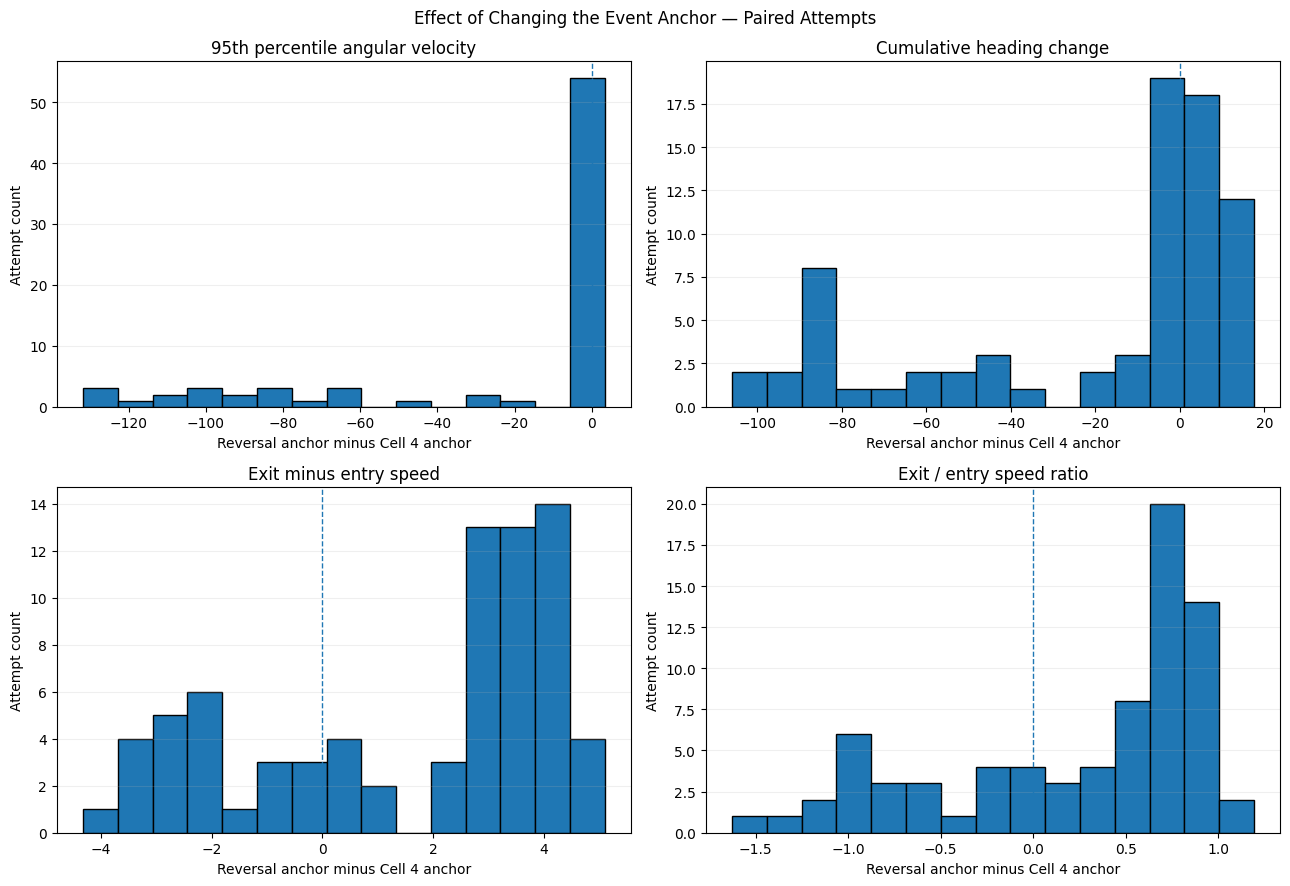


FINAL AUDIT
Detected reversal attempts available: 76
Attempts with both anchor measurements: 76
Attempts missing paired measurements: 0


In [58]:

# ============================================================
# CELL 22 — PAIRED EVENT-ANCHOR COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL_WINDOW = 0.6
MIN_SPEED = 2.5
HALF_WINDOW = 0.5

def calculate_anchor_features(path, event_time):
    """Calculate identical local features around a supplied event time."""

    t = path["time_s"].to_numpy(dtype=float)
    x = path["x_smooth"].to_numpy(dtype=float)
    y = path["y_smooth"].to_numpy(dtype=float)

    dt = np.diff(t)
    dx = np.diff(x)
    dy = np.diff(y)

    valid_dt = np.isfinite(dt) & (dt > 0)
    if valid_dt.sum() < 3:
        return None

    vx = np.divide(dx, dt, out=np.full_like(dx, np.nan),
                   where=valid_dt)
    vy = np.divide(dy, dt, out=np.full_like(dy, np.nan),
                   where=valid_dt)

    speed = np.sqrt(vx**2 + vy**2)
    interval_time = (t[:-1] + t[1:]) / 2

    heading = np.unwrap(np.arctan2(vy, vx))
    heading_change = np.degrees(np.diff(heading))
    heading_dt = np.diff(interval_time)

    angular_velocity = np.divide(
        heading_change,
        heading_dt,
        out=np.full_like(heading_change, np.nan),
        where=np.isfinite(heading_dt) & (heading_dt > 0)
    )

    angular_speed = (speed[:-1] + speed[1:]) / 2
    angular_time = (interval_time[:-1] + interval_time[1:]) / 2

    valid_angular = (
        np.isfinite(angular_velocity)
        & np.isfinite(angular_speed)
        & (angular_speed >= MIN_SPEED)
    )

    local_angular_mask = (
        (angular_time >= event_time - LOCAL_WINDOW)
        & (angular_time <= event_time + LOCAL_WINDOW)
        & valid_angular
    )

    local_angular = np.abs(angular_velocity[local_angular_mask])
    local_heading = np.abs(heading_change[local_angular_mask])

    peak_angular = (
        float(np.percentile(local_angular, 95))
        if len(local_angular) else np.nan
    )

    cumulative_heading = (
        float(local_heading.sum())
        if len(local_heading) else np.nan
    )

    local_speed_mask = (
        (interval_time >= event_time - LOCAL_WINDOW)
        & (interval_time <= event_time + LOCAL_WINDOW)
        & np.isfinite(speed)
    )

    local_speeds = speed[local_speed_mask]

    entry_mask = (
        (interval_time >= event_time - HALF_WINDOW)
        & (interval_time < event_time)
        & np.isfinite(speed)
    )

    exit_mask = (
        (interval_time > event_time)
        & (interval_time <= event_time + HALF_WINDOW)
        & np.isfinite(speed)
    )

    entry = float(np.median(speed[entry_mask])) if entry_mask.any() else np.nan
    exit_ = float(np.median(speed[exit_mask])) if exit_mask.any() else np.nan

    return {
        "peak_angular_velocity_p95": peak_angular,
        "cumulative_heading_change": cumulative_heading,
        "local_min_speed": float(np.min(local_speeds)) if len(local_speeds) else np.nan,
        "entry_speed": entry,
        "exit_speed": exit_,
        "speed_change": exit_ - entry if np.isfinite(entry) and np.isfinite(exit_) else np.nan,
        "speed_ratio": exit_ / entry if np.isfinite(entry) and np.isfinite(exit_) and entry > 0 else np.nan
    }


# ------------------------------------------------------------
# Build paired measurements for detected reversals only
# ------------------------------------------------------------

paired_rows = []

for _, attempt in final_comeback_attempts_fixed.iterrows():

    key = (attempt["nfl_id_key"], attempt["event_id_key"])

    if key not in reversal_lookup.index:
        continue

    reversal = reversal_lookup.loc[key]

    if not bool(reversal["reversal_detected"]):
        continue

    if pd.isna(reversal["reversal_time_s"]):
        continue

    path = prepare_player_path(attempt, tracking_source)

    if path is None:
        continue

    reversal_time = float(reversal["reversal_time_s"])
    cell4_time = float(attempt["cut_time_s"])

    reversal_features = calculate_anchor_features(path, reversal_time)
    cell4_features = calculate_anchor_features(path, cell4_time)

    if reversal_features is None or cell4_features is None:
        continue

    row = {
        "nfl_id": attempt["nfl_id"],
        "event_id": attempt["event_id"],
        "reversal_time_s": reversal_time,
        "cell4_time_s": cell4_time,
        "anchor_shift_seconds": reversal_time - cell4_time
    }

    for feature in reversal_features:
        row[f"reversal_{feature}"] = reversal_features[feature]
        row[f"cell4_{feature}"] = cell4_features[feature]

        row[f"change_{feature}"] = (
            reversal_features[feature] - cell4_features[feature]
        )

    paired_rows.append(row)

anchor_comparison = pd.DataFrame(paired_rows)

print("PAIRED ANCHOR COMPARISON")
print("Shape:", anchor_comparison.shape)
print(
    "Unique player-event keys:",
    anchor_comparison[["nfl_id", "event_id"]].drop_duplicates().shape[0]
)

print("\nANCHOR TIME SHIFT")
display(anchor_comparison["anchor_shift_seconds"].describe().round(3))

# ------------------------------------------------------------
# Compare feature values at both anchors
# ------------------------------------------------------------

paired_features = [
    "peak_angular_velocity_p95",
    "cumulative_heading_change",
    "local_min_speed",
    "entry_speed",
    "exit_speed",
    "speed_change",
    "speed_ratio"
]

comparison_summary = []

for feature in paired_features:

    rev = anchor_comparison[f"reversal_{feature}"]
    old = anchor_comparison[f"cell4_{feature}"]

    valid = rev.notna() & old.notna()

    comparison_summary.append({
        "feature": feature,
        "paired_n": int(valid.sum()),
        "reversal_median": rev[valid].median(),
        "cell4_median": old[valid].median(),
        "median_paired_difference": (rev[valid] - old[valid]).median(),
        "spearman_anchor_correlation": rev[valid].corr(old[valid], method="spearman")
    })

anchor_summary = pd.DataFrame(comparison_summary)

print("\nPAIRED FEATURE COMPARISON")
display(anchor_summary.round(3))

# ------------------------------------------------------------
# Plot paired differences
# ------------------------------------------------------------

plot_features = [
    ("peak_angular_velocity_p95", "95th percentile angular velocity"),
    ("cumulative_heading_change", "Cumulative heading change"),
    ("speed_change", "Exit minus entry speed"),
    ("speed_ratio", "Exit / entry speed ratio")
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, (feature, label) in zip(axes, plot_features):

    values = anchor_comparison[f"change_{feature}"].dropna()

    ax.hist(values, bins=15, edgecolor="black")
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_xlabel("Reversal anchor minus Cell 4 anchor")
    ax.set_ylabel("Attempt count")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle("Effect of Changing the Event Anchor — Paired Attempts")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Final audit
# ------------------------------------------------------------

print("\nFINAL AUDIT")
print("Detected reversal attempts available:", len(detected))
print("Attempts with both anchor measurements:", len(anchor_comparison))
print("Attempts missing paired measurements:", len(detected) - len(anchor_comparison))


In [59]:

# ============================================================
# CELL 23 — FINAL COMEBACK PLAYER-LEVEL FEATURES
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Select attempt-level features
# ------------------------------------------------------------

comeback_features = [
    "maximum_retreat_yards",
    "peak_angular_velocity_p95_deg_s",
    "cumulative_heading_change_deg",
    "local_min_speed_yds_s",
    "entry_speed_yds_s",
    "exit_speed_yds_s",
    "exit_minus_entry_speed_yds_s",
    "exit_entry_speed_ratio"
]

comeback_attempts = wr_final_reversal_dynamics.copy()

# Keep source and detection labels for auditability.
comeback_attempts["detected_reversal"] = (
    comeback_attempts["reversal_detected"].astype(bool)
)

# ------------------------------------------------------------
# 2. Aggregate all attempts by player
# ------------------------------------------------------------

comeback_player_all = (
    comeback_attempts
    .groupby("nfl_id")
    .agg(
        comeback_attempt_count=("event_id", "nunique"),
        detected_reversal_count=("detected_reversal", "sum"),
        retreat_mean=("maximum_retreat_yards", "mean"),
        retreat_median=("maximum_retreat_yards", "median"),
        peak_angular_velocity_mean=(
            "peak_angular_velocity_p95_deg_s", "mean"
        ),
        peak_angular_velocity_median=(
            "peak_angular_velocity_p95_deg_s", "median"
        ),
        cumulative_heading_mean=(
            "cumulative_heading_change_deg", "mean"
        ),
        local_min_speed_mean=("local_min_speed_yds_s", "mean"),
        speed_ratio_mean=("exit_entry_speed_ratio", "mean")
    )
    .reset_index()
)

comeback_player_all["reversal_detection_rate"] = (
    comeback_player_all["detected_reversal_count"]
    / comeback_player_all["comeback_attempt_count"]
)

# ------------------------------------------------------------
# 3. Aggregate detected reversals only
# ------------------------------------------------------------

detected_attempts = comeback_attempts[
    comeback_attempts["detected_reversal"]
].copy()

comeback_player_detected = (
    detected_attempts
    .groupby("nfl_id")
    .agg(
        detected_comeback_attempts=("event_id", "nunique"),
        detected_retreat_mean=("maximum_retreat_yards", "mean"),
        detected_retreat_median=("maximum_retreat_yards", "median"),
        detected_peak_angular_velocity_mean=(
            "peak_angular_velocity_p95_deg_s", "mean"
        ),
        detected_peak_angular_velocity_median=(
            "peak_angular_velocity_p95_deg_s", "median"
        ),
        detected_cumulative_heading_mean=(
            "cumulative_heading_change_deg", "mean"
        ),
        detected_local_min_speed_mean=(
            "local_min_speed_yds_s", "mean"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Join to the existing player-level analysis
# ------------------------------------------------------------

# Preserve the original player analysis.
if "analysis_df" not in globals():
    raise NameError("analysis_df is missing. Run Cell 6 first.")

comeback_player_features = (
    analysis_df
    .merge(
        comeback_player_all,
        on="nfl_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        comeback_player_detected,
        on="nfl_id",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------------------
# 5. Join the separation analysis
# ------------------------------------------------------------

if "primary_analysis_df" not in globals():
    raise NameError("primary_analysis_df is missing. Run Cell 6 first.")

# Preserve the existing primary-analysis eligibility definition.
comeback_primary_analysis = (
    primary_analysis_df
    .merge(
        comeback_player_features[
            [
                "nfl_id",
                "comeback_attempt_count",
                "detected_reversal_count",
                "reversal_detection_rate",
                "retreat_mean",
                "peak_angular_velocity_mean",
                "cumulative_heading_mean",
                "detected_comeback_attempts",
                "detected_retreat_mean",
                "detected_peak_angular_velocity_mean",
                "detected_cumulative_heading_mean"
            ]
        ],
        on="nfl_id",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------------------
# 6. Audit
# ------------------------------------------------------------

print("ALL COMEBACK PLAYER FEATURES")
print("Shape:", comeback_player_features.shape)
print("Unique players:", comeback_player_features["nfl_id"].nunique())

print("\nDETECTED-REVERSAL PLAYER FEATURES")
print("Shape:", comeback_player_detected.shape)
print("Players with at least one detected reversal:",
      comeback_player_detected["nfl_id"].nunique())

print("\nMERGED PRIMARY ANALYSIS")
print("Shape:", comeback_primary_analysis.shape)
print("Unique players:", comeback_primary_analysis["nfl_id"].nunique())

print("\nATTEMPT COUNTS")
print("All attempts:", len(comeback_attempts))
print("Detected:", len(detected_attempts))
print("Fallback:", len(comeback_attempts) - len(detected_attempts))

print("\nMISSINGNESS IN DETECTED FEATURES")
display(
    comeback_primary_analysis[
        [
            "detected_comeback_attempts",
            "detected_retreat_mean",
            "detected_peak_angular_velocity_mean",
            "detected_cumulative_heading_mean"
        ]
    ].isna().sum().to_frame("missing_count")
)

print("\nPLAYER-LEVEL SAMPLE")
display(
    comeback_primary_analysis[
        [
            "nfl_id",
            "comeback_attempt_count",
            "detected_comeback_attempts",
            "reversal_detection_rate",
            "detected_retreat_mean",
            "detected_peak_angular_velocity_mean",
            "detected_cumulative_heading_mean"
        ]
    ].head(10)
)


ALL COMEBACK PLAYER FEATURES
Shape: (106, 77)
Unique players: 106

DETECTED-REVERSAL PLAYER FEATURES
Shape: (69, 8)
Players with at least one detected reversal: 69

MERGED PRIMARY ANALYSIS
Shape: (77, 70)
Unique players: 77

ATTEMPT COUNTS
All attempts: 108
Detected: 76
Fallback: 32

MISSINGNESS IN DETECTED FEATURES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,missing_count
detected_comeback_attempts,30
detected_retreat_mean,30
detected_peak_angular_velocity_mean,30
detected_cumulative_heading_mean,30



PLAYER-LEVEL SAMPLE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,comeback_attempt_count,detected_comeback_attempts,reversal_detection_rate,detected_retreat_mean,detected_peak_angular_velocity_mean,detected_cumulative_heading_mean
0,55884,NaN,NaN,NaN,NaN,NaN,NaN
1,55885,1.0000,NaN,0.0000,NaN,NaN,NaN
2,55887,NaN,NaN,NaN,NaN,NaN,NaN
3,55904,1.0000,NaN,0.0000,NaN,NaN,NaN
4,55915,1.0000,1.0000,1.0000,1.8472,139.6192,98.2628
5,55920,1.0000,NaN,0.0000,NaN,NaN,NaN
6,55928,1.0000,1.0000,1.0000,2.0475,180.8377,110.9858
7,55934,1.0000,1.0000,1.0000,1.9906,162.7193,107.7107
8,55938,NaN,NaN,NaN,NaN,NaN,NaN
9,55939,1.0000,NaN,0.0000,NaN,NaN,NaN


In [60]:

# ============================================================
# CELL 24 — COMEBACK REVERSAL FEATURES VS. ADJUSTED SEPARATION
# ============================================================

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd

# Work from the existing primary analysis cohort.
comeback_assoc_df = primary_analysis_df.copy()

# Confirm the outcome column before running the tests.
outcome_col = "adjusted_separation_mean"

if outcome_col not in comeback_assoc_df.columns:
    separation_candidates = [
        c for c in comeback_assoc_df.columns
        if "separation" in c.lower()
    ]

    print("Expected outcome column not found:", outcome_col)
    print("Available separation-related columns:", separation_candidates)

    raise KeyError(
        f"Please identify the correct adjusted-separation column. "
        f"Available candidates: {separation_candidates}"
    )

# Preselected features, grouped by what they represent.
feature_groups = {
    "Detected-reversal dynamics": [
        "detected_retreat_mean",
        "detected_peak_angular_velocity_mean",
        "detected_cumulative_heading_mean",
    ],
    "All-attempt reversal frequency": [
        "reversal_detection_rate",
        "detected_comeback_attempts",
    ],
}

# Keep only features actually present in the merged table.
available_features = {
    group: [f for f in features if f in comeback_assoc_df.columns]
    for group, features in feature_groups.items()
}

print("OUTCOME:", outcome_col)
print("PRIMARY COHORT:", len(comeback_assoc_df), "players")

print("\nFEATURE AVAILABILITY")
for group, features in available_features.items():
    print(f"\n{group}")
    for feature in features:
        valid_n = comeback_assoc_df[feature].notna().sum()
        print(f"  {feature}: {valid_n} non-missing players")

# Run Spearman correlations.
correlation_results = []

for group, features in available_features.items():
    for feature in features:
        pair = comeback_assoc_df[[outcome_col, feature]].dropna()

        if len(pair) < 5 or pair[feature].nunique() < 2:
            rho, p_value = np.nan, np.nan
        else:
            rho, p_value = spearmanr(
                pair[outcome_col],
                pair[feature]
            )

        correlation_results.append({
            "feature_group": group,
            "feature": feature,
            "n_players": len(pair),
            "spearman_rho": rho,
            "p_value": p_value,
        })

comeback_corr_results = pd.DataFrame(correlation_results)

# Apply FDR correction across all tests in this cell.
valid_p = comeback_corr_results["p_value"].notna()

comeback_corr_results["fdr_q_value"] = np.nan
comeback_corr_results["fdr_significant_05"] = False

if valid_p.sum() > 0:
    reject, q_values, _, _ = multipletests(
        comeback_corr_results.loc[valid_p, "p_value"],
        method="fdr_bh"
    )

    comeback_corr_results.loc[valid_p, "fdr_q_value"] = q_values
    comeback_corr_results.loc[valid_p, "fdr_significant_05"] = reject

comeback_corr_results = comeback_corr_results.sort_values(
    "p_value",
    na_position="last"
).reset_index(drop=True)

print("\nCOMEBACK FEATURE ASSOCIATIONS")
display(
    comeback_corr_results.round(4)
)

# Compare detected-reversal players with players who had attempts
# but no qualifying detected reversal.
comparison = comeback_assoc_df.copy()

comparison["reversal_group"] = np.select(
    [
        comparison["comeback_attempt_count"].isna(),
        comparison["comeback_attempt_count"].notna()
        & comparison["detected_comeback_attempts"].isna(),
        comparison["detected_comeback_attempts"].notna()
        & (comparison["detected_comeback_attempts"] > 0),
    ],
    [
        "No tracked Comeback attempt",
        "Attempt(s), no detected reversal",
        "At least one detected reversal",
    ],
    default="Other"
)

print("\nPLAYER COUNTS BY OBSERVED REVERSAL GROUP")
display(
    comparison.groupby("reversal_group", observed=True)
    .agg(
        players=("nfl_id", "nunique"),
        mean_adjusted_separation=(outcome_col, "mean"),
        median_adjusted_separation=(outcome_col, "median"),
    )
    .round(3)
)


Expected outcome column not found: adjusted_separation_mean
Available separation-related columns: ['n_separation_plays', 'eligible_separation_sample', 'has_separation_data', 'eligible_separation']


KeyError: "Please identify the correct adjusted-separation column. Available candidates: ['n_separation_plays', 'eligible_separation_sample', 'has_separation_data', 'eligible_separation']"

In [61]:

# ============================================================
# CELL 24A — LOCATE THE PLAYER-LEVEL SEPARATION OUTCOME
# ============================================================

print("SEPARATION-RELATED COLUMNS BY DATAFRAME")

for df_name in [
    "sep_plays",
    "wr_cohort",
    "analysis_df",
    "primary_analysis_df",
]:
    if df_name in globals():
        df = globals()[df_name]
        cols = [
            c for c in df.columns
            if "separation" in c.lower()
            or "adjusted" in c.lower()
        ]

        print(f"\n{df_name}: shape={df.shape}")
        print(cols)

# Check the original Cell 5 play-level outcome.
if "sep_plays" in globals():
    print("\nSEP_PLAYS SAMPLE")
    display(sep_plays.head(3))

# Check the player-level separation summary, if available.
if "wr_cohort" in globals():
    print("\nWR_COHORT SEPARATION SAMPLE")
    display(
        wr_cohort[
            [
                c for c in wr_cohort.columns
                if "separation" in c.lower()
                or "adjusted" in c.lower()
            ]
        ].head(5)
    )


SEPARATION-RELATED COLUMNS BY DATAFRAME

sep_plays: shape=(29581, 13)
['separation_at_pass_forward', 'predicted_context_separation', 'adjusted_separation']

wr_cohort: shape=(106, 30)
[]

analysis_df: shape=(106, 60)
['n_separation_plays', 'adjusted_sep_mean', 'target_adjusted_sep_mean', 'eligible_separation_sample', 'has_separation_data', 'eligible_separation']

primary_analysis_df: shape=(77, 60)
['n_separation_plays', 'adjusted_sep_mean', 'target_adjusted_sep_mean', 'eligible_separation_sample', 'has_separation_data', 'eligible_separation']

SEP_PLAYS SAMPLE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,separation_at_pass_forward,lined_up_position,route_ran,team_coverage_man_zone,cushion,in_motion_at_ball_snap,target,cushion_missing,cushion_model,target_flag,predicted_context_separation,adjusted_separation
0,57606,1.8527,SLOT_WR,POST,ZONE_COVERAGE,12.2300,False,False,0,12.2300,0,4.0986,0.8344
1,57152,1.6448,SLOT_WR,IN,ZONE_COVERAGE,11.8500,False,True,0,11.8500,1,4.0843,0.6407
2,55965,3.3115,WR,POST,ZONE_COVERAGE,8.0000,False,False,0,8.0000,0,3.3610,3.0308



WR_COHORT SEPARATION SAMPLE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


""
0
1
2
3
4


In [62]:

# ============================================================
# CELL 24 — COMEBACK REVERSAL FEATURES VS. ADJUSTED SEPARATION
# ============================================================

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd

comeback_assoc_df = primary_analysis_df.copy()

# Correct player-level outcome from Cell 6.
outcome_col = "adjusted_sep_mean"

if outcome_col not in comeback_assoc_df.columns:
    raise KeyError(f"{outcome_col} is missing from primary_analysis_df")

feature_groups = {
    "Detected-reversal dynamics": [
        "detected_retreat_mean",
        "detected_peak_angular_velocity_mean",
        "detected_cumulative_heading_mean",
    ],
    "All-attempt reversal frequency": [
        "reversal_detection_rate",
        "detected_comeback_attempts",
    ],
}

available_features = {
    group: [f for f in features if f in comeback_assoc_df.columns]
    for group, features in feature_groups.items()
}

print("OUTCOME:", outcome_col)
print("PRIMARY COHORT:", len(comeback_assoc_df), "players")
print(
    "Players with measured adjusted separation:",
    comeback_assoc_df[outcome_col].notna().sum()
)

print("\nFEATURE AVAILABILITY")
for group, features in available_features.items():
    print(f"\n{group}")
    for feature in features:
        print(
            f"  {feature}: "
            f"{comeback_assoc_df[feature].notna().sum()} non-missing players"
        )

# ------------------------------------------------------------
# SPEARMAN CORRELATIONS
# ------------------------------------------------------------

correlation_results = []

for group, features in available_features.items():
    for feature in features:
        pair = comeback_assoc_df[[outcome_col, feature]].dropna()

        if len(pair) < 5 or pair[feature].nunique() < 2:
            rho, p_value = np.nan, np.nan
        else:
            rho, p_value = spearmanr(
                pair[outcome_col],
                pair[feature]
            )

        correlation_results.append({
            "feature_group": group,
            "feature": feature,
            "n_players": len(pair),
            "spearman_rho": rho,
            "p_value": p_value,
        })

comeback_corr_results = pd.DataFrame(correlation_results)

# FDR correction across the complete set of tests.
valid_p = comeback_corr_results["p_value"].notna()

comeback_corr_results["fdr_q_value"] = np.nan
comeback_corr_results["fdr_significant_05"] = False

if valid_p.sum() > 0:
    reject, q_values, _, _ = multipletests(
        comeback_corr_results.loc[valid_p, "p_value"],
        method="fdr_bh"
    )

    comeback_corr_results.loc[valid_p, "fdr_q_value"] = q_values
    comeback_corr_results.loc[valid_p, "fdr_significant_05"] = reject

comeback_corr_results = comeback_corr_results.sort_values(
    "p_value",
    na_position="last"
).reset_index(drop=True)

print("\nCOMEBACK FEATURE ASSOCIATIONS")
display(comeback_corr_results.round(4))

# ------------------------------------------------------------
# DESCRIPTIVE COMPARISON OF REVERSAL GROUPS
# ------------------------------------------------------------

comparison = comeback_assoc_df.copy()

comparison["reversal_group"] = np.select(
    [
        comparison["comeback_attempt_count"].isna(),

        comparison["comeback_attempt_count"].notna()
        & comparison["detected_comeback_attempts"].isna(),

        comparison["detected_comeback_attempts"].notna()
        & (comparison["detected_comeback_attempts"] > 0),
    ],
    [
        "No tracked Comeback attempt",
        "Attempt(s), no detected reversal",
        "At least one detected reversal",
    ],
    default="Other"
)

print("\nPLAYER COUNTS BY OBSERVED REVERSAL GROUP")

display(
    comparison.groupby("reversal_group", observed=True)
    .agg(
        players=("nfl_id", "nunique"),
        mean_adjusted_separation=(outcome_col, "mean"),
        median_adjusted_separation=(outcome_col, "median"),
    )
    .round(3)
)


OUTCOME: adjusted_sep_mean
PRIMARY COHORT: 77 players
Players with measured adjusted separation: 77

FEATURE AVAILABILITY

Detected-reversal dynamics

All-attempt reversal frequency


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


KeyError: 'p_value'

In [63]:

# ============================================================
# CELL 24B — INSPECT COMEBACK COLUMNS IN THE PRIMARY DATAFRAME
# ============================================================

print("PRIMARY ANALYSIS SHAPE:", primary_analysis_df.shape)

print("\nALL COMEBACK / REVERSAL-RELATED COLUMNS:")
comeback_columns = [
    c for c in primary_analysis_df.columns
    if "comeback" in c.lower() or "reversal" in c.lower()
]

for c in comeback_columns:
    print(c)

print("\nDETECTED / RETREAT / ANGULAR / HEADING COLUMNS:")
for c in primary_analysis_df.columns:
    if any(
        term in c.lower()
        for term in ["detected", "retreat", "angular", "heading"]
    ):
        print(c)

print("\nPLAYER-LEVEL COMEBACK FEATURE TABLE:")
if "comeback_player_all" in globals():
    print("comeback_player_all:", comeback_player_all.shape)
    print(comeback_player_all.columns.tolist())
    display(comeback_player_all.head(3))

if "comeback_player_detected" in globals():
    print("comeback_player_detected:", comeback_player_detected.shape)
    print(comeback_player_detected.columns.tolist())
    display(comeback_player_detected.head(3))


PRIMARY ANALYSIS SHAPE: (77, 60)

ALL COMEBACK / REVERSAL-RELATED COLUMNS:
COMEBACK_ROUTE_RIGHT_n_attempts
COMEBACK_ROUTE_RIGHT_mean_heading_change_deg
COMEBACK_ROUTE_RIGHT_mean_trough_retention
COMEBACK_ROUTE_RIGHT_mean_exit_retention
COMEBACK_ROUTE_RIGHT_mean_braking_decel
COMEBACK_ROUTE_RIGHT_mean_exit_reaccel

DETECTED / RETREAT / ANGULAR / HEADING COLUMNS:
COMEBACK_ROUTE_RIGHT_mean_heading_change_deg
CURL_ROUTE_RIGHT_mean_heading_change_deg
DAGGER_ROUTE_LEFT_mean_heading_change_deg
has_heading_feature

PLAYER-LEVEL COMEBACK FEATURE TABLE:
comeback_player_all: (96, 11)
['nfl_id', 'comeback_attempt_count', 'detected_reversal_count', 'retreat_mean', 'retreat_median', 'peak_angular_velocity_mean', 'peak_angular_velocity_median', 'cumulative_heading_mean', 'local_min_speed_mean', 'speed_ratio_mean', 'reversal_detection_rate']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,comeback_attempt_count,detected_reversal_count,retreat_mean,retreat_median,peak_angular_velocity_mean,peak_angular_velocity_median,cumulative_heading_mean,local_min_speed_mean,speed_ratio_mean,reversal_detection_rate
0,55885,1,0,0.0000,0.0000,118.4096,118.4096,87.3575,3.8006,0.7566,0.0000
1,55904,1,0,0.8249,0.8249,134.7231,134.7231,98.6198,3.4084,0.6364,0.0000
2,55915,1,1,1.8472,1.8472,139.6192,139.6192,98.2628,3.2830,1.4577,1.0000


comeback_player_detected: (69, 8)
['nfl_id', 'detected_comeback_attempts', 'detected_retreat_mean', 'detected_retreat_median', 'detected_peak_angular_velocity_mean', 'detected_peak_angular_velocity_median', 'detected_cumulative_heading_mean', 'detected_local_min_speed_mean']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,detected_comeback_attempts,detected_retreat_mean,detected_retreat_median,detected_peak_angular_velocity_mean,detected_peak_angular_velocity_median,detected_cumulative_heading_mean,detected_local_min_speed_mean
0,55915,1,1.8472,1.8472,139.6192,139.6192,98.2628,3.2830
1,55928,1,2.0475,2.0475,180.8377,180.8377,110.9858,2.5652
2,55934,1,1.9906,1.9906,162.7193,162.7193,107.7107,2.9918


In [64]:

# ============================================================
# CELL 24C — MERGE COMEBACK PLAYER FEATURES INTO ANALYSIS
# ============================================================

# Start from the original player-level analysis table.
analysis_df = analysis_df.drop(
    columns=[
        c for c in analysis_df.columns
        if c in comeback_player_all.columns
        and c != "nfl_id"
    ],
    errors="ignore"
)

# Merge all-attempt features.
analysis_df = analysis_df.merge(
    comeback_player_all,
    on="nfl_id",
    how="left",
    validate="one_to_one"
)

# Merge detected-only features.
analysis_df = analysis_df.merge(
    comeback_player_detected,
    on="nfl_id",
    how="left",
    validate="one_to_one"
)

# Rebuild the primary cohort from the existing eligibility rule.
primary_analysis_df = analysis_df.loc[
    analysis_df["eligible_separation"]
    & analysis_df["has_heading_feature"]
].copy()

print("UPDATED ANALYSIS SHAPE:", analysis_df.shape)
print("UPDATED PRIMARY SHAPE:", primary_analysis_df.shape)

print(
    "Unique primary players:",
    primary_analysis_df["nfl_id"].nunique()
)

comeback_cols = [
    c for c in primary_analysis_df.columns
    if c in comeback_player_all.columns.tolist()
    or c in comeback_player_detected.columns.tolist()
]

print("\nCOMEBACK FEATURE MISSINGNESS")
display(
    primary_analysis_df[comeback_cols]
    .isna()
    .sum()
    .to_frame("missing_count")
)

print("\nPRIMARY COHORT SAMPLE")
display(
    primary_analysis_df[
        ["nfl_id", "adjusted_sep_mean"] + comeback_cols
    ].head(10)
)


UPDATED ANALYSIS SHAPE: (106, 77)
UPDATED PRIMARY SHAPE: (77, 77)
Unique primary players: 77

COMEBACK FEATURE MISSINGNESS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,missing_count
nfl_id,0
comeback_attempt_count,9
detected_reversal_count,9
retreat_mean,9
retreat_median,9
peak_angular_velocity_mean,9
peak_angular_velocity_median,9
cumulative_heading_mean,9
local_min_speed_mean,9
speed_ratio_mean,9



PRIMARY COHORT SAMPLE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,adjusted_sep_mean,nfl_id,comeback_attempt_count,detected_reversal_count,retreat_mean,retreat_median,peak_angular_velocity_mean,peak_angular_velocity_median,cumulative_heading_mean,local_min_speed_mean,speed_ratio_mean,reversal_detection_rate,detected_comeback_attempts,detected_retreat_mean,detected_retreat_median,detected_peak_angular_velocity_mean,detected_peak_angular_velocity_median,detected_cumulative_heading_mean,detected_local_min_speed_mean
0,55884,3.0819,55884,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,55885,3.0316,55885,1.0000,0.0000,0.0000,0.0000,118.4096,118.4096,87.3575,3.8006,0.7566,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55887,3.0075,55887,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,55904,2.8266,55904,1.0000,0.0000,0.8249,0.8249,134.7231,134.7231,98.6198,3.4084,0.6364,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,55915,3.1149,55915,1.0000,1.0000,1.8472,1.8472,139.6192,139.6192,98.2628,3.2830,1.4577,1.0000,1.0000,1.8472,1.8472,139.6192,139.6192,98.2628,3.2830
5,55920,3.1525,55920,1.0000,0.0000,0.7443,0.7443,121.5684,121.5684,95.0309,3.8522,0.7692,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,55928,3.3062,55928,1.0000,1.0000,2.0475,2.0475,180.8377,180.8377,110.9858,2.5652,1.4500,1.0000,1.0000,2.0475,2.0475,180.8377,180.8377,110.9858,2.5652
7,55934,3.2307,55934,1.0000,1.0000,1.9906,1.9906,162.7193,162.7193,107.7107,2.9918,1.3797,1.0000,1.0000,1.9906,1.9906,162.7193,162.7193,107.7107,2.9918
8,55938,3.2703,55938,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,55939,2.9316,55939,1.0000,0.0000,1.5000,1.5000,150.9126,150.9126,95.7106,2.5915,0.4887,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [65]:

# ============================================================
# CELL 24D — COMEBACK FEATURES VS. ADJUSTED SEPARATION
# ============================================================

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd

outcome_col = "adjusted_sep_mean"

feature_groups = {
    "Detected-reversal dynamics": [
        "detected_retreat_mean",
        "detected_peak_angular_velocity_mean",
        "detected_cumulative_heading_mean",
    ],
    "All-attempt reversal frequency": [
        "reversal_detection_rate",
        "detected_reversal_count",
    ],
    "All-attempt route dynamics": [
        "peak_angular_velocity_mean",
        "cumulative_heading_mean",
        "retreat_mean",
    ],
}

results = []

for group, features in feature_groups.items():
    for feature in features:

        if feature not in primary_analysis_df.columns:
            print("Skipping missing feature:", feature)
            continue

        pair = primary_analysis_df[
            [outcome_col, feature]
        ].dropna()

        if len(pair) < 5 or pair[feature].nunique() < 2:
            rho, p_value = np.nan, np.nan
        else:
            rho, p_value = spearmanr(
                pair[outcome_col],
                pair[feature]
            )

        results.append({
            "feature_group": group,
            "feature": feature,
            "n_players": len(pair),
            "spearman_rho": rho,
            "p_value": p_value,
        })

comeback_corr_results = pd.DataFrame(results)

# FDR correction across the tests that could be calculated.
comeback_corr_results["fdr_q_value"] = np.nan
comeback_corr_results["fdr_significant_05"] = False

valid = comeback_corr_results["p_value"].notna()

if valid.any():
    reject, q_values, _, _ = multipletests(
        comeback_corr_results.loc[valid, "p_value"],
        method="fdr_bh"
    )

    comeback_corr_results.loc[valid, "fdr_q_value"] = q_values
    comeback_corr_results.loc[valid, "fdr_significant_05"] = reject

comeback_corr_results = comeback_corr_results.sort_values(
    "p_value",
    na_position="last"
).reset_index(drop=True)

print("COMEBACK FEATURE ASSOCIATIONS")
display(comeback_corr_results.round(4))


COMEBACK FEATURE ASSOCIATIONS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,feature_group,feature,n_players,spearman_rho,p_value,fdr_q_value,fdr_significant_05
0,Detected-reversal dynamics,detected_retreat_mean,47,-0.2561,0.0823,0.3443,False
1,All-attempt route dynamics,retreat_mean,68,-0.2097,0.0861,0.3443,False
2,All-attempt route dynamics,cumulative_heading_mean,68,-0.1243,0.3126,0.7501,False
3,All-attempt reversal frequency,detected_reversal_count,68,-0.0759,0.5385,0.7501,False
4,Detected-reversal dynamics,detected_peak_angular_velocity_mean,47,0.0871,0.5606,0.7501,False
5,All-attempt reversal frequency,reversal_detection_rate,68,-0.0715,0.5626,0.7501,False
6,Detected-reversal dynamics,detected_cumulative_heading_mean,47,-0.0435,0.7717,0.8575,False
7,All-attempt route dynamics,peak_angular_velocity_mean,68,0.0222,0.8575,0.8575,False


In [66]:

# ============================================================
# CELL 25 — SAME-SAMPLE COMPARISON OF COMEBACK FEATURES
# ============================================================

from scipy.stats import spearmanr
import pandas as pd
import numpy as np

outcome = "adjusted_sep_mean"

old_heading = "COMEBACK_ROUTE_RIGHT_mean_heading_change_deg"

new_features = [
    "detected_retreat_mean",
    "detected_peak_angular_velocity_mean",
    "detected_cumulative_heading_mean",
]

comparison_features = [old_heading] + new_features

# Use only players with all four measurements and the outcome.
same_sample = primary_analysis_df[
    [outcome] + comparison_features
].dropna().copy()

print("SAME-SAMPLE PLAYER COUNT:", len(same_sample))

# Correlations with adjusted separation.
results = []

for feature in comparison_features:
    rho, p = spearmanr(
        same_sample[feature],
        same_sample[outcome]
    )

    results.append({
        "feature": feature,
        "n_players": len(same_sample),
        "spearman_rho": rho,
        "p_value": p,
    })

same_sample_results = pd.DataFrame(results)

print("\nCORRELATIONS WITH ADJUSTED SEPARATION")
display(same_sample_results.round(4))

# Correlations among the features themselves.
print("\nCORRELATIONS AMONG COMEBACK FEATURES")
display(
    same_sample[comparison_features]
    .corr(method="spearman")
    .round(3)
)

# Compare the same-sample old-heading result with the
# previously reported full-cohort result.
print("\nSAMPLE CHECK")
print("Primary cohort:", len(primary_analysis_df))
print(
    "Players with old heading feature:",
    primary_analysis_df[old_heading].notna().sum()
)
print(
    "Players with detected retreat feature:",
    primary_analysis_df["detected_retreat_mean"].notna().sum()
)


SAME-SAMPLE PLAYER COUNT: 47

CORRELATIONS WITH ADJUSTED SEPARATION


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,feature,n_players,spearman_rho,p_value
0,COMEBACK_ROUTE_RIGHT_mean_heading_change_deg,47,-0.1826,0.2193
1,detected_retreat_mean,47,-0.2561,0.0823
2,detected_peak_angular_velocity_mean,47,0.0871,0.5606
3,detected_cumulative_heading_mean,47,-0.0435,0.7717



CORRELATIONS AMONG COMEBACK FEATURES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,COMEBACK_ROUTE_RIGHT_mean_heading_change_deg,detected_retreat_mean,detected_peak_angular_velocity_mean,detected_cumulative_heading_mean
COMEBACK_ROUTE_RIGHT_mean_heading_change_deg,1.0000,-0.1480,0.1950,0.3550
detected_retreat_mean,-0.1480,1.0000,0.0240,-0.0020
detected_peak_angular_velocity_mean,0.1950,0.0240,1.0000,0.8340
detected_cumulative_heading_mean,0.3550,-0.0020,0.8340,1.0000



SAMPLE CHECK
Primary cohort: 77
Players with old heading feature: 68
Players with detected retreat feature: 47


In [67]:

# ============================================================
# CELL 26A — IDENTIFY EXISTING MODEL CONTROLS
# ============================================================

print("PRIMARY ANALYSIS COLUMNS RELATED TO USAGE:")
for c in primary_analysis_df.columns:
    if any(term in c.lower() for term in [
        "snap", "play", "target", "usage", "game"
    ]):
        print(c)

print("\nPRIMARY ANALYSIS COLUMNS RELATED TO ATHLETICISM:")
for c in primary_analysis_df.columns:
    if any(term in c.lower() for term in [
        "ngs", "speed", "forty", "athletic", "acceleration"
    ]):
        print(c)

print("\nEXISTING MODEL-RELATED VARIABLES:")
for name in [
    "model_df",
    "regression_df",
    "primary_analysis_df",
]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}: {df.shape}")
        print(df.columns.tolist())


PRIMARY ANALYSIS COLUMNS RELATED TO USAGE:
display_name
reg_snaps
targets
target_rate
n_separation_plays
n_targeted_plays
target_raw_sep_mean
target_adjusted_sep_mean

PRIMARY ANALYSIS COLUMNS RELATED TO ATHLETICISM:
forty
ngs_athleticism_score
ngs_college_production_score
ngs_final_score
local_min_speed_mean
speed_ratio_mean
detected_local_min_speed_mean

EXISTING MODEL-RELATED VARIABLES:

model_df: (77, 60)
['nfl_id', 'display_name', 'draft_year', 'nfl_position', 'birth_date', 'college_name', 'college_conference', 'draft_round', 'draft_pick_within_round', 'draft_overall_pick', 'combine_position', 'combine_height', 'combine_weight', 'hand_size', 'arm_length', 'wing_span', 'ten_yd_split', 'forty', 'vertical', 'broad_jump', 'three_cone', 'short_shuttle', 'bench_reps', 'ngs_athleticism_score', 'ngs_college_production_score', 'ngs_final_score', 'reg_snaps', 'targets', 'sep_measured', 'target_rate', 'n_separation_plays', 'n_targeted_plays', 'raw_sep_mean', 'adjusted_sep_mean', 'target_raw_

In [68]:

# ============================================================
# CELL 26B — DOES RETREAT DISTANCE ADD EXPLANATORY VALUE?
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Define variables
# ------------------------------------------------------------

outcome = "adjusted_sep_mean"

heading_feature = "COMEBACK_ROUTE_RIGHT_mean_heading_change_deg"
retreat_feature = "detected_retreat_mean"

control_features = [
    "reg_snaps",
    "ngs_athleticism_score",
]

required = [
    outcome,
    heading_feature,
    retreat_feature,
    *control_features,
]

missing_columns = [
    c for c in required
    if c not in primary_analysis_df.columns
]

if missing_columns:
    raise KeyError(f"Missing columns: {missing_columns}")

# Use the exact same players in every model.
model_data = primary_analysis_df[required].dropna().copy()

# Log-transform usage to reduce skew.
model_data["log_reg_snaps"] = np.log1p(
    model_data["reg_snaps"].clip(lower=0)
)

# ------------------------------------------------------------
# 2. Standardize continuous predictors
# ------------------------------------------------------------

predictors = [
    "log_reg_snaps",
    "ngs_athleticism_score",
    heading_feature,
    retreat_feature,
]

scaler = StandardScaler()

model_data[predictors] = scaler.fit_transform(
    model_data[predictors]
)

print("COMMON MODEL SAMPLE:", len(model_data), "players")
print("OUTCOME:", outcome)
print("\nDESCRIPTIVE SAMPLE CHECK")
print(
    "Adjusted separation mean:",
    round(model_data[outcome].mean(), 3)
)
print(
    "Adjusted separation SD:",
    round(model_data[outcome].std(), 3)
)

# ------------------------------------------------------------
# 3. Fit nested models using HC3 robust standard errors
# ------------------------------------------------------------

model_specs = {
    "Baseline: controls": [
        "log_reg_snaps",
        "ngs_athleticism_score",
    ],

    "Baseline + heading": [
        "log_reg_snaps",
        "ngs_athleticism_score",
        heading_feature,
    ],

    "Baseline + retreat": [
        "log_reg_snaps",
        "ngs_athleticism_score",
        retreat_feature,
    ],

    "Combined: heading + retreat": [
        "log_reg_snaps",
        "ngs_athleticism_score",
        heading_feature,
        retreat_feature,
    ],
}

fitted_models = {}
model_summary = []

for name, features in model_specs.items():

    X = sm.add_constant(
        model_data[features],
        has_constant="add"
    )

    y = model_data[outcome]

    fit = sm.OLS(y, X).fit(cov_type="HC3")

    fitted_models[name] = fit

    model_summary.append({
        "model": name,
        "n_players": int(fit.nobs),
        "r_squared": fit.rsquared,
        "adjusted_r_squared": fit.rsquared_adj,
        "AIC": fit.aic,
    })

model_comparison = pd.DataFrame(model_summary)

print("\nMODEL COMPARISON")
display(model_comparison.round(4))

# ------------------------------------------------------------
# 4. Compare incremental explanatory value
# ------------------------------------------------------------

baseline_r2 = fitted_models["Baseline: controls"].rsquared
heading_r2 = fitted_models["Baseline + heading"].rsquared
retreat_r2 = fitted_models["Baseline + retreat"].rsquared
combined_r2 = fitted_models["Combined: heading + retreat"].rsquared

incremental_results = pd.DataFrame([
    {
        "comparison": "Heading added to baseline",
        "incremental_r_squared": heading_r2 - baseline_r2,
    },
    {
        "comparison": "Retreat added to baseline",
        "incremental_r_squared": retreat_r2 - baseline_r2,
    },
    {
        "comparison": "Retreat added after heading",
        "incremental_r_squared": combined_r2 - heading_r2,
    },
    {
        "comparison": "Heading added after retreat",
        "incremental_r_squared": combined_r2 - retreat_r2,
    },
])

print("\nINCREMENTAL R-SQUARED")
display(incremental_results.round(4))

# ------------------------------------------------------------
# 5. Inspect combined-model coefficients
# ------------------------------------------------------------

combined_fit = fitted_models["Combined: heading + retreat"]

coefficient_table = pd.DataFrame({
    "coefficient": combined_fit.params,
    "robust_SE": combined_fit.bse,
    "t_value": combined_fit.tvalues,
    "p_value": combined_fit.pvalues,
    "CI_lower": combined_fit.conf_int()[0],
    "CI_upper": combined_fit.conf_int()[1],
})

print("\nCOMBINED MODEL — HC3 ROBUST COEFFICIENTS")
display(coefficient_table.round(4))

# ------------------------------------------------------------
# 6. Check predictor overlap
# ------------------------------------------------------------

print("\nPREDICTOR CORRELATION")
display(
    model_data[predictors].corr().round(3)
)


COMMON MODEL SAMPLE: 47 players
OUTCOME: adjusted_sep_mean

DESCRIPTIVE SAMPLE CHECK
Adjusted separation mean: 3.094
Adjusted separation SD: 0.192

MODEL COMPARISON


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,n_players,r_squared,adjusted_r_squared,AIC
0,Baseline: controls,47,0.0001,-0.0453,-16.7040
1,Baseline + heading,47,0.0853,0.0215,-18.8873
2,Baseline + retreat,47,0.0625,-0.0029,-17.7330
3,Combined: heading + retreat,47,0.1615,0.0817,-20.9770



INCREMENTAL R-SQUARED


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,comparison,incremental_r_squared
0,Heading added to baseline,0.0851
1,Retreat added to baseline,0.0624
2,Retreat added after heading,0.0762
3,Heading added after retreat,0.0990


... (2 outputs left out)

,coefficient,robust_SE,t_value,p_value,CI_lower,CI_upper
const,3.0938,0.0290,106.7073,0.0000,3.0369,3.1506
log_reg_snaps,0.0175,0.0389,0.4500,0.6527,-0.0587,0.0937
ngs_athleticism_score,-0.0127,0.0295,-0.4304,0.6669,-0.0706,0.0451
COMEBACK_ROUTE_RIGHT_mean_heading_change_deg,-0.0628,0.0333,-1.8881,0.0590,-0.1280,0.0024
detected_retreat_mean,-0.0529,0.0322,-1.6422,0.1005,-0.1160,0.0102



PREDICTOR CORRELATION


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,log_reg_snaps,ngs_athleticism_score,COMEBACK_ROUTE_RIGHT_mean_heading_change_deg,detected_retreat_mean
log_reg_snaps,1.0000,0.3090,0.2480,-0.0790
ngs_athleticism_score,0.3090,1.0000,-0.0750,-0.0590
COMEBACK_ROUTE_RIGHT_mean_heading_change_deg,0.2480,-0.0750,1.0000,-0.0960
detected_retreat_mean,-0.0790,-0.0590,-0.0960,1.0000


In [69]:

# ============================================================
# CELL 27 — INCREMENTAL VALUE AND BOOTSTRAP ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import f
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Define nested model matrices
# ------------------------------------------------------------

y = model_data[outcome]

base_features = [
    "log_reg_snaps",
    "ngs_athleticism_score",
]

heading_features = base_features + [
    heading_feature
]

combined_features = heading_features + [
    retreat_feature
]

def fit_ols(features, data):
    X = sm.add_constant(
        data[features],
        has_constant="add"
    )
    return sm.OLS(data[outcome], X).fit()

base_fit = fit_ols(base_features, model_data)
heading_fit = fit_ols(heading_features, model_data)
combined_fit = fit_ols(combined_features, model_data)

# ------------------------------------------------------------
# 2. Partial F-test: does retreat improve the heading model?
# ------------------------------------------------------------

rss_reduced = np.sum(base_fit.resid ** 2) if False else np.sum(
    heading_fit.resid ** 2
)

rss_full = np.sum(combined_fit.resid ** 2)

df_num = int(heading_fit.df_resid - combined_fit.df_resid)
df_den = int(combined_fit.df_resid)

partial_f = (
    ((rss_reduced - rss_full) / df_num)
    / (rss_full / df_den)
)

partial_p = f.sf(partial_f, df_num, df_den)

print("PARTIAL F-TEST: RETREAT ADDED AFTER HEADING")
print("F statistic:", round(partial_f, 4))
print("Numerator df:", df_num)
print("Denominator df:", df_den)
print("p-value:", round(partial_p, 4))

# ------------------------------------------------------------
# 3. Player-level bootstrap for incremental R-squared
# ------------------------------------------------------------

rng = np.random.default_rng(42)

N_BOOT = 3000
bootstrap_delta_r2 = []

n = len(model_data)

for b in range(N_BOOT):

    sampled_indices = rng.integers(0, n, size=n)
    boot = model_data.iloc[sampled_indices].copy()

    try:
        boot_heading = fit_ols(
            heading_features,
            boot
        )

        boot_combined = fit_ols(
            combined_features,
            boot
        )

        delta = (
            boot_combined.rsquared
            - boot_heading.rsquared
        )

        bootstrap_delta_r2.append(delta)

    except Exception:
        continue

bootstrap_delta_r2 = np.asarray(bootstrap_delta_r2)

ci_low, ci_high = np.percentile(
    bootstrap_delta_r2,
    [2.5, 97.5]
)

print("\nBOOTSTRAP INCREMENTAL R-SQUARED")
print("Successful iterations:", len(bootstrap_delta_r2))
print("Observed increment:", round(
    combined_fit.rsquared - heading_fit.rsquared, 4
))
print("Bootstrap median:", round(
    np.median(bootstrap_delta_r2), 4
))
print("95% percentile interval:", (
    round(ci_low, 4),
    round(ci_high, 4)
))
print(
    "Fraction of bootstrap increments above zero:",
    round(np.mean(bootstrap_delta_r2 > 0), 4)
)

# ------------------------------------------------------------
# 4. HC3 coefficient test for retreat in combined model
# ------------------------------------------------------------

X_combined = sm.add_constant(
    model_data[combined_features],
    has_constant="add"
)

combined_hc3 = sm.OLS(
    y,
    X_combined
).fit(cov_type="HC3")

print("\nRETREAT COEFFICIENT — HC3")
print("Coefficient:", round(
    combined_hc3.params[retreat_feature], 4
))
print("Robust p-value:", round(
    combined_hc3.pvalues[retreat_feature], 4
))
print(
    "95% CI:",
    tuple(
        round(v, 4)
        for v in combined_hc3.conf_int().loc[retreat_feature]
    )
)


PARTIAL F-TEST: RETREAT ADDED AFTER HEADING
F statistic: 3.8184
Numerator df: 1
Denominator df: 42
p-value: 0.0574


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


BOOTSTRAP INCREMENTAL R-SQUARED
Successful iterations: 3000
Observed increment: 0.0762
Bootstrap median: 0.0686
95% percentile interval: (np.float64(0.0004), np.float64(0.2851))
Fraction of bootstrap increments above zero: 1.0

RETREAT COEFFICIENT — HC3
Coefficient: -0.0529
Robust p-value: 0.1005
95% CI: (-0.116, 0.0102)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [70]:

# ============================================================
# CELL 28 — LEAVE-ONE-PLAYER-OUT VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error

loo_results = []

for i in range(len(model_data)):

    train = model_data.drop(model_data.index[i])
    test = model_data.iloc[[i]]

    # Heading-only model
    X_train_heading = sm.add_constant(
        train[heading_features],
        has_constant="add"
    )
    X_test_heading = sm.add_constant(
        test[heading_features],
        has_constant="add"
    )

    fit_heading = sm.OLS(
        train[outcome],
        X_train_heading
    ).fit()

    pred_heading = float(
        fit_heading.predict(X_test_heading).iloc[0]
    )

    # Combined model
    X_train_combined = sm.add_constant(
        train[combined_features],
        has_constant="add"
    )
    X_test_combined = sm.add_constant(
        test[combined_features],
        has_constant="add"
    )

    fit_combined = sm.OLS(
        train[outcome],
        X_train_combined
    ).fit()

    pred_combined = float(
        fit_combined.predict(X_test_combined).iloc[0]
    )

    actual = float(test[outcome].iloc[0])

    loo_results.append({
        "nfl_id": test["nfl_id"].iloc[0]
        if "nfl_id" in test.columns else test.index[0],
        "actual": actual,
        "heading_prediction": pred_heading,
        "combined_prediction": pred_combined,
        "heading_squared_error": (actual - pred_heading) ** 2,
        "combined_squared_error": (actual - pred_combined) ** 2,
        "heading_absolute_error": abs(actual - pred_heading),
        "combined_absolute_error": abs(actual - pred_combined),
    })

loo_df = pd.DataFrame(loo_results)

# ------------------------------------------------------------
# Aggregate out-of-sample performance
# ------------------------------------------------------------

heading_rmse = np.sqrt(
    loo_df["heading_squared_error"].mean()
)

combined_rmse = np.sqrt(
    loo_df["combined_squared_error"].mean()
)

heading_mae = loo_df["heading_absolute_error"].mean()
combined_mae = loo_df["combined_absolute_error"].mean()

loo_summary = pd.DataFrame([
    {
        "model": "Heading only",
        "LOO_RMSE": heading_rmse,
        "LOO_MAE": heading_mae,
    },
    {
        "model": "Heading + retreat",
        "LOO_RMSE": combined_rmse,
        "LOO_MAE": combined_mae,
    },
])

print("LEAVE-ONE-PLAYER-OUT PERFORMANCE")
display(loo_summary.round(4))

print("\nERROR DIFFERENCE")
print(
    "RMSE change (%):",
    round(100 * (combined_rmse / heading_rmse - 1), 2)
)
print(
    "MAE change (%):",
    round(100 * (combined_mae / heading_mae - 1), 2)
)

print("\nPLAYER-LEVEL PREDICTION COMPARISON")
display(loo_df.head(10).round(4))


LEAVE-ONE-PLAYER-OUT PERFORMANCE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,LOO_RMSE,LOO_MAE
0,Heading only,0.2024,0.1714
1,Heading + retreat,0.1988,0.1676



ERROR DIFFERENCE
RMSE change (%): -1.81
MAE change (%): -2.22

PLAYER-LEVEL PREDICTION COMPARISON


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,actual,heading_prediction,combined_prediction,heading_squared_error,combined_squared_error,heading_absolute_error,combined_absolute_error
0,4,3.1149,3.0899,3.1197,0.0006,0.0000,0.0250,0.0048
1,6,3.3062,3.1313,3.1373,0.0306,0.0285,0.1749,0.1689
2,7,3.2307,3.0928,3.1060,0.0190,0.0156,0.1379,0.1247
3,11,3.2175,3.0837,3.0974,0.0179,0.0144,0.1338,0.1200
4,13,3.2396,3.1259,3.1768,0.0129,0.0039,0.1136,0.0628
5,15,2.7635,3.1334,3.0647,0.1368,0.0907,0.3699,0.3011
6,16,3.0221,3.1249,3.0983,0.0106,0.0058,0.1028,0.0762
7,17,3.1465,3.0570,3.0580,0.0080,0.0078,0.0895,0.0885
8,19,3.0535,3.0863,3.1241,0.0011,0.0050,0.0328,0.0706
9,20,3.0027,3.1167,3.1836,0.0130,0.0328,0.1140,0.1810


In [71]:

# ============================================================
# CELL 29 — PLAYER-LEVEL LOO ERROR DIAGNOSTIC
# ============================================================

loo_df = loo_df.copy()

loo_df["absolute_error_improvement"] = (
    loo_df["heading_absolute_error"]
    - loo_df["combined_absolute_error"]
)

loo_df["squared_error_improvement"] = (
    loo_df["heading_squared_error"]
    - loo_df["combined_squared_error"]
)

improved = (
    loo_df["absolute_error_improvement"] > 0
).sum()

worsened = (
    loo_df["absolute_error_improvement"] < 0
).sum()

unchanged = (
    loo_df["absolute_error_improvement"] == 0
).sum()

print("PLAYER-LEVEL LOO ERROR COMPARISON")
print(f"Players improved: {improved}/{len(loo_df)}")
print(f"Players worsened: {worsened}/{len(loo_df)}")
print(f"Unchanged: {unchanged}/{len(loo_df)}")

print(
    "\nMedian absolute-error improvement:",
    round(loo_df["absolute_error_improvement"].median(), 4)
)

print(
    "Mean absolute-error improvement:",
    round(loo_df["absolute_error_improvement"].mean(), 4)
)

print("\nLARGEST IMPROVEMENTS")
display(
    loo_df.sort_values(
        "absolute_error_improvement",
        ascending=False
    )[
        [
            "nfl_id",
            "actual",
            "heading_absolute_error",
            "combined_absolute_error",
            "absolute_error_improvement",
        ]
    ].head(10).round(4)
)

print("\nLARGEST REGRESSIONS")
display(
    loo_df.sort_values(
        "absolute_error_improvement",
        ascending=True
    )[
        [
            "nfl_id",
            "actual",
            "heading_absolute_error",
            "combined_absolute_error",
            "absolute_error_improvement",
        ]
    ].head(10).round(4)
)


PLAYER-LEVEL LOO ERROR COMPARISON
Players improved: 28/47
Players worsened: 19/47
Unchanged: 0/47

Median absolute-error improvement: 0.0132
Mean absolute-error improvement: 0.0038

LARGEST IMPROVEMENTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,actual,heading_absolute_error,combined_absolute_error,absolute_error_improvement
13,25,2.7511,0.3497,0.2599,0.0897
37,73,2.7992,0.2726,0.1841,0.0885
20,43,3.0514,0.0923,0.0053,0.0870
38,74,3.1108,0.1003,0.0164,0.0839
42,80,3.3178,0.2303,0.1612,0.0691
5,15,2.7635,0.3699,0.3011,0.0688
12,24,2.8682,0.1753,0.1096,0.0658
44,86,3.3825,0.3122,0.2469,0.0653
24,47,3.3213,0.3674,0.3045,0.0629
10,21,3.2219,0.1864,0.1246,0.0618



LARGEST REGRESSIONS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nfl_id,actual,heading_absolute_error,combined_absolute_error,absolute_error_improvement
22,45,3.1647,0.0938,0.2570,-0.1632
39,75,3.1108,0.0257,0.1420,-0.1163
34,63,3.4096,0.4338,0.5240,-0.0902
26,49,3.3003,0.1807,0.2647,-0.0840
29,53,2.8921,0.1128,0.1926,-0.0797
23,46,2.7836,0.3334,0.4016,-0.0682
9,20,3.0027,0.1140,0.1810,-0.0670
31,56,3.0374,0.0515,0.1180,-0.0665
32,60,2.9667,0.1077,0.1668,-0.0591
17,39,3.0452,0.0902,0.1394,-0.0493


In [73]:

# ============================================================
# CELL 30 — FINAL COMEBACK FEATURE VALIDATION SUMMARY
# ============================================================

final_validation_summary = pd.DataFrame([
    {
        "analysis": "Incremental in-sample R-squared",
        "result": "0.0762",
        "interpretation": "Retreat adds 7.62 percentage points of in-sample R-squared",
    },
    {
        "analysis": "Partial F-test",
        "result": "p = 0.0574",
        "interpretation": "Borderline evidence for incremental contribution",
    },
    {
        "analysis": "Bootstrap incremental R-squared",
        "result": "95% CI [0.0004, 0.2851]",
        "interpretation": "Positive across 3,000 resamples; magnitude uncertain",
    },
    {
        "analysis": "HC3 retreat coefficient",
        "result": "beta = -0.0529; p = 0.1005",
        "interpretation": "Negative estimate; confidence interval includes zero",
    },
    {
        "analysis": "LOO RMSE",
        "result": "0.2024 -> 0.1988",
        "interpretation": "1.81% lower with heading plus retreat",
    },
    {
        "analysis": "LOO MAE",
        "result": "0.1714 -> 0.1676",
        "interpretation": "2.22% lower with heading plus retreat",
    },
    {
        "analysis": "Player-level LOO comparison",
        "result": "28 improved; 19 worsened",
        "interpretation": "Improvement for 59.6% of players",
    },
])

display(final_validation_summary)

print(
    "\nCONCLUSION:\n"
    "Projection based retreat distance appears to capture complementary "
    "Comeback route information beyond heading change. The combined model "
    "shows modestly better leave-one-player-out prediction errors, but "
    "the small sample and nonsignificant HC3 coefficient mean that this "
    "should be treated as exploratory rather than conclusive evidence."
)


,analysis,result,interpretation
0,Incremental in-sample R-squared,0.0762,Retreat adds 7.62 percentage points of in-samp...
1,Partial F-test,p = 0.0574,Borderline evidence for incremental contribution
2,Bootstrap incremental R-squared,"95% CI [0.0004, 0.2851]","Positive across 3,000 resamples; magnitude unc..."
3,HC3 retreat coefficient,beta = -0.0529; p = 0.1005,Negative estimate; confidence interval include...
4,LOO RMSE,0.2024 -> 0.1988,1.81% lower with heading plus retreat
5,LOO MAE,0.1714 -> 0.1676,2.22% lower with heading plus retreat
6,Player-level LOO comparison,28 improved; 19 worsened,Improvement for 59.6% of players



CONCLUSION:
Projection based retreat distance appears to capture complementary Comeback route information beyond heading change. The combined model shows modestly better leave-one-player-out prediction errors, but the small sample and nonsignificant HC3 coefficient mean that this should be treated as exploratory rather than conclusive evidence.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
